[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamezquita/PROYECTO-EEP-LEARNING-NOTICIAS/blob/main/auditoria_interpretabilidad_modelo.ipynb)

# Auditoría e interpretación del modelo final (RoBERTa-BNE ajustado con búsqueda bayesiana)

Este notebook **no entrena nada**: carga los pesos ya entrenados que produjo
`finetuning_bayesiano_colombia.ipynb` (carpeta `mejor_modelo/`, dentro de
`salida_bayesiana/`) y le hace preguntas al modelo. Es el análogo, para este
proyecto, de la validación del artículo de referencia
(Blanco-Fernández et al., 2024, *Appl. Sci.* 14(21):9729; copia en
`referencias/Blanco-Fernandez_2024_articulo.pdf`).

**Entrada única:** la carpeta que contiene `tf_model.h5` (los pesos entrenados). Si no se le da nada, intenta bajar `salida_bayesiana/` del repo; hoy el repo no trae los pesos (pesan ~500 MB), así que hay que subirlos aparte o publicarlos con Git LFS. Se acepta
`mejor_modelo/` o la carpeta padre `salida_bayesiana/` (se busca `tf_model.h5` por debajo).
No se necesita el corpus de entrenamiento ni los hiperparámetros: todo lo demás se baja
dentro del notebook.

| Sección | Pregunta | Cómo se responde |
|---|---|---|
| **1. Auditoría temporal** | ¿El modelo usa el tiempo? ¿Reconoce figuras que llegaron al poder después del corte? | Noticias reales de El Espectador con fechas falsas (anacrónicas); noticias posteriores al corte sobre funcionarios nuevos |
| **2. ¿Qué aprendió como "falso"?** | ¿Fuente, números absurdos, cargos incoherentes, o sátira? | Otras fuentes reputables; ediciones de una sola variable (cifra de inflación, vicepresidente→presidente); sátira nueva frente a noticias reales extravagantes; mapas de atención |
| **3. Comparación 1:1 con el artículo** | ¿Supera a las líneas base contra las que el artículo se compara? | Mismos conjuntos de datos del Cuadro 7 del artículo, el mismo protocolo (exactitud) y la misma tabla de referencia |

## Garantías de determinismo

* Todo el corpus de auditoría sale de un **manifiesto fijo de URLs** (celda de §4) con una huella
  (`sha1`) del texto esperado de cada una. Se raspa dentro del notebook, se verifica la huella
  y se guarda una **instantánea** (`salida_auditoria/corpus_auditoria_<hash>.csv`). Si la instantánea
  existe, se reutiliza: aunque los medios editen sus páginas después, el resultado no cambia.
* Cero aleatoriedad en el análisis: semillas fijas, `enable_op_determinism()`, **un texto por lote** (con lotes mayores el mismo texto cambia ~1e-7 según qué otros textos comparte lote),
  orden de datos fijo y *bootstrap* con generador sembrado. Al final (§16) se imprime un hash de
  todas las predicciones y se verifica que una segunda pasada da exactamente los mismos números.
* Las ediciones contrafactuales (cambiar una cifra o un nombre) son reglas fijas, sin azar.

## Tres hallazgos de diseño que cambian la lectura de los resultados (verificados al construir este notebook)

1. **El corpus de entrenamiento NO termina antes de la posesión de Abelardo De la Espriella.**
   `dataset_politica_colombiana.xlsx` tiene noticias reales hasta el **19/09/2026**: 131 filas
   reales posteriores al 7/8/2026 y ~330 filas que mencionan a De la Espriella (218 reales, 112 falsas),
   varias ya como "presidente". Por eso **él no sirve como "presidente nuevo e invisible"**. La prueba
   de "poder posterior al corte" (§1.2) usa personas que llegaron a cargos **después del 19/09/2026**
   (p. ej. Alejandro Ordóñez como ministro del Interior, posesionado el 4/11/2026) y artículos
   posteriores al corte.
2. **El modelo solo ve `título + ". " + descripción`.** La columna `date` no es una entrada. Una "fecha falsa"
   solo puede influir si se escribe *dentro del texto*; eso es lo que se prueba en §1.1, con controles
   (fecha real, fecha desplazada pero coherente) para no confundir "usa el tiempo" con "le molesta cualquier fecha".
3. **El Cuadro 7 del artículo no compara sobre los mismos datos** (lo dice el propio artículo, §5.2.2):
   sus líneas base fueron entrenadas *dentro* de cada corpus; este modelo se evalúa *sin reentrenar*
   (transferencia). §15 lo discute y no declara "superioridad" donde los intervalos se solapan.

## §1 · Instalación e importaciones

In [1]:
import sys

# TF_USE_LEGACY_KERAS solo funciona si se fija ANTES de importar tensorflow.
assert "tensorflow" not in sys.modules, (
    "tensorflow ya estaba importado en este kernel. Anda a Entorno de ejecucion -> "
    "Reiniciar entorno de ejecucion y corre esta celda primero."
)

# Mismos pines que finetuning_bayesiano_colombia.ipynb: transformers<5.0 (la serie 5.x elimino TF)
# y tf-keras (Colab trae Keras 3 por defecto; el modelo se guardo con Keras legado).
!pip install -q "transformers>=4.44,<5.0" "tf-keras" beautifulsoup4 openpyxl scikit-learn scipy matplotlib

import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"
os.environ["TF_DETERMINISTIC_OPS"] = "1"
os.environ["TF_CUDNN_DETERMINISTIC"] = "1"

import io, re, json, math, time, random, hashlib, zipfile, html, unicodedata
import concurrent.futures as cf, collections
from datetime import datetime, timedelta, date
from urllib.parse import urlparse
from urllib.request import Request, urlopen
from urllib.robotparser import RobotFileParser

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from bs4 import BeautifulSoup

import tensorflow as tf
from transformers import AutoTokenizer, TFAutoModelForSequenceClassification

assert "tf_keras" in tf.keras.__name__, (
    f"tf.keras es {tf.keras.__name__!r}: el modo Keras legado no tomo efecto. Reinicia el entorno y corre esta celda primero."
)
print("TensorFlow", tf.__version__, "| keras:", tf.keras.__name__)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
TensorFlow 2.21.0 | keras: tf_keras.api._v2.keras


## §2 · Configuración y determinismo

`max_seq_length = 128` y la composición `título + ". " + descripción` son **los mismos** con los que se
entrenó el modelo (`finetuning_bayesiano_colombia.ipynb`). La clase positiva del proyecto es *falsa*
(`id2label = {0: falsa, 1: real}`); todas las probabilidades de este notebook son **P(falsa)**.

In [2]:
CONFIG = {
    # --- ENTRADA: la carpeta con los pesos entrenados (tf_model.h5) ---
    "ruta_entrada": "mejor_modelo",      # tambien vale "salida_bayesiana" (se busca tf_model.h5 por debajo)
    "dir_salida": "salida_auditoria",

    # --- iguales al entrenamiento ---
    "max_seq_length": 128,
    "batch_size": 1,                     # UN texto por lote: asi el resultado de un texto no depende de con cuales otros comparte lote
                                         # (con lotes de 16, el mismo texto cambia ~1e-7 segun sus vecinos; verificado). No subir sin romper la garantia.
    "umbral": 0.5,                       # P(falsa) >= umbral  =>  prediccion "falsa"

    # --- reproducibilidad ---
    "seed": 16,
    "n_bootstrap": 10000,
    "fecha_corte_entrenamiento": "2026-09-19",   # ultima fecha del corpus de entrenamiento (FECHA_CORTE de la auditoria del corpus)
    "forzar_reraspado": False,           # True ignora la instantanea y vuelve a raspar los medios
}
os.makedirs(CONFIG["dir_salida"], exist_ok=True)

def fijar_semillas(seed):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)

fijar_semillas(CONFIG["seed"])
tf.config.experimental.enable_op_determinism()
print(json.dumps(CONFIG, indent=2, ensure_ascii=False))

{
  "ruta_entrada": "mejor_modelo",
  "dir_salida": "salida_auditoria",
  "max_seq_length": 128,
  "batch_size": 1,
  "umbral": 0.5,
  "seed": 16,
  "n_bootstrap": 10000,
  "fecha_corte_entrenamiento": "2026-09-19",
  "forzar_reraspado": false
}


## §3 · Cargar el modelo ya entrenado

Se busca `tf_model.h5` dentro de la ruta de entrada. Orden de búsqueda: (1) lo que ya esté en disco; (2) **descarga `salida_bayesiana/` del repo de GitHub** (maneja Git LFS); (3) si ahí no hay `tf_model.h5`, en Colab pide subir un `.zip`
con la carpeta (`mejor_modelo/` o `salida_bayesiana/`). Se imprime el SHA-256 de los pesos: **dos corridas
son comparables solo si ese hash coincide.**

In [3]:
def localizar_modelo(ruta):
    # Devuelve la carpeta que contiene tf_model.h5 y config.json (primera en orden alfabetico).
    if not os.path.isdir(ruta):
        return None
    hallazgos = []
    for dp, dn, fn in os.walk(ruta):
        dn.sort()
        if "tf_model.h5" in fn and "config.json" in fn:
            hallazgos.append(dp)
    return sorted(hallazgos)[0] if hallazgos else None


REPO_GH = ("mamezquita", "PROYECTO-EEP-LEARNING-NOTICIAS", "main")
CARPETA_REPO = "salida_bayesiana"


def descargar_carpeta_repo(carpeta=CARPETA_REPO, destino="descarga_repo"):
    # Baja una carpeta del repo publico de GitHub (API de arboles + raw). Si un archivo esta en Git LFS
    # (el 'puntero' empieza con 'version https://git-lfs'), lo pide al servidor de medios de LFS.
    import urllib.parse
    dueno, repo, rama = REPO_GH
    arbol = json.loads(fetch_url_bytes(f"https://api.github.com/repos/{dueno}/{repo}/git/trees/{rama}?recursive=1").decode("utf-8"))
    archivos = sorted(t["path"] for t in arbol["tree"] if t["type"] == "blob" and t["path"].startswith(carpeta + "/"))
    if not archivos:
        print(f"El repo no tiene la carpeta '{carpeta}/'.")
        return None
    for ruta in archivos:
        out = os.path.join(destino, ruta)
        os.makedirs(os.path.dirname(out), exist_ok=True)
        q = urllib.parse.quote(ruta)
        datos = fetch_url_bytes(f"https://raw.githubusercontent.com/{dueno}/{repo}/{rama}/{q}")
        if datos.startswith(b"version https://git-lfs"):
            datos = fetch_url_bytes(f"https://media.githubusercontent.com/media/{dueno}/{repo}/{rama}/{q}")
        with open(out, "wb") as f:
            f.write(datos)
    print(f"Descargados {len(archivos)} archivos de {dueno}/{repo}/{carpeta} en ./{destino}/{carpeta}")
    return os.path.join(destino, carpeta)


def fetch_url_bytes(url, timeout=300, retries=3):
    ultimo = None
    for i in range(retries):
        try:
            with urlopen(Request(url, headers={"User-Agent": "AuditoriaModeloBot/1.0"}), timeout=timeout) as r:
                return r.read()
        except Exception as e:
            ultimo = e
            time.sleep(1.5 * (i + 1))
    raise ultimo


def asegurar_modelo(ruta_entrada):
    # 1) lo que ya este en disco; 2) descargar salida_bayesiana/ del repo (incluye LFS); 3) subir un .zip (Colab)
    for candidata in [ruta_entrada, "/content/" + ruta_entrada, "salida_bayesiana", "/content/salida_bayesiana",
                      "mejor_modelo", "/content/mejor_modelo", "salida_bayesiana/mejor_modelo", "descarga_repo/salida_bayesiana"]:
        carpeta = localizar_modelo(candidata)
        if carpeta:
            return carpeta
    try:
        bajada = descargar_carpeta_repo()
        carpeta = localizar_modelo(bajada) if bajada else None
        if carpeta:
            return carpeta
        print("\nLa carpeta del repo NO contiene tf_model.h5: los pesos pesan ~500 MB y GitHub no admite archivos de mas de "
              "100 MB sin Git LFS. Se piden los pesos aparte.")
    except Exception as e:
        print("No se pudo descargar del repo:", type(e).__name__, str(e)[:120])
    try:
        from google.colab import files
        print("Sube un .zip con la carpeta 'mejor_modelo/' (o 'salida_bayesiana/') que tenga tf_model.h5:")
        subido = files.upload()
        nombre = next(iter(subido))
        with zipfile.ZipFile(nombre) as zf:
            zf.extractall("entrada_modelo")
        carpeta = localizar_modelo("entrada_modelo")
        if carpeta:
            return carpeta
    except ImportError:
        pass
    raise FileNotFoundError(
        "No se encontro una carpeta con tf_model.h5 + config.json. Copia 'mejor_modelo/' (los pesos no estan en git) "
        "y apunta CONFIG['ruta_entrada'] a ella, o sube los pesos al repo con Git LFS."
    )


def sha256_archivo(ruta, bloque=1 << 20):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        while True:
            b = f.read(bloque)
            if not b:
                break
            h.update(b)
    return h.hexdigest()


RUTA_MODELO = asegurar_modelo(CONFIG["ruta_entrada"])
HASH_PESOS = sha256_archivo(os.path.join(RUTA_MODELO, "tf_model.h5"))
print("Carpeta del modelo :", RUTA_MODELO)
print("SHA-256 de los pesos:", HASH_PESOS)

tokenizer = AutoTokenizer.from_pretrained(RUTA_MODELO)
modelo = TFAutoModelForSequenceClassification.from_pretrained(RUTA_MODELO)

id2label = {int(k): v for k, v in modelo.config.id2label.items()}
assert id2label == {0: "falsa", 1: "real"}, f"id2label inesperado: {id2label}"
IDX_FALSA = 0
MAX_LEN = CONFIG["max_seq_length"]
print("Etiquetas:", id2label, "| capas:", modelo.config.num_hidden_layers, "| cabezas:", modelo.config.num_attention_heads)


def texto_modelo(titulo, descripcion):
    # Misma construccion que cargar_y_limpiar() del entrenamiento: titulo + '. ' + descripcion.
    t = (titulo or "").strip()
    d = (descripcion or "").strip()
    return re.sub(r"\.\s*\.", ".", t + ". " + d).strip()


_CACHE_PRED = {}

def p_falsa(textos, usar_cache=True):
    # P(falsa) para cada texto, en el orden dado. Relleno fijo a max_length (como en el entrenamiento),
    # un texto por lote y sin dropout (training=False). Con cache: el mismo texto da siempre el mismo numero.
    textos = list(textos)
    pendientes = []
    vistos = set()
    for t in textos:
        if (not usar_cache or t not in _CACHE_PRED) and t not in vistos:
            pendientes.append(t); vistos.add(t)
    bs = CONFIG["batch_size"]
    for i in range(0, len(pendientes), bs):
        lote = pendientes[i:i + bs]
        enc = tokenizer(lote, truncation=True, padding="max_length", max_length=MAX_LEN, return_tensors="tf")
        logits = modelo(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"], training=False).logits
        probs = tf.nn.softmax(tf.cast(logits, tf.float32), axis=-1).numpy()[:, IDX_FALSA]
        for t, p in zip(lote, probs):
            _CACHE_PRED[t] = float(p)
    return np.array([_CACHE_PRED[t] for t in textos], dtype=np.float64)

# Prueba rapida de que el modelo funciona y de que dos pasadas dan lo mismo, bit a bit.
_demo = ["El presidente sanciono la ley de presupuesto en Bogota.", "Petro anuncia que Colombia sera la sede de los Juegos Olimpicos de Marte."]
_a = p_falsa(_demo, usar_cache=False); _b = p_falsa(_demo, usar_cache=False)
assert np.array_equal(_a, _b), "El modelo no es determinista entre dos pasadas"
print("P(falsa) de las dos frases de prueba:", np.round(_a, 4), "(identicas en dos pasadas)")

Descargados 8 archivos de mamezquita/PROYECTO-EEP-LEARNING-NOTICIAS/salida_bayesiana en ./descarga_repo/salida_bayesiana

La carpeta del repo NO contiene tf_model.h5: los pesos pesan ~500 MB y GitHub no admite archivos de mas de 100 MB sin Git LFS. Se piden los pesos aparte.
Sube un .zip con la carpeta 'mejor_modelo/' (o 'salida_bayesiana/') que tenga tf_model.h5:


Saving salida_bayesiana.zip to salida_bayesiana.zip
Carpeta del modelo : entrada_modelo/mejor_modelo
SHA-256 de los pesos: c377fa37eee641c3c84600a6b02b5fdc9e89c5508c5c91c99823d537faa6a589


TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.
All model checkpoint layers were used when initializing TFRobertaForSequenceClassification.

All the layers of TFRobertaForSequenceClassification were initialized from the model checkpoint at entrada_modelo/mejor_modelo.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFRobertaForSequenceClassification for predictions without further training.
TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.


Etiquetas: {0: 'falsa', 1: 'real'} | capas: 12 | cabezas: 12
P(falsa) de las dos frases de prueba: [0.0041 0.075 ] (identicas en dos pasadas)


## §4 · Corpus de auditoría: manifiesto fijo + raspado dentro del notebook

**Por qué un manifiesto.** Si el notebook "buscara" noticias cada vez (p. ej. "las 40 más recientes"), cada corrida vería un
corpus distinto. Aquí las URLs se eligieron una sola vez, con reglas fijas (orden por `sha1(url)`, sin azar), y quedan
escritas abajo. Cada entrada lleva la fecha de publicación y la huella `sha1` del texto (`título|descripción`) que tenía
cuando se armó el manifiesto; al raspar se compara y se avisa si el medio editó la nota.

**Criterios de selección (aplicados al construir el manifiesto):**
* ninguna URL ni título coincide con `dataset_politica_colombiana.xlsx` (sin fuga de entrenamiento);
* solo sitios cuyo `robots.txt` permite el acceso (El Tiempo, Portafolio, La Silla Vacía y otros que bloquean bots se excluyeron;
  el notebook vuelve a verificar `robots.txt` antes de cada descarga);
* política colombiana en los grupos de §1 y §2-fuentes; sátira y noticias extravagantes en §2-sátira.

| Grupo | Qué es | Fuente(s) |
|---|---|---|
| `A1_petro` | Notas con "presidente Petro" (jul-2024 a jun-2026) | El Espectador |
| `A1_espriella` | Notas con "presidente De la Espriella", **posteriores al corte** | El Espectador |
| `A2_nuevos_funcionarios` | Nombramientos/posesiones posteriores al corte (Ordóñez en Mininterior, embajadores, Comisionada de Paz...) | El Espectador |
| `CTRL_espectador_post` | Política general posterior al corte, sin los nombres de arriba | El Espectador |
| `B1_otras_fuentes` | Política colombiana, medios reputables **distintos** de El Espectador | Semana, Cambio, Blu Radio, El País Cali, Infobae, La República |
| `B2_base_inflacion` | Notas con una cifra de inflación/IPC (1-12 %) para editar | El Espectador |
| `B2_base_vicepresidente` | Notas con "vicepresidente/a" (Márquez, Restrepo) para editar | El Espectador |
| `B3_satira_mismos_sitios` | Sátira **nueva** de sitios que sí estaban en el entrenamiento | El Chigüire Bipolar, Actualidad Panamericana |
| `B3_satira_sitios_nuevos` | Sátira de sitios que **no** estaban | El Mundo Today, El Deforma |
| `B3_real_extravagante` | Hechos reales, absurdos o bochornosos, de medios reputables | Cambio, Semana, El Espectador, Infobae, Blu Radio |
| `C_colombiacheck_post_corte` | Afirmaciones chequeadas (falsas/cuestionables) posteriores al corte | Colombiacheck |

In [4]:
# Manifiesto: [url, fecha de publicacion, sha1[:10] de 'titulo|descripcion', fuente]
MANIFIESTO = {
    "A1_petro": [
        ["https://www.elespectador.com/politica/consulta-senador-miguel-angel-pinto-anuncio-denuncia-penal-contra-petro-por-sus-senalamientos-en-marchas-1-de-mayo/", "2025-05-02", "a436227f4c", "elespectador"],
        ["https://www.elespectador.com/politica/vias-4g-fueron-tema-de-debate-en-reunion-de-presidente-petro-con-gobernador-de-antioquia-andres-julian-rendon/", "2024-08-23", "71a7881a28", "elespectador"],
        ["https://www.elespectador.com/politica/alocucion-presidencial-de-petro-abrio-debate-un-consejo-de-ministros-disfrazado-dijo-oposicion-noticias-hoy/", "2025-04-22", "b786ec1a08", "elespectador"],
        ["https://www.elespectador.com/politica/petro-viaja-a-honduras-para-recibir-presidencia-de-la-celac-esta-sera-su-agenda-aranceles-integracion-noticias/", "2025-04-08", "b71ed31b39", "elespectador"],
        ["https://www.elespectador.com/politica/elecciones-colombia-2026/ingrid-betancourt-pidio-remover-de-su-cargo-al-presidente-gustavo-petro-por-violacion-de-topes-de-campana-en-2022-noticias-hoy/", "2026-02-17", "dc69193395", "elespectador"],
        ["https://www.elespectador.com/politica/asi-le-respondio-petro-a-efrain-cepeda-por-futuro-de-la-reforma-laboral-en-senado-es-un-falacia-noticias-hoy/", "2024-10-05", "f10e720723", "elespectador"],
        ["https://www.elespectador.com/politica/consulta-popular-de-petro-asi-funcionan-comites-para-buscar-13-millones-de-votos-y-victoria-del-si-noticias-hoy/", "2025-04-25", "bf87fa046c", "elespectador"],
        ["https://www.elespectador.com/politica/campana-petro-consejo-nacional-electoral-asi-se-definiria-caso-por-5355-millones-que-estan-en-duda/", "2024-09-03", "e096805629", "elespectador"],
        ["https://www.elespectador.com/politica/trump-petro-relacion-estados-unidos-colombia-sortea-efectos-de-crisis-diplomatica-gobierno-envia-aviones-y-murillo-viajo/", "2025-01-28", "6c8f9f1edf", "elespectador"],
        ["https://www.elespectador.com/politica/elecciones-colombia-2026/izquierda-derecha-consulta-del-pacto-y-candidato-de-uribe-con-petro-hay-fechas-claves-y-polemica-para-2026-noticias-hoy/", "2025-10-15", "33e6bb754b", "elespectador"],
        ["https://www.elespectador.com/politica/petro-sobre-metro-de-bogota-se-lo-tiraron-para-hacer-una-chambonada-noticias-hoy/", "2024-10-04", "3ade855ec5", "elespectador"],
        ["https://www.elespectador.com/politica/petro-le-responde-a-ivan-mordisco-y-dice-que-la-seguridad-para-la-cop16-en-cali-esta-garantizada/", "2024-10-13", "14d58a21a9", "elespectador"],
        ["https://www.elespectador.com/politica/campana-petro-sancionada-ante-el-cne-por-la-superacion-de-topes-electorales-asi-le-afectara-al-presidente-la-mesa-redonda-noticis-hoy/", "2025-11-30", "7d5a3e0939", "elespectador"],
        ["https://www.elespectador.com/politica/alvaro-uribe-critico-el-fast-track-que-busca-gustavo-petro-en-el-congreso-y-dijo-que-es-para-sustituir-la-constitucion/", "2024-07-13", "ebc7b98596", "elespectador"],
        ["https://www.elespectador.com/politica/asi-le-respondio-uribe-a-petro-por-trino-en-el-que-hablo-de-juicio-en-su-contra-deje-el-vicio-de-mentir-noticias-hoy/", "2025-07-22", "292f23a2d8", "elespectador"],
        ["https://www.elespectador.com/politica/guillermo-gomez-se-posesiono-como-secretario-de-comunicaciones-el-cuarto-en-el-gobierno-petro-noticias-hoy/", "2024-08-17", "f21fda0dd2", "elespectador"],
        ["https://www.elespectador.com/politica/gobierno-petro-mueve-fichas-en-eleccion-de-presidente-en-comision-de-acusaciones-que-lo-investiga-por-su-campana/", "2024-07-30", "74b2e6fb86", "elespectador"],
        ["https://www.elespectador.com/politica/petro-explico-por-que-llego-tarde-al-desfile-militar-del-20-de-julio-y-defendio-nuevamente-su-reforma-agraria/", "2024-07-21", "11154a59f5", "elespectador"],
        ["https://www.elespectador.com/politica/conmocion-interior-catatumbo-gustavo-petro-reacciones-ante-el-posible-decreto-noticias-hoy/", "2025-01-18", "e5ba12932d", "elespectador"],
        ["https://www.elespectador.com/politica/petro-ratifico-idea-de-rehabilitar-en-colombia-a-ninos-palestinos-afectados-por-la-guerra-y-explico-como-seria-el-proceso/", "2025-02-14", "a7674113cb", "elespectador"],
        ["https://www.elespectador.com/politica/representante-gloria-arizabaleta-pide-en-comision-de-acusaciones-suspender-al-presidente-gustavo-petro-noticias-hoy/", "2026-06-10", "42c690589a", "elespectador"],
        ["https://www.elespectador.com/politica/separarse-de-netanyahu-es-necesario-petro-a-trump-desde-funeral-de-jesse-jackson-noticias-hoy/", "2026-03-06", "00a0755a3c", "elespectador"],
        ["https://www.elespectador.com/politica/elecciones-colombia-2026/nuevo-choques-entre-petro-y-registraduria-por-presunta-propaganda-exagerada-en-el-exterior-noticias-hoy/", "2026-03-03", "8d10f1bae5", "elespectador"],
        ["https://www.elespectador.com/politica/petro-se-reune-con-sus-ministros-en-casa-de-narino-para-revisar-avances-de-la-reforma-rural-y-el-acuerdo-de-paz-con-farc/", "2024-11-01", "674e4b0851", "elespectador"],
        ["https://www.elespectador.com/politica/la-guerra-es-siempre-una-derrota-para-la-humanidad-monsenor-henao-paz-total-gobierno-petro-noticias-hoy/", "2025-04-14", "320f02c95b", "elespectador"],
        ["https://www.elespectador.com/politica/minga-indigena-llego-a-bogota-y-busca-cita-con-el-presidente-petro-para-hablar-de-seguridad-noticias-hoy/", "2024-08-20", "27b47fe780", "elespectador"],
        ["https://www.elespectador.com/politica/alias-papa-pitufo-petro-respondio-a-supuesto-ingreso-de-500-millones-a-su-campana-de-2022-xavier-vendrell-benedetti/", "2025-02-10", "05793af21c", "elespectador"],
        ["https://www.elespectador.com/politica/fajardo-en-cruce-con-presidente-gustavo-petro-por-sistema-de-salud-hace-rato-dejo-de-gobernar-noticias-hoy/", "2025-07-18", "6170e37606", "elespectador"],
        ["https://www.elespectador.com/politica/presidente-gustavo-petro-solicito-investigar-a-representante-gloria-arizabaleta-que-pidio-suspenderlo-del-cargo-noticias-hoy/", "2026-06-10", "f2051a6c66", "elespectador"],
        ["https://www.elespectador.com/politica/elecciones-colombia-2026/asi-se-mueve-la-imagen-del-presidente-petro-segun-las-ultimas-encuestas-noticias-hoy/", "2026-03-02", "393c7fb9a9", "elespectador"],
    ],
    "A1_espriella": [
        ["https://www.elespectador.com/politica/reafirma-la-soberania-de-colombia-de-la-espriella-remarco-postura-sobre-acuerdo-de-paz/", "2026-11-03", "940b49ed30", "elespectador"],
        ["https://www.elespectador.com/politica/de-la-espriella-anuncio-plan-para-afrontar-crisis-por-el-nino-asi-sera-su-estrategia/", "2026-10-13", "22e4a861cd", "elespectador"],
        ["https://www.elespectador.com/politica/reunion-entre-congresistas-y-el-presidente-de-la-espriella-por-ley-fiscal-en-barranquilla/", "2026-11-06", "020ef3b49d", "elespectador"],
        ["https://www.elespectador.com/politica/nuevas-funciones-del-gabinete-de-la-espriella-tocan-servicio-exterior-contratacion-y-cortes/", "2026-10-29", "12e270c741", "elespectador"],
        ["https://www.elespectador.com/politica/estamos-viendo-a-un-presidente-pasearse-entre-cadaveres-santos-a-de-la-espriella/", "2026-11-10", "cdbc767580", "elespectador"],
        ["https://www.elespectador.com/politica/petro-en-replica-responde-a-de-la-espriella-por-sequias/", "2026-10-14", "c2e2ebc132", "elespectador"],
        ["https://www.elespectador.com/politica/brasil-y-colombia-se-necesitan-de-la-espriella-se-pronuncia-tras-victoria-de-lula/", "2026-10-26", "9796a357b8", "elespectador"],
        ["https://www.elespectador.com/politica/marchas-de-la-izquierda-en-colombia-acaban-sin-petro-en-tarima-y-de-la-espriella-monitorea/", "2026-10-15", "20ad70861b", "elespectador"],
        ["https://www.elespectador.com/politica/gobierno-de-abelardo-de-la-espriella-presenta-primeros-proyectos-ante-el-congreso-cancilleria-de-omar-bula-presento-tres-propuestas/", "2026-09-28", "1704f51969", "elespectador"],
        ["https://www.elespectador.com/politica/cuantas-alocuciones-ha-hecho-el-presidente-abelardo-de-la-espriella-asi-se-regulan/", "2026-10-28", "ef017440a1", "elespectador"],
        ["https://www.elespectador.com/politica/abelardo-de-la-espriella-envio-mensaje-de-respaldo-a-panama-tras-terremoto-de-8-0-cuenten-con-el-respaldo-de-colombia/", "2026-10-09", "65613ac3d8", "elespectador"],
        ["https://www.elespectador.com/politica/por-que-de-la-espriella-y-los-torres-entran-a-pleito-entre-barranquilla-y-puerto-colombia/", "2026-09-24", "6fd0527c27", "elespectador"],
        ["https://www.elespectador.com/politica/no-hemos-ganado-nada-carlos-suarez-calienta-el-ambiente-para-las-elecciones-2027/", "2026-10-23", "7f1704f0ef", "elespectador"],
        ["https://www.elespectador.com/politica/nicolas-gomez-fue-designado-como-nuevo-alcalde-ad-hoc-de-cali-por-que/", "2026-10-01", "06eb24a51a", "elespectador"],
        ["https://www.elespectador.com/politica/lara-defiende-decreto-para-regular-la-protesta-y-actuacion-de-fuerza-publica-de-la-espriella-firmara-decreto/", "2026-10-09", "a5e31880cd", "elespectador"],
        ["https://www.elespectador.com/politica/de-la-espriella-celebro-revocatoria-de-visa-de-martha-peral-y-euclides-torres-anuncio-mas-medidas-del-gobierno-de-donald-trump/", "2026-09-29", "bf231b7142", "elespectador"],
        ["https://www.elespectador.com/politica/la-prensa-se-respeta-presidente-de-la-espriella-rechazo-atentado-a-rcn-en-cali/", "2026-11-11", "ffd671fe01", "elespectador"],
        ["https://www.elespectador.com/politica/de-la-espriella-se-eligio-con-votos-nuestros-asi-los-advirtio-el-presidente-del-congreso/", "2026-09-22", "eed13db1c6", "elespectador"],
        ["https://www.elespectador.com/politica/polemica-entre-gobierno-y-jep-crece-por-presupuesto-y-acciones-de-rodrigo-londono/", "2026-10-06", "e4ba714046", "elespectador"],
        ["https://www.elespectador.com/politica/el-presidente-abelardo-de-la-espriella-recorrio-santa-marta-en-medio-de-crisis-de-seguridad-y-tras-orden-de-militarizar-el-magdalena/", "2026-09-23", "624ea959fe", "elespectador"],
    ],
    "A2_nuevos_funcionarios": [
        ["https://www.elespectador.com/politica/este-es-el-ambiente-con-el-que-el-congreso-iniciara-debate-de-ley-de-ajuste-fiscal/", "2026-11-11", "f868cc2caa", "elespectador"],
        ["https://www.elespectador.com/politica/la-ley-de-ajuste-fiscal-en-el-congreso-hay-expectativa-por-llegada-de-alejandro-ordonez/", "2026-11-09", "c68e9cd8dc", "elespectador"],
        ["https://www.elespectador.com/politica/magistrados-del-cne-visitan-ee-uu-y-departamentos-de-colombia-con-miras-a-eleccion-de-2027/", "2026-11-08", "3d7ec402fa", "elespectador"],
        ["https://www.elespectador.com/politica/ordonez-movio-cargos-clave-de-interior-y-designo-a-hitler-chaverra-como-gerente-de-imprenta/", "2026-11-07", "f63bdc689a", "elespectador"],
        ["https://www.elespectador.com/politica/ordonez-mininterior-reajusta-estrategia-de-de-la-espriella-en-congreso/", "2026-11-05", "39e26687eb", "elespectador"],
        ["https://www.elespectador.com/politica/alejandro-ordonez-ya-se-posesiono-oficialmente-como-ministro-del-interior/", "2026-11-04", "9b3daf4d8f", "elespectador"],
        ["https://www.elespectador.com/politica/de-la-espriella-oficializa-llegada-ordonez-como-ministro-del-interior-estos-seran-sus-retos/", "2026-10-31", "e99fb26531", "elespectador"],
        ["https://www.elespectador.com/politica/ordonez-ultima-detalles-para-asumir-como-ministro-del-interior-asi-se-ha-movido-esta-semana/", "2026-10-27", "44cbb97884", "elespectador"],
        ["https://www.elespectador.com/politica/de-la-espriella-y-ordonez-se-reunieron-en-palacio-ya-definieron-nuevos-viceministros/", "2026-10-26", "a50d0b0aed", "elespectador"],
        ["https://www.elespectador.com/politica/plazas-vega-sera-embajador-en-peru-reemplazara-a-su-esposa-que-ya-tenia-beneplacito/", "2026-10-26", "f335e3f5f9", "elespectador"],
        ["https://www.elespectador.com/politica/de-la-espriella-recibe-a-ordonez-y-suarez-toma-poder-para-nueva-estrategia/", "2026-10-25", "493513b9a6", "elespectador"],
        ["https://www.elespectador.com/politica/ricardo-arias-llega-a-la-consejeria-de-derechos-humanos-de-la-presidencia-de-de-la-espriella/", "2026-10-24", "f1ed2cf820", "elespectador"],
        ["https://www.elespectador.com/politica/carlos-suarez-habla-de-rodrigo-lara-y-alejandro-ordonez-en-colombia/", "2026-10-24", "04078ec5e0", "elespectador"],
        ["https://www.elespectador.com/politica/asi-esta-el-ambiente-en-el-congreso-con-la-llegada-de-alejandro-ordonez-al-mininterior/", "2026-10-23", "2832b97ad8", "elespectador"],
        ["https://www.elespectador.com/politica/viviane-morales-vuelve-al-gobierno-de-la-espriella-sera-comisionada-para-la-paz/", "2026-10-23", "798b072d88", "elespectador"],
        ["https://www.elespectador.com/politica/ordonez-en-ministerio-del-interior-hay-expectativa-en-el-congreso-con-oposicion-y-aliados/", "2026-10-23", "a7c96c6440", "elespectador"],
        ["https://www.elespectador.com/politica/ya-hay-embajadores-del-gobierno-de-la-espriella-en-venezuela-y-panama-quienes-son/", "2026-10-23", "20988dd63f", "elespectador"],
        ["https://www.elespectador.com/politica/esto-dice-la-carta-de-renuncia-de-rodrigo-lara-al-ministerio-del-interior/", "2026-10-22", "d1d33eaa15", "elespectador"],
        ["https://www.elespectador.com/politica/sale-lara-y-entra-ordonez-congreso-pide-al-gobierno-estabilidad-y-abrirse-al-dialogo/", "2026-10-22", "1e55a4f52c", "elespectador"],
        ["https://www.elespectador.com/politica/alejandro-ordonez-reemplaza-a-lara-y-entrara-a-mediar-relaciones-con-un-congreso-que-pide-mas-dialogo-y-conciliacion/", "2026-10-22", "f84c0954c5", "elespectador"],
        ["https://www.elespectador.com/politica/quien-es-alejandro-ordonez-este-sera-el-reemplazo-de-rodrigo-lara-en-el-ministerio-del-interior/", "2026-10-22", "3b7a042a57", "elespectador"],
        ["https://www.elespectador.com/politica/de-la-espriella-saca-a-lara-del-ministerio-del-interior-alejandro-ordonez-ocupara-el-cargo/", "2026-10-22", "85eef50622", "elespectador"],
        ["https://www.elespectador.com/politica/el-hermano-de-ivan-duque-tambien-va-para-una-embajada-en-el-gobierno-de-la-espriella/", "2026-10-22", "a2b8bad547", "elespectador"],
        ["https://www.elespectador.com/politica/hermano-de-efrain-cepeda-alberto-rafael-seria-embajador-de-de-la-espriella-en-italia-hay-mas-cuotas-conservadoras/", "2026-10-09", "f856ecafd7", "elespectador"],
        ["https://www.elespectador.com/politica/de-la-espriella-designo-a-exgobernador-de-bolivar-como-embajador-en-francia/", "2026-10-09", "1d8a5ad2b5", "elespectador"],
        ["https://www.elespectador.com/politica/gobierno-de-la-espriella-posesiono-a-tania-gilinski-como-embajadora-de-colombia-en-israel/", "2026-10-03", "ed907b9eaa", "elespectador"],
        ["https://www.elespectador.com/politica/thania-vega-esposa-del-general-r-plazas-vega-sera-la-embajadora-de-colombia-en-peru-de-de-la-espriella/", "2026-09-21", "e571c6a66f", "elespectador"],
    ],
    "CTRL_espectador_post": [
        ["https://www.elespectador.com/politica/pacto-historico-de-petro-pide-pista-al-cne-para-hacer-consulta-de-cara-a-su-congreso-ira-a-marchas/", "2026-10-08", "e03eb06466", "elespectador"],
        ["https://www.elespectador.com/politica/congreso-procuraduria-y-gobierno-firman-acuerdo-por-la-transparencia-para-un-estado-seguro/", "2026-09-29", "d5f4fb42d3", "elespectador"],
        ["https://www.elespectador.com/politica/defensoria-radico-proyecto-de-ley-para-garantizar-paridad-en-las-altas-cortes-que-dice/", "2026-10-13", "2b31ecc864", "elespectador"],
        ["https://www.elespectador.com/politica/colombia-tiene-un-acumulado-de-violencia-y-paz-del-que-debemos-aprender/", "2026-10-24", "64c6efd918", "elespectador"],
        ["https://www.elespectador.com/politica/senado-nego-objecion-presidencial-en-ley-que-prohibe-disminucion-de-requisitos-en-el-estado/", "2026-09-22", "0ed9936b6c", "elespectador"],
        ["https://www.elespectador.com/politica/de-la-espriella-cito-a-senadores-de-salvacion-nacional-en-medio-de-choques-con-el-uribismo/", "2026-09-29", "18320a6e7a", "elespectador"],
        ["https://www.elespectador.com/politica/bula-renombra-patio-interno-de-la-cancilleria-vuelve-a-llamarse-patio-de-los-novios/", "2026-10-20", "e9f699576a", "elespectador"],
        ["https://www.elespectador.com/politica/sometimiento-y-estatuto-antiterrorista-la-estrategia-de-de-la-espriella-la-mesa-redonda/", "2026-09-20", "9a9d65e04c", "elespectador"],
        ["https://www.elespectador.com/politica/gobierno-de-la-espriella-alerta-por-falta-de-pagos-y-retrasos-en-ejecucion-de-proyectos-en-la-art/", "2026-09-27", "0ee053945f", "elespectador"],
        ["https://www.elespectador.com/politica/alto-turmeque-de-obras-chequeras-y-juegos/", "2026-11-01", "ce280c46fe", "elespectador"],
        ["https://www.elespectador.com/politica/antonio-costa-mision-creer-y-pedro-sanchez-asi-va-la-agenda-de-restrepo-en-espana/", "2026-11-04", "a1cfc090bd", "elespectador"],
        ["https://www.elespectador.com/politica/operador-logistico-de-de-la-espriella-tiene-lazos-con-minvivienda-jaime-andres-beltran-y-el-poder-politico-en-santander/", "2026-10-07", "0f555b8109", "elespectador"],
        ["https://www.elespectador.com/politica/propuesta-del-partido-liberal-busca-regular-la-doble-militancia-en-campanas-electorales-asi-es-la-iniciativa/", "2026-09-25", "b482158ede", "elespectador"],
        ["https://www.elespectador.com/politica/giro-en-politicas-de-paz-de-gobierno-de-abelardo-de-la-espriella-se-ratifica-ante-consejo-de-seguridad-de-la-onu/", "2026-10-31", "02febdcd12", "elespectador"],
        ["https://www.elespectador.com/politica/omar-bula-tiene-el-respaldo-de-de-la-espriella-en-medio-de-ruidos-en-la-cancilleria/", "2026-11-10", "396e91b4d5", "elespectador"],
        ["https://www.elespectador.com/politica/gobierno-de-la-espriella-estreno-su-carta-de-presentacion-ante-la-onu-con-restrepo-la-mesa-redonda/", "2026-09-27", "3fd634a306", "elespectador"],
        ["https://www.elespectador.com/politica/gobierno-pide-excluir-reforma-rural-de-mision-de-verificacion-de-la-onu-al-acuerdo-de-paz/", "2026-10-12", "c2c267a166", "elespectador"],
        ["https://www.elespectador.com/politica/colombia-sienta-postura-sobre-reforma-a-naciones-unidas-bula-habla-de-de-la-espriella/", "2026-09-25", "8702b66d4b", "elespectador"],
        ["https://www.elespectador.com/politica/vicepresidente-restrepo-se-reunio-con-kristi-noem-del-escudo-de-las-americas-asi-fue-la-agenda-en-estados-unidos/", "2026-09-22", "286f765649", "elespectador"],
        ["https://www.elespectador.com/politica/jose-manuel-restrepo-lidera-la-comitiva-colombiana-para-la-asamblea-general-de-la-onu-este-es-el-plan-del-gobierno/", "2026-09-20", "4785089e7d", "elespectador"],
        ["https://www.elespectador.com/politica/ponen-limites-a-contratacion-por-prestacion-de-servicios-y-a-cargos-de-libre-nombramiento/", "2026-10-16", "ad77424215", "elespectador"],
        ["https://www.elespectador.com/politica/de-la-espriella-asume-sus-90-dias-con-diferencias-frente-a-gobiernos-santos-duque-y-petro/", "2026-11-06", "e065b432e0", "elespectador"],
        ["https://www.elespectador.com/politica/jose-manuel-restrepo-se-reunio-con-antonio-guterres-en-la-onu/", "2026-09-23", "c1be2ed734", "elespectador"],
        ["https://www.elespectador.com/politica/de-la-espriella-y-lara-reaccionaron-a-victoria-del-presupuesto-en-el-congreso-mi-reconocimiento-especial/", "2026-10-20", "42ae622281", "elespectador"],
        ["https://www.elespectador.com/politica/debate-en-colombia-entre-izquierda-y-derecha-por-regulacion-de-protestas-que-promueve-el-gobierno/", "2026-10-01", "a0964f94b4", "elespectador"],
        ["https://www.elespectador.com/politica/el-que-no-quiera-someterse-tendra-que-enfrentar-el-poder-del-estado-cadavid/", "2026-11-05", "1a1d72aa2d", "elespectador"],
        ["https://www.elespectador.com/politica/acuerdo-de-paz-con-las-farc-reforma-rural-integral-enfrenta-recorte-presupuestal-de-de-la-espriella-y-aun-esta-rezagada/", "2026-10-05", "ca890c48d7", "elespectador"],
        ["https://www.elespectador.com/politica/estos-son-los-cinco-proyectos-para-reformar-la-constitucion-que-se-cayeron-en-camara/", "2026-10-30", "4bf81f3091", "elespectador"],
        ["https://www.elespectador.com/politica/consulta-previa-en-colombia-listos-los-cambios-que-plantea-de-la-espriella-habla-lara/", "2026-10-06", "df55e4bdb0", "elespectador"],
        ["https://www.elespectador.com/politica/congreso-retoma-debate-del-presupuesto-de-2027-que-promueve-gobierno-de-de-la-espriella/", "2026-10-01", "5f6250d7ff", "elespectador"],
    ],
    "B1_otras_fuentes": [
        ["https://www.semana.com/politica/articulo/daniel-briceno-envio-un-duro-mensaje-sobre-gustavo-petro-quiere-posar-de-redentor-para-tapar-sus-propias-culpas/202619/", "2026-11-09", "cdc3fa3c16", "semana"],
        ["https://www.semana.com/politica/articulo/advierten-que-gustavo-petro-se-quiere-volar-por-estas-investigaciones/202624/", "2026-11-10", "d635fbfa4e", "semana"],
        ["https://www.semana.com/nacion/articulo/reportan-disturbios-en-tunja-a-horas-de-la-visita-del-presidente-de-la-espriella/202611/", "2026-11-09", "e430ff2b8c", "semana"],
        ["https://www.semana.com/nacion/barranquilla/articulo/balean-a-trabajadora-de-un-supermercado-en-barranquilla-el-agresor-quedo-grabado-en-camaras-de-seguridad/202648/", "2026-11-10", "a748acc0b2", "semana"],
        ["https://www.semana.com/nacion/bogota/articulo/cuatro-menores-de-edad-fueron-rescatados-del-reclutamiento-forzado-cerca-de-bogota-alcalde-dio-detalles/202640/", "2026-11-10", "fa6b8eaa81", "semana"],
        ["https://www.semana.com/politica/articulo/se-conoce-lo-que-supuestamente-hacia-petro-antes-de-entrar-a-los-consejos-de-ministros-se-demoraba-entre-45-y-50-minutos/202624/", "2026-11-09", "cb7880384c", "semana"],
        ["https://www.semana.com/nacion/cali/articulo/alejandro-eder-hace-importante-anuncio-sobre-el-partido-de-colombia-vs-chile-tuve-una-llamada-con-ramon-jesurun/202630/", "2026-11-09", "8142af3b74", "semana"],
        ["https://www.semana.com/politica/articulo/de-la-espriella-confirmo-golpe-a-la-fortuna-del-eln-extincion-de-dominio-a-83-bienes-fincas-vehiculos-y-hasta-un-hotel/202649/", "2026-11-09", "58052124c9", "semana"],
        ["https://cambiocolombia.com/poder/articulo/2026/1/la-nueva-escuelita-char-un-influencer-exconcejales-bien-mandados-y-una-rara-alianza-la-apuesta-del-cuestionado-grupo-politico", "2026-01-18", "f8ceb7fc13", "cambio"],
        ["https://cambiocolombia.com/pais/articulo/2025/3/los-tres-caminos-que-toma-petro-para-aprobar-sus-reformas-sociales", "2025-03-12", "5b5299c6e6", "cambio"],
        ["https://cambiocolombia.com/poder/articulo/2025/2/onu-la-desilusion-actual-es-entendible-pero-es-necesario-persistir-en-el-camino-de-la-paz", "2025-02-21", "40116b7ab9", "cambio"],
        ["https://cambiocolombia.com/poder/articulo/2025/11/subsecretario-estado-christopher-landau-presidente-gustavo-petro-fotografia-preso", "2025-11-11", "5637b4b4bb", "cambio"],
        ["https://cambiocolombia.com/poder/articulo/2026/3/candidatos-perfiles-cuestionamientos-votacion-secretaria-camara-2026", "2026-03-31", "ffcaed1586", "cambio"],
        ["https://cambiocolombia.com/pais/articulo/2025/7/la-pelea-entre-petro-y-uribe-para-ir-la-jep-un-debate-sin-futuro", "2025-07-30", "15fe46e2ac", "cambio"],
        ["https://cambiocolombia.com/poder/articulo/2025/4/catherine-juvinao-y-jennifer-pedraza-denuncian-beatriz-gomez-consuega-esposa-del-ministro-de", "2025-04-09", "b37fa81ad5", "cambio"],
        ["https://cambiocolombia.com/poder/articulo/2025/4/no-hay-algo-mas-trascendente-que-las-reclamaciones-sociales-viceministro-del-interior-sobre", "2025-04-24", "5c0542e938", "cambio"],
        ["https://www.bluradio.com/nacion/jep-pide-a-la-corte-suprema-aclarar-si-sandra-ramirez-esta-vinculada-al-crimen-de-miguel-uribe-rg10", "2026-11-10", "635e0c734f", "bluradio"],
        ["https://www.bluradio.com/nacion/coomeva-recibe-en-espana-un-reconocimiento-a-su-trayectoria-de-excelencia-en-la-gestion-rg10", "2026-11-09", "d1cf037c47", "bluradio"],
        ["https://www.bluradio.com/nacion/ministerio-de-ciencia-desvinculo-a-contratista-que-habria-presentado-titulos-academicos-falsos-rg10", "2026-11-09", "6948618d68", "bluradio"],
        ["https://www.bluradio.com/nacion/en-camuflado-y-armado-de-la-espriella-presento-a-alias-barba-chivo-tras-bombardeos-a-disidencias-pr30", "2026-11-10", "68d70824fb", "bluradio"],
        ["https://www.bluradio.com/nacion/una-dni-sin-controles-es-una-vulnerabilidad-a-la-seguridad-nacional-moe-por-escandalo-pr30", "2026-11-09", "d20b8fd6fc", "bluradio"],
        ["https://www.bluradio.com/nacion/liberales-piden-no-aumentar-iva-ni-reducir-impuestos-a-la-empresas-en-nueva-ley-de-rescate-fiscal-rg10", "2026-11-10", "3f557fa307", "bluradio"],
        ["https://www.bluradio.com/nacion/hay-que-buscar-otras-alternativas-partido-liberal-la-ley-de-rescate-economico-so35", "2026-11-09", "dbc2ca9ecc", "bluradio"],
        ["https://www.bluradio.com/nacion/icfes-tiene-nueva-directora-encargada-tras-salida-de-elizabeth-blandon-rg10", "2026-11-10", "ea620f7db2", "bluradio"],
        ["https://www.elpais.com.co/politica/alvaro-uribe-propone-vender-una-parte-de-ecopetrol-y-tener-un-acuerdo-de-gobernalidad-que-la-proteja-0959.html", "2026-11-09", "288626579c", "elpaiscali"],
        ["https://www.elpais.com.co/politica/enrique-gomez-cuestiona-a-petro-por-dejar-x-no-es-un-triunfo-es-una-estrategia-calculada-1001.html", "2026-11-10", "0299cde71b", "elpaiscali"],
        ["https://www.elpais.com.co/politica/petro-invito-a-uribe-a-una-alianza-contra-abelardo-de-la-espriella-esto-respondio-el-lider-del-centro-democratico-0941.html", "2026-11-09", "7f54288106", "elpaiscali"],
        ["https://www.elpais.com.co/colombia/piter-albeiro-respondio-si-se-arrepiente-de-apoyar-a-abelardo-de-la-espriella-y-lanzo-fuerte-mensaje-contra-gustavo-petro-0958.html", "2026-11-09", "9bece4875f", "elpaiscali"],
        ["https://www.elpais.com.co/colombia/periodista-darcy-quinn-revela-video-que-probaria-uso-de-perfil-falso-de-petro-para-hablar-con-deicy-jimenez-0907.html", "2026-11-09", "a79017112c", "elpaiscali"],
        ["https://www.elpais.com.co/politica/carlos-amaya-tras-reunion-con-abelardo-de-la-espriella-aguita-de-valeriana-1038.html", "2026-11-10", "d422299fb2", "elpaiscali"],
        ["https://www.elpais.com.co/politica/petro-responde-a-polemico-video-con-deicy-jimenez-revelado-por-darcy-quinn-y-cuestiona-la-fecha-de-las-grabaciones-0913.html", "2026-11-09", "3d26840ac6", "elpaiscali"],
        ["https://www.elpais.com.co/colombia/habra-un-supuesto-apagon-mundial-estos-son-los-25-elementos-que-debe-incluir-en-una-mochila-de-emergencia-0710.html", "2026-11-09", "b142290e60", "elpaiscali"],
        ["https://www.infobae.com/colombia/2026/11/11/a-un-ladron-lo-robaron-en-bogota-lo-hirieron-y-luego-lo-capturaron-la-escena-fue-graba-por-una-camara-de-seguridad/", "2026-11-11", "a47840b1f5", "infobae"],
        ["https://www.infobae.com/colombia/2026/11/11/gabriela-munoz-salio-nuevamente-en-defensa-de-gustavo-petro-y-denuncio-amenazas-de-muerte-contra-ella-y-su-mama-te-quedan-pocos-dias-zorrita/", "2026-11-11", "78519c6b71", "infobae"],
        ["https://www.infobae.com/colombia/deportes/2026/11/11/la-seleccion-chilena-confirmo-dura-baja-para-los-partidos-amistosos-ante-colombia-por-la-fecha-fifa-de-quien-se-trata/", "2026-11-11", "5d818717b5", "infobae"],
        ["https://www.infobae.com/colombia/2026/11/11/secuestraron-a-la-esposa-del-alcalde-de-uribia-en-la-guajira-cuando-salia-del-gimnasio-abelardo-de-la-espriella-ordeno-despliegue-para-su-liberacion/", "2026-11-11", "3507807cd9", "infobae"],
        ["https://www.infobae.com/colombia/2026/11/11/gerente-del-fondo-milagro-se-excuso-otra-vez-de-asistir-a-debate-de-control-politico-en-el-congreso-para-revisar-la-atencion-a-los-damnificados-por-el-terremoto-fui-convocado-de-manera-extraordinaria/", "2026-11-11", "808584f7e6", "infobae"],
        ["https://www.infobae.com/colombia/2026/11/11/congresista-del-centro-democratico-vinculo-atentado-a-rcn-en-cali-con-publicacion-de-gustavo-petro-en-el-que-acusaba-a-la-cadena-radial-de-manipular/", "2026-11-11", "a845a4358c", "infobae"],
        ["https://www.infobae.com/colombia/2026/11/11/gustavo-petro-respondio-a-angie-rodriguez-y-nego-que-le-deba-mas-de-200-millones-aqui-esta-la-prueba-de-la-devolucion/", "2026-11-11", "4c4b0b9cf5", "infobae"],
        ["https://www.larepublica.co/economia/mintrabajo-abrio-dialogo-con-universidades-antes-de-negociar-el-minimo-de-2027-4520789", "2026-11-09", "fd9f9a74de", "larepublica"],
        ["https://www.larepublica.co/economia/luis-augusto-cuenca-asumira-como-director-de-la-superintendencia-de-notariado-y-registro-4521290", "2026-11-10", "c2c2bd11dd", "larepublica"],
        ["https://www.larepublica.co/economia/congreso-designo-primeros-ponentes-de-la-reforma-tributaria-de-de-la-espriella-4521676", "2026-11-10", "956f0669e7", "larepublica"],
        ["https://www.larepublica.co/analisis/ernesto-lucena-barrero-3209042/complementar-la-ley-de-sometimiento-4520951", "2026-11-10", "89c115e0f7", "larepublica"],
        ["https://www.larepublica.co/analisis/mario-alejandro-valencia-4197734/la-ley-contra-la-produccion-consumo-y-trabajo-nacional-4521030", "2026-11-10", "1804ac7503", "larepublica"],
        ["https://www.larepublica.co/economia/sic-archivo-investigacion-contra-ecopetrol-y-helistar-por-contratos-aereos-4521022", "2026-11-09", "224ae5b9b0", "larepublica"],
        ["https://www.larepublica.co/economia/anif-propuso-vender-isa-y-recortar-el-gasto-publico-para-aliviar-las-finanzas-de-la-nacion-4522410", "2026-11-11", "be6721f656", "larepublica"],
        ["https://www.larepublica.co/economia/gobierno-de-de-la-espriella-busca-cambiar-los-estratos-y-el-cobro-de-los-servicios-publicos-4522289", "2026-11-11", "b356e25d16", "larepublica"],
    ],
    "B2_base_inflacion": [
        ["https://www.elespectador.com/economia/macroeconomia/inflacion-en-ee-uu-volvio-a-repuntar-en-diciembre-hacia-donde-van-las-tasas/", "2025-01-31", "8477d9d4b3", "elespectador"],
        ["https://www.elespectador.com/economia/inflacion-en-colombia-no-llegaria-a-la-meta-en-2025-segun-analisis-del-banco-de-la-republica-noticias-hoy/", "2025-02-06", "1a0c4f774a", "elespectador"],
        ["https://www.elespectador.com/economia/medellin-y-armenia-lideran-la-inflacion-anual-asi-subieron-los-precios-por-ciudades/", "2026-10-08", "c7e6c34d1a", "elespectador"],
        ["https://www.elespectador.com/economia/inflacion-en-colombia-que-esperan-los-analistas-para-julio-2026/", "2026-08-10", "630e00a073", "elespectador"],
        ["https://www.elespectador.com/economia/macroeconomia/a-cuales-hogares-golpea-mas-la-inflacion/", "2026-01-09", "a40ec88098", "elespectador"],
        ["https://www.elespectador.com/economia/macroeconomia/luces-y-sombras-en-la-economia-de-ee-uu-mas-crecimiento-pero-la-inflacion-no-da-tregua-noticias-hoy/", "2026-06-25", "c2004042d1", "elespectador"],
        ["https://www.elespectador.com/economia/macroeconomia/bce-en-alerta-petroleo-caro-y-guerra-en-iran-reavivan-riesgos-inflacionarios/", "2026-03-25", "87f06c45b7", "elespectador"],
        ["https://www.elespectador.com/economia/la-inflacion-de-la-zona-euro-registro-una-leve-desaceleracion-en-octubre/", "2025-10-31", "061ad5bf67", "elespectador"],
        ["https://www.elespectador.com/economia/inflacion-pib-y-tasas-estas-son-las-claves-del-informe-del-banco-de-la-republica-que-actualiza-proyecciones/", "2026-02-04", "840319dbf9", "elespectador"],
        ["https://www.elespectador.com/economia/macroeconomia/inflacion-se-ubicaria-en-512-en-enero-segun-los-analistas-de-fedesarrollo/", "2025-01-22", "95792853d0", "elespectador"],
        ["https://www.elespectador.com/economia/las-ciudades-de-colombia-con-la-mayor-inflacion-en-enero-de-2025-noticias-colombia/", "2025-02-08", "87554faac7", "elespectador"],
        ["https://www.elespectador.com/economia/macroeconomia/la-inflacion-en-colombia-subio-en-septiembre-alimentos-y-educacion-presionaron-los-precios/", "2026-10-07", "576eb73115", "elespectador"],
        ["https://www.elespectador.com/economia/macroeconomia/argentina-registra-en-mayo-inflacion-mensual-mas-baja-en-cinco-anos/", "2025-06-13", "82c3b45334", "elespectador"],
        ["https://www.elespectador.com/economia/macroeconomia/expectativas-suben-inflacion-y-petroleo-empujan-a-los-analistas-hacia-tasas-mas-altas/", "2026-03-18", "37733f5f11", "elespectador"],
        ["https://www.elespectador.com/economia/macroeconomia/la-inflacion-basica-vuelve-al-6-y-presiona-al-banrep-en-ajustes-de-tasas/", "2026-06-15", "3c405b54e2", "elespectador"],
        ["https://www.elespectador.com/economia/macroeconomia/inflacion-al-3-el-banrep-cree-que-si-pero-habra-que-esperar-a-2027-noticias-hoy/", "2025-08-07", "90ef5d85ed", "elespectador"],
        ["https://www.elespectador.com/economia/la-inflacion-en-colombia-subio-por-cuarto-mes-consecutivo-que-implica-para-las-tasas-de-interes/", "2025-11-11", "fa93758000", "elespectador"],
        ["https://www.elespectador.com/economia/macroeconomia/inflacion-en-colombia-sube-a-518-en-septiembre-costo-de-vida-por-ciudad/", "2025-10-08", "99a0201094", "elespectador"],
        ["https://www.elespectador.com/economia/macroeconomia/jp-morgan-ajusta-su-prevision-de-inflacion-de-colombia-por-riesgo-de-repunte-en-2025/", "2025-02-11", "d8119722ca", "elespectador"],
        ["https://www.elespectador.com/economia/inflacion-en-colombia-rompio-la-barrera-del-5-estos-son-los-datos-clave-noticias-hoy/", "2025-07-08", "7f464abde1", "elespectador"],
        ["https://www.elespectador.com/economia/macroeconomia/informe-de-politica-monetaria-banrep-julio-2026-inflacion-tasas-de-interes-y-crecimiento-del-pib/", "2026-08-06", "b94d8d2c11", "elespectador"],
        ["https://www.elespectador.com/economia/macroeconomia/la-zona-euro-no-tenia-una-inflacion-tan-alta-desde-septiembre-de-2023/", "2026-11-04", "3d8389d8da", "elespectador"],
        ["https://www.elespectador.com/economia/macroeconomia/la-inflacion-en-colombia-cerraria-el-ano-en-682-fedesarrollo/", "2026-09-23", "ced2ccdd3e", "elespectador"],
        ["https://www.elespectador.com/economia/macroeconomia/pese-al-paro-inflacion-anual-en-septiembre-quedo-por-debajo-del-6/", "2024-10-07", "7ca30ef645", "elespectador"],
        ["https://www.elespectador.com/economia/macroeconomia/inflacion-en-colombia-bajo-en-junio-de-2025-y-rompio-barrera-de-5/", "2025-07-07", "2495b90c6b", "elespectador"],
        ["https://www.elespectador.com/economia/inflacion-esta-por-debajo-del-5-pero-cumplir-la-meta-del-banrep-no-sera-facil-noticias-hoy/", "2025-07-10", "32647da49e", "elespectador"],
        ["https://www.elespectador.com/economia/la-inflacion-retomo-la-senda-de-bajada-en-marzo-que-sigue-para-las-tasas-de-interes/", "2025-04-08", "10d1ed7ba1", "elespectador"],
    ],
    "B2_base_vicepresidente": [
        ["https://www.elespectador.com/politica/antonio-costa-mision-creer-y-pedro-sanchez-asi-va-la-agenda-de-restrepo-en-espana/", "2026-11-04", "a1cfc090bd", "elespectador"],
        ["https://www.elespectador.com/politica/vicepresidenta-francia-marquez-hablo-de-suspension-de-dialogos-con-el-eln-no-acogieron-voluntad-de-paz-noticias-hoy/", "2025-01-17", "d7648f9e20", "elespectador"],
        ["https://www.elespectador.com/politica/vicepresidenta-francia-marquez-rechazo-designacion-de-daniel-mendoza-los-principios-no-se-negocian-noticias-hoy/", "2024-12-14", "bb55233ffb", "elespectador"],
        ["https://www.elespectador.com/politica/jose-manuel-restrepo-lidera-la-comitiva-colombiana-para-la-asamblea-general-de-la-onu-este-es-el-plan-del-gobierno/", "2026-09-20", "4785089e7d", "elespectador"],
        ["https://www.elespectador.com/politica/jose-manuel-restrepo-se-reunio-con-antonio-guterres-en-la-onu/", "2026-09-23", "c1be2ed734", "elespectador"],
        ["https://www.elespectador.com/politica/francia-marquez-explica-por-que-el-gobierno-objeto-ley-mama-cuentas-conmigo-noticias-politicas/", "2024-07-26", "eae23e86ef", "elespectador"],
        ["https://www.elespectador.com/politica/francia-marquez-habla-sobre-exclusion-en-el-gobierno-petro-reacciones-del-pais-politico-noticias-hoy/", "2025-07-25", "d80a59e3ce", "elespectador"],
        ["https://www.elespectador.com/politica/francia-marquez-del-gobierno-petro-dijo-que-los-recursos-publicos-se-quedan-en-sectores-de-privilegio-noticias-hoy/", "2024-07-07", "83f38dbda2", "elespectador"],
        ["https://www.elespectador.com/politica/francia-marquez-sello-su-ruptura-con-el-presidente-petro-y-desplego-estrategia-para-rescatar-su-gestion-noticias-hoy/", "2025-07-26", "43d39ed7a7", "elespectador"],
        ["https://www.elespectador.com/politica/jose-manuel-restrepo-y-gustavo-petro-protagonizan-nuevo-choque-minerales-criticos-del-tolima-son-centro-de-la-discusion/", "2026-10-11", "fa55c44348", "elespectador"],
        ["https://www.elespectador.com/politica/armando-benedetti-y-francia-marquez-se-reunieron-a-puertas-cerradas-de-que-hablaron-consejo-de-ministros-noticias/", "2025-05-05", "032d3e7ee8", "elespectador"],
        ["https://www.elespectador.com/politica/vicepresidente-restrepo-visitara-la-onu-se-reunio-con-fichas-clave-de-cara-al-encuentro/", "2026-09-03", "91b427b57a", "elespectador"],
        ["https://www.elespectador.com/politica/estamos-identificando-las-necesidades-de-cara-al-plan-de-reconstruccion-jose-manuel-restrepo-noticias-hoy/", "2026-08-19", "90c320ee6f", "elespectador"],
        ["https://www.elespectador.com/politica/vicepresidenta-francia-marquez-dio-su-ultimo-discurso-y-defendio-su-gestion-en-el-gobierno-petro-noticias-hoy/", "2026-07-23", "8f0e00aab1", "elespectador"],
        ["https://www.elespectador.com/politica/francia-marquez-destaca-que-monsenor-wiston-mosquera-sea-el-primer-obispo-afrodescendiente-de-colombia-noticias-hoy/", "2024-09-15", "b597b81332", "elespectador"],
        ["https://www.elespectador.com/politica/francia-marquez-en-africa-la-vicepresidenta-vuelve-a-ese-continente-con-agenda-hasta-el-17-de-diciembre-noticias-hoy/", "2025-12-08", "1f04f5e65b", "elespectador"],
        ["https://www.elespectador.com/politica/elecciones-colombia-2026/vicepresidenta-francia-marquez-rechazo-uso-de-su-imagen-con-fines-electorales-para-manipular-y-enganar-noticias-hoy/", "2026-06-09", "f08086f9c2", "elespectador"],
        ["https://www.elespectador.com/politica/de-la-espriella-cita-su-primer-consejo-de-ministros-y-restrepo-continua-agenda-en-caldas-por-terremoto-noticias-hoy/", "2026-08-19", "487cf80e4f", "elespectador"],
        ["https://www.elespectador.com/politica/elecciones-colombia-2026/jose-manuel-restrepo-sera-el-nuevo-vicepresidente-de-colombia-asi-ha-sido-su-trayectoria-y-camino-al-lado-de-abelardo-de-la-espriella-noticias-hoy/", "2026-06-21", "a9ac626251", "elespectador"],
        ["https://www.elespectador.com/politica/petro-y-francia-marquez-en-minigualdad-su-ruptura-golpeo-el-gabinete-y-sumo-incertidumbre-al-gobierno-noticias-hoy/", "2025-02-27", "01f30e8959", "elespectador"],
        ["https://www.elespectador.com/politica/minigualdad-de-francia-marquez-le-sigue-dando-lios-a-petro-y-esta-vez-toco-a-laura-sarabia-control-politico-noticias-hoy/", "2024-11-13", "59e98e447d", "elespectador"],
        ["https://www.elespectador.com/politica/petro-y-francia-marquez-congresistas-piden-eliminar-o-reformar-cargo-de-vicepresidencia-y-cuestiona-trato-de-presidente/", "2025-03-03", "c693bca932", "elespectador"],
        ["https://www.elespectador.com/politica/restrepo-y-lara-lideran-reuniones-con-autoridades-locales-en-risaralda-tras-el-terremoto-noticias-hoy/", "2026-08-15", "fb5e46c243", "elespectador"],
        ["https://www.elespectador.com/politica/nuevo-choque-entre-jota-pe-hernandez-y-el-pacto-historico-en-medio-de-debate-de-control-politico-a-francia-marquez/", "2024-11-13", "85dccf374c", "elespectador"],
        ["https://www.elespectador.com/politica/avanza-atencion-de-crisis-humanitaria-vicepresidente-restrepo-y-ministro-lara-siguen-en-las-regiones-y-otras-medidas-noticias-hoy/", "2026-08-21", "fa2faf9eab", "elespectador"],
        ["https://www.elespectador.com/politica/vicepresidenta-francia-marquez-pidio-asumir-reparaciones-a-poblaciones-afrodescendientes-ante-la-onu-noticias-hoy/", "2024-11-08", "304129647b", "elespectador"],
        ["https://www.elespectador.com/politica/restrepo-dice-que-petro-esta-dejando-una-herencia-maldita-en-colombia-habla-vicepresidente-de-de-la-espriella-noticias-hoy/", "2026-07-02", "79d5867720", "elespectador"],
        ["https://www.elespectador.com/politica/solicite-la-instalacion-inmediata-del-proceso-de-empalme-al-presidente-petro-restrepo/", "2026-07-01", "ad93ad615e", "elespectador"],
        ["https://www.elespectador.com/politica/las-nuevas-funciones-que-tendra-la-vicepresidenta-francia-marquez/", "2024-09-26", "ea8560d41f", "elespectador"],
        ["https://www.elespectador.com/politica/francia-marquez-cuestiona-a-gobierno-petro-dice-que-ha-recibido-poca-ayuda-y-se-refiere-al-ministerio-de-la-igualdad/", "2025-05-21", "ce67a4b692", "elespectador"],
    ],
    "B3_satira_mismos_sitios": [
        ["https://www.elchiguirebipolar.net/27-02-2025/maduro-renueva-licencia-del-tren-de-aragua-para-operar-en-eeuu/", "2025-02-27", "f45beccdf5", "chiguire"],
        ["https://www.elchiguirebipolar.net/29-07-2025/maduro-organiza-elecciones-para-elegir-una-nueva-oposicion/", "2025-07-29", "34f5d1d108", "chiguire"],
        ["https://www.elchiguirebipolar.net/09-06-2025/gobierno-cierra-centros-de-rehabilitacion-para-prohibir-cualquier-tipo-de-cambio/", "2025-06-09", "b831ed88d0", "chiguire"],
        ["https://www.elchiguirebipolar.net/09-03-2026/seleccion-de-venezuela-graba-free-cover-en-el-dugout/", "2026-03-09", "3171b0e4b6", "chiguire"],
        ["https://www.elchiguirebipolar.net/25-03-2025/empleados-publicos-se-enteran-que-tienen-horario-laboral/", "2025-03-25", "22b57f9a20", "chiguire"],
        ["https://www.elchiguirebipolar.net/20-11-2025/maduro-anuncia-que-no-puede-subirle-el-sueldo-a-los-maestros-porque-tiene-hacer-su-cumple-en-el-monumental/", "2025-11-20", "c419dde511", "chiguire"],
        ["https://www.elchiguirebipolar.net/15-12-2025/chilenos-celebran-que-candidato-que-odia-a-los-venezolanos-le-gano-a-candidato-que-tambien-odia-a-los-venezolanos/", "2025-12-15", "9c1104bf57", "chiguire"],
        ["https://www.elchiguirebipolar.net/04-11-2026/trump-designa-a-freddy-bernal-como-protector-de-texas/", "2026-11-04", "80a0384a03", "chiguire"],
        ["https://www.elchiguirebipolar.net/27-05-2025/gobierno-dona-cancha-de-padel-a-hospital/", "2025-05-27", "ce714d2d33", "chiguire"],
        ["https://www.elchiguirebipolar.net/12-06-2026/fifa-bombardea-a-vigilante-que-estaba-viendo-partido-por-tiktok/", "2026-06-12", "1057c36e7c", "chiguire"],
        ["https://www.elchiguirebipolar.net/19-11-2025/elecciones-en-chile-se-decidira-entre-el-candidato-que-prometa-deportar-mas-venezolanos/", "2025-11-19", "5da21f9d3f", "chiguire"],
        ["https://www.elchiguirebipolar.net/15-01-2026/por-que-no-funcionaron-las-defensas-aereas-de-venezuela/", "2026-01-15", "421fbd7492", "chiguire"],
        ["https://www.elchiguirebipolar.net/05-03-2026/delcy-asegura-que-estatua-de-trump-en-la-autopista-es-parte-de-su-plan-para-liberar-a-maduro/", "2026-03-05", "b1ed4ac815", "chiguire"],
        ["https://www.elchiguirebipolar.net/26-01-2026/abogados-de-maduro-exigen-que-le-permitan-usar-su-rolex-de-soporte-emocional/", "2026-01-26", "fa1c318b26", "chiguire"],
        ["https://www.elchiguirebipolar.net/15-01-2026/pnb-desarticula-peligrosa-banda-que-hacia-memes-de-maduro/", "2026-01-15", "d870739e94", "chiguire"],
        ["https://www.elchiguirebipolar.net/06-03-2026/comunista-argentino-le-reprocha-a-messi-que-maradona-se-reunia-con-mejores-violadores/", "2026-03-06", "7b34731b14", "chiguire"],
        ["https://www.elchiguirebipolar.net/10-12-2025/senor-que-era-experto-en-buques-ahora-es-experto-en-danny-ocean-en-oslo/", "2025-12-10", "adaabd029f", "chiguire"],
        ["https://www.elchiguirebipolar.net/05-06-2026/por-cierre-del-helicoide-dejaran-que-funcionarios-se-lleven-presos-politicos-a-casa-para-hacer-teletrabajo/", "2026-06-05", "d766954bf5", "chiguire"],
        ["https://www.elchiguirebipolar.net/25-09-2026/corpoelec-prohibe-cargar-el-telefono-mas-del-50/", "2026-09-25", "8e4b3f1e90", "chiguire"],
        ["https://www.elchiguirebipolar.net/13-10-2025/peru-crea-concurso-para-buscar-al-unico-peruano-que-todavia-no-ha-sido-presidente/", "2025-10-13", "58c364ba60", "chiguire"],
        ["https://www.elchiguirebipolar.net/06-04-2026/gobierno-le-pide-a-venezolanos-que-ahorren-energia-despues-de-los-apagones-de-12-horas/", "2026-04-06", "c7c8e4f8b2", "chiguire"],
        ["https://www.elchiguirebipolar.net/29-01-2025/duro-golpe-al-regimen-edmundo-arma-una-de-fifa-con-venezolanos-en-lima/", "2025-01-29", "93c638b430", "chiguire"],
        ["https://www.elchiguirebipolar.net/13-01-2025/influencer-argentino-muestra-los-mejores-lugares-para-visitar-en-venezuela-si-te-financia-el-gobierno/", "2025-01-13", "1429d02bf3", "chiguire"],
        ["https://www.elchiguirebipolar.net/14-07-2025/trump-deporta-al-chelsea-para-levantar-trofeo-del-mundial-de-clubes-el-solo/", "2025-07-14", "ccb89634ee", "chiguire"],
        ["https://www.elchiguirebipolar.net/07-07-2025/venezolano-que-emigro-a-colombia-chile-argentina-turquia-dubai-y-estados-unidos-convencido-que-en-espana-si-le-va-a-ir-bien/", "2025-07-07", "4b14043058", "chiguire"],
        ["https://actualidadpanamericana.com/carritos-del-d1-deberan-pagar-peaje-en-ara/", "2025-09-18", "5d9cf27f0d", "ap"],
        ["https://actualidadpanamericana.com/recomiendan-no-vender-el-alma-en-marketplace/", "2025-09-19", "f7aa1ef2b9", "ap"],
    ],
    "B3_satira_sitios_nuevos": [
        ["https://www.elmundotoday.com/2025/03/volodimir-zelenski-pide-armamento-para-su-proximo-encuentro-con-donald-trump/", "2025-03-10", "1098df5a92", "mundotoday"],
        ["https://eldeforma.com/2025/01/27/trump-campos-golf-podar-migracion/", "2025-01-27", "3a1b642fd5", "deforma"],
        ["https://www.elmundotoday.com/2025/09/ayuso-descubre-horrorizada-que-la-kale-borroka-ademas-de-espana-controla-los-gobiernos-de-reino-unido-francia-y-portugal/", "2025-09-23", "ece01494c7", "mundotoday"],
        ["https://eldeforma.com/2026/05/19/elecciones-mahahual-royal-caribbean/", "2026-05-19", "d9125de950", "deforma"],
        ["https://www.elmundotoday.com/2025/12/no-nos-centremos-en-el-caso-leire-caso-salazar-caso-abalos-o-caso-montalvo-pide-sanchez-anadiendo-sin-darse-cuenta-un-nuevo-caso-del-que-nadie-hasta-ahora-sabia-nada/", "2025-12-16", "cd50812a2b", "mundotoday"],
        ["https://eldeforma.com/2025/07/25/chicharito-seleccion-goles-fmf-polemica/", "2025-07-25", "bcdd43a3a7", "deforma"],
        ["https://www.elmundotoday.com/2025/02/la-camara-que-agredio-a-alberto-gonzalez-liderara-el-psoe-de-madrid/", "2025-02-27", "5eeb5d46b5", "mundotoday"],
        ["https://eldeforma.com/2026/09/24/hormiga-gonzalez-jugador-trump-apoyo/", "2026-09-24", "f5d4df46d5", "deforma"],
        ["https://www.elmundotoday.com/2025/02/donald-trump-se-hara-con-el-control-de-la-isla-de-las-tentaciones-para-poner-paz-entre-anita-y-montoya/", "2025-02-06", "a4f75905be", "mundotoday"],
        ["https://eldeforma.com/2026/01/30/ministro-guayabera-marca-hugo-aguilar/", "2026-01-30", "0c8ee244d8", "deforma"],
        ["https://www.elmundotoday.com/2026/03/israel-asegura-que-ha-abatido-a-la-ministra-de-igualdad-de-iran/", "2026-03-21", "151ef27a3c", "mundotoday"],
        ["https://eldeforma.com/2026/01/16/maria-corina-trump-nobel-empeno/", "2026-01-16", "3a24418906", "deforma"],
        ["https://www.elmundotoday.com/2025/01/carlos-mazon-ilocalizable-durante-la-larga-ovacion-que-le-dedicaron-los-barones-del-pp-en-la-cumbre-de-este-fin-de-semana/", "2025-01-13", "bbe7b83fc3", "mundotoday"],
        ["https://eldeforma.com/2026/07/24/firmas-mundial-repetir-partidos/", "2026-07-24", "a1b193ef5a", "deforma"],
        ["https://www.elmundotoday.com/2026/01/el-gobierno-derogara-la-ley-que-obliga-a-los-espanoles-a-tener-una-opinion-sobre-cualquier-cosa/", "2026-01-24", "b5200e66a2", "mundotoday"],
        ["https://eldeforma.com/2025/06/06/musk-trump-llave-chapa/", "2025-06-06", "5c1a402da9", "deforma"],
        ["https://www.elmundotoday.com/2026/10/el-presidente-recibido-en-el-desfile-del-12-de-octubre-al-grito-de-pedro-sanchez-no-nos-gustas-pero-eres-el-lider-elegido-democraticamente-y-te-respetamos-por-ello/", "2026-10-12", "ab9f740747", "mundotoday"],
        ["https://eldeforma.com/2025/05/30/acordeon-domingo-eleccion-poder-judicial/", "2025-05-30", "b49562dcfe", "deforma"],
        ["https://www.elmundotoday.com/2025/06/la-palestra-candente-49-musk-vs-trump/", "2025-06-09", "7accac3ed6", "mundotoday"],
        ["https://eldeforma.com/2025/12/03/gobierno-beca-osito-vasito-starbucks/", "2025-12-03", "6910d88ea3", "deforma"],
        ["https://www.elmundotoday.com/2025/06/sanchez-asegura-que-toda-la-corrupcion-del-psoe-tuvo-lugar-durante-los-cinco-dias-que-paro-para-reflexionar/", "2025-06-12", "d7c0843520", "mundotoday"],
        ["https://eldeforma.com/2026/03/06/iran-jerjes-trump-persia/", "2026-03-06", "cf5558bd6a", "deforma"],
        ["https://www.elmundotoday.com/2026/05/pp-y-vox-aclaran-que-la-prioridad-nacional-servira-para-saltarse-la-cola-de-las-entradas-de-los-conciertos-de-aitana/", "2026-05-03", "e33cfd3dd9", "mundotoday"],
        ["https://eldeforma.com/2026/01/06/maduro-venezuela-carcel-diddy/", "2026-01-06", "6e659f048e", "deforma"],
        ["https://www.elmundotoday.com/2026/10/los-alguaciles-tuvieron-que-sujetar-a-varios-diputados-que-saltaron-de-sus-asientos-para-agarrar-el-billete-de-50-euros-que-enseno-rufian/", "2026-10-02", "4f6d67c215", "mundotoday"],
        ["https://eldeforma.com/2026/04/30/gobierno-sinaloa-camaron-eu/", "2026-04-30", "a977e97fc9", "deforma"],
    ],
    "B3_real_extravagante": [
        ["https://cambiocolombia.com/pais/articulo/2026/11/cancilleria-cuestiona-gastos-del-consulado-fantasma-en-tijuana-se-enfiestaron-cuatro-anos-y-nos-dejaron-el-guayabo", "2026-11-05", "53abb99212", "cambiocolombia"],
        ["https://cambiocolombia.com/poder/articulo/2026/11/maryory-pabon-consulado-tijuana-calgary-petro", "2026-11-04", "fe75e8216a", "cambiocolombia"],
        ["https://cambiocolombia.com/consulado-fantasma-en-tijuana-las-irregularidades-que-investigara-la-procuraduria", "2026-11-05", "5cd32050a5", "cambiocolombia"],
        ["https://www.semana.com/politica/articulo/sede-del-consulado-de-colombia-en-tijuana-creada-en-la-administracion-de-petro-nunca-funciono/202609/", "2026-11-03", "dcd3c5f3b9", "semana"],
        ["https://www.semana.com/nacion/articulo/policia-investiga-presencia-de-proyectil-en-el-piso-26-de-la-procuraduria-aparecio-en-la-oficina-de-delegado-ante-la-corte/202648/", "2026-09-01", "874a106527", "semana"],
        ["https://www.semana.com/politica/articulo/meter-un-caballo-al-congreso-senador-alirio-barrera-protagoniza-el-video-viral-del-momento-en-colombia/202242/", "2022-09-27", "cfe094fcc4", "semana"],
        ["https://www.semana.com/politica/articulo/tras-episodio-del-caballo-en-el-congreso-roy-barreras-anuncio-la-posibilidad-de-una-guarderia/202229/", "2022-09-28", "0bed7b3dd9", "semana"],
        ["https://www.semana.com/politica/articulo/una-burla-a-los-defensores-de-animales-la-indignacion-del-representante-juan-carlos-losada-por-ingreso-de-caballo-al-congreso/202229/", "2022-09-27", "d4d383af44", "semana"],
        ["https://www.semana.com/politica/articulo/al-senador-alirio-barrera-no-le-funciona-el-aparato-eso-es-grave-pa-un-llanero-la-frase-que-resono-en-el-congreso-de-colombia/202235/", "2022-09-28", "014b9a0fea", "semana"],
        ["https://www.semana.com/politica/articulo/se-la-volvio-a-fumar-verde-le-dicen-a-gustavo-petro-por-hablar-ahora-de-la-matrix-vea-lo-que-paso/202631/", "2026-11-10", "b4ac69efcb", "semana"],
        ["https://www.elespectador.com/politica/en-video-senador-del-centro-democratico-entro-al-congreso-con-su-caballo/", "2022-09-27", "71e0c21fec", "elespectador"],
        ["https://www.elespectador.com/la-red-zoocial/murio-pasaporte-el-caballo-con-el-que-alirio-barrera-entro-al-congreso/", "2022-10-28", "f8840d6c94", "elespectador"],
        ["https://www.elespectador.com/politica/los-munecos-que-generaron-polemica-en-la-camara-de-representantes-article-507728/", "2020-03-21", "37b2cbc9cc", "elespectador"],
        ["https://www.infobae.com/colombia/2025/10/30/cambio-radical-presento-curioso-video-en-el-que-revela-los-disfraces-que-deberia-usar-el-gobierno-en-halloween-para-asustar/", "2025-10-30", "d03f91aa56", "infobae"],
        ["https://www.infobae.com/colombia/2026/11/11/claudia-lopez-le-canto-la-tabla-a-abelardo-de-la-espriella-por-aparecer-vestido-como-militar-en-operativo-contra-las-disidencias-de-calarca-oiga-payaso-ya-paso-halloween/", "2026-11-11", "104ebb7802", "infobae"],
        ["https://www.infobae.com/peru/2026/10/28/hugo-ccahuana-senador-de-juntos-por-el-peru-se-queda-profundamente-dormido-en-debate-de-credito-millonario/", "2026-10-28", "89c765d720", "infobae"],
        ["https://www.infobae.com/peru/2025/05/05/congresista-jorge-montoya-se-quedo-dormido-durante-exposicion-del-ministro-del-interior-por-masacre-en-pataz/", "2025-05-05", "2d6ad9da17", "infobae"],
        ["https://www.infobae.com/peru/2024/12/01/audio-filtrado-expone-a-congresista-durante-la-maratonica-votacion-del-presupuesto-en-el-congreso-me-quede-dormida/", "2024-12-01", "062e1fc21f", "infobae"],
        ["https://www.infobae.com/mexico/2025/11/06/diputado-isidro-villegas-se-viraliza-por-quedarse-dormido-en-plena-sesion-asegura-que-fue-una-foto-sacada-de-contexto/", "2025-11-06", "75f260d099", "infobae"],
        ["https://www.infobae.com/colombia/2026/10/22/rodrigo-lara-salio-del-ministerio-del-interior-y-le-produjo-otro-record-al-gobierno-de-abelardo-de-la-espriella-el-que-menos-tiempo-duro-en-el-cargo-en-la-historia/", "2026-10-22", "b3775ba7aa", "infobae"],
        ["https://www.infobae.com/colombia/2026/09/03/viviane-morales-renuncio-al-ministerio-de-educacion-y-le-produjo-un-particular-record-al-gobierno-de-abelardo-de-la-espriella-la-mas-rapida-en-la-historia-de-colombia/", "2026-09-03", "8311bbdfe3", "infobae"],
        ["https://www.infobae.com/colombia/2026/07/07/un-record-sin-precedentes-gustavo-petro-cambio-de-ministro-cada-21-dias-en-promedio/", "2026-07-07", "69e800cdae", "infobae"],
        ["https://www.infobae.com/colombia/2025/08/20/paola-holguin-se-desato-contra-gustavo-petro-tras-comparar-a-alvaro-uribe-con-epa-colombia-unidos-vamos-a-superar-esta-tragicomedia/", "2025-08-20", "eb6392b54a", "infobae"],
        ["https://cambiocolombia.com/pais/articulo/2026/3/helicoptero-que-cruzo-varias-veces-una-pista-de-el-dorado-sin-aviso-era-del-ejercito-nacional", "2026-03-13", "6db2aa9b2f", "cambiocolombia"],
        ["https://cambiocolombia.com/poder/articulo/2026/4/el-dilema-de-gustavo-petro-y-la-paz-urbana-la-fiesta-los-cabecillas-y-el-presidente", "2026-04-13", "c71ba8d9cd", "cambiocolombia"],
        ["https://cambiocolombia.com/poder/articulo/2026/4/ministro-justicia-pide-excusas-fiesta-carcel-ditagui-no-descarta-corrupcion-inpec", "2026-04-10", "895405a4fd", "cambiocolombia"],
        ["https://cambiocolombia.com/pais/articulo/2026/4/fiesta-itagui-nelson-velasquez-fiscalia-investigacion-compulso-copias", "2026-04-14", "5ea95c77ac", "cambiocolombia"],
        ["https://cambiocolombia.com/poder/articulo/2026/8/el-enigmatico-rito-al-que-invitaron-a-un-obispo-un-exorcista-y-al-capellan-de-la-casa-de-narino", "2026-08-26", "99a683238e", "cambiocolombia"],
        ["https://cambiocolombia.com/poder/articulo/2026/8/por-favor-vayanse-es-una-orden-del-ministro-el-extrano-procedimiento-de-seguridad-practicado-en-el-ministerio-de-agricultura", "2026-08-18", "e4f8bf214d", "cambiocolombia"],
        ["https://cambiocolombia.com/poder/articulo/2026/6/exclusivo-campana-de-abelardo-de-la-espriella-registro-pagos-por-1299-millones-a-una-empresa-fantasma", "2026-06-16", "0c8afa65a2", "cambiocolombia"],
        ["https://cambiocolombia.com/pais/articulo/2026/1/jesus-maria-magdalena-sacerdote-declaraciones-petro", "2026-01-29", "40aafdd825", "cambiocolombia"],
        ["https://cambiocolombia.com/conflicto-armado-en-colombia/articulo/2026/9/los-rezos-y-figuras-de-santeria-que-tenia-alias-bendito-menor-para-intentar-evadir-los-operativos-de-las-autoridades", "2026-09-04", "5a2299c3d9", "cambiocolombia"],
        ["https://www.elespectador.com/politica/elecciones-colombia-2026/abelardo-de-la-espriella-y-paloma-valencia-frutinovelas-tigres-virales-y-debates-falsos-para-pasar-a-segunda-vuelta/", "2026-05-17", "96db47dec4", "elespectador"],
        ["https://www.bluradio.com/mundo/dos-cerdos-se-escaparon-y-desataron-insolita-persecucion-policial-todo-quedo-en-video-so35", "2026-11-09", "17c872436c", "bluradio"],
        ["https://cambiocolombia.com/poder/articulo/2025/12/procuraduria-pone-la-lupa-sobre-la-cancilleria-por-fiesta-vallenata-en-managua-a-la-que-asistio-el-profugo-carlos-ramon-gonzalez", "2025-12-16", "deda4e7e29", "cambiocolombia"],
    ],
    "C_colombiacheck_post_corte": [
        ["https://colombiacheck.com/chequeos/cifras-del-ejercito-en-el-canon-del-micay-corresponden-todo-2026-no-solo-al-inicio-del", "2026-09-18", "16ff29481f", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/operativo-policial-que-se-ve-en-este-video-no-es-logro-del-nuevo-gobierno-se-grabo-en-mayo", "2026-09-22", "c670472a09", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/casa-en-sierras-del-moral-que-aparece-en-video-viral-no-ha-sido-comprada-por-petro", "2026-09-22", "9334bcfb48", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/esta-supuesta-captura-por-el-incendio-en-villa-de-leyva-fue-creada-con-ia", "2026-09-22", "2f1932eaf2", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/video-viejo-de-encapuchados-en-la-universidad-de-antioquia-se-usa-como-si-fuera-reaccion", "2026-09-23", "01e811d17a", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/video-del-atentado-en-cajibio-en-abril-circula-como-si-fuera-un-hecho-ocurrido-en-el", "2026-09-24", "c76cc6bb85", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/ni-se-anuncio-retiro-de-subsidios-colombia-mayor-y-renta-ciudadana-ni-caracol-radio-lo", "2026-09-25", "8dd488bd7f", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/hombre-que-critica-petro-y-cepeda-en-video-viral-no-es-alias-calarca", "2026-09-28", "a3a552eec5", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/video-de-capturas-en-valledupar-en-2025-circula-como-si-fueran-del-paro-armado-en-santa", "2026-09-30", "1ec6f05ed5", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/ni-el-video-de-isabel-zuleta-bailando-fue-grabado-en-la-picota-ni-el-hombre-que-la-acompana-es-salvatore-mancuso", "2026-10-09", "a705ebf684", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/el-video-de-lula-sobre-los-controles-de-salud-no-dijo-que-las-mujeres-les-gusta-que-las", "2026-10-05", "8855d7595c", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/reviven-video-de-2017-de-el-pibe-valderrama-para-atribuirle-criticas-abelardo-de-la", "2026-10-05", "5bf64ffa76", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/lula-da-silva-no-tiro-la-bandera-de-brasil-al-suelo-despues-de-votar-en-las-elecciones-de", "2026-10-07", "24adc48933", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/montaje-con-ia-muestra-isabel-zuleta-insultando-jota-pe-hernandez-en-plenaria-del-senado", "2026-10-07", "f4142bc661", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/de-la-espriella-no-dijo-que-el-papa-no-puede-radicalizar-la-voluntad-de-dios", "2026-10-09", "f8abdcbe77", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/a-la-fecha-maduro-y-cilia-flores-no-han-sido-condenados-en-estados-unidos", "2026-10-14", "b2b3617b57", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/Abelardo-de-la-espriella-foto-de-multitud-con-bandera-contra-presidente-no-corresponde-a-rock-al-parque", "2026-10-17", "91c19f11ae", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/este-video-de-una-multitud-con-banderas-palestinas-no-es-de-las-protestas-actuales-en-francia-las-imagenes-son-de-2025", "2026-10-19", "979e63ea38", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/la-imagen-de-dos-ancianos-en-ropa-interior-supuestamente-asaltados-por-manifestantes-en-paris-esta-hecha-con-ia", "2026-10-19", "806dc486d5", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/video-del-colapso-de-un-edificio-en-ciudad-de-mexico-de-2017-circula-como-imagen-del-terremoto-en-panama", "2026-10-19", "8752698f04", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/desinformacion-que-atribuye-al-m-19-el-secuestro-y-asesinato-de-gloria-lara-revivio-con-la-polemica-en-el-museo-nacional", "2026-10-20", "49deb9e832", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/video-de-joven-afectada-por-gases-en-una-marcha-de-buenos-aires-circula-como-si-fuera-de-bogota", "2026-10-21", "ab1461b4e8", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/investigacion-en-ee-uu-contra-el-presidente-de-colombia-mencionada-en-video-por-julio-sanchez-cristo-no-trata-de-de-la-espriella", "2026-10-22", "a98b81045e", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/video-que-supuestamente-muestra-a-de-la-espriella-abucheado-en-la-basilica-de-buga-es-un-montaje", "2026-10-23", "0c13751746", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/lula-no-mando-a-las-mujeres-a-limpiar-la-cocina-y-su-frase-fue-sacada-de-contexto", "2026-10-27", "ee3218e6f1", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/nuevo-montaje-de-petro-con-alias-fito-en-una-casa-en-manta-fue-creado-con-ia", "2026-10-28", "0da1b4e2aa", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/montaje-que-muestra-a-petro-de-fiesta-en-la-guajira-fue-creado-con-ia", "2026-10-28", "4f8fe22ee2", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/video-de-protesta-contra-trump-en-nueva-york-es-viejo", "2026-10-29", "2153eda170", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/montaje-de-supuestos-jovenes-condenados-por-disturbios-en-francia-fue-creado-con-ia", "2026-10-30", "1d8a581596", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/calculo-viral-de-lo-que-cotizaria-un-independiente-con-la-reforma-tributaria-es-enganoso", "2026-11-04", "21b417ea17", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/montaje-de-petro-entrando-a-viviendas-con-deicy-jimenez-fue-generado-con-ia", "2026-11-06", "0908b4db4d", "colombiacheck"],
        ["https://colombiacheck.com/chequeos/montaje-de-petro-tomado-de-la-mano-con-la-exministra-kadamani-fue-creado-con-ia", "2026-11-06", "cf9d032ea9", "colombiacheck"],
    ],
}

In [5]:
UA = "AuditoriaModeloBot/1.0 (+proyecto academico de deteccion de noticias falsas)"
_ROBOTS = {}

def fetch_url(url, timeout=25, retries=3):
    ultimo = None
    for i in range(retries):
        try:
            req = Request(url, headers={"User-Agent": UA, "Accept-Language": "es"})
            with urlopen(req, timeout=timeout) as r:
                return r.read().decode("utf-8", "replace")
        except Exception as e:
            ultimo = e
            time.sleep(1.5 * (i + 1))
    raise ultimo


def permitido_por_robots(url):
    p = urlparse(url)
    base = f"{p.scheme}://{p.netloc}"
    if base not in _ROBOTS:
        rp = RobotFileParser()
        try:
            rp.parse(fetch_url(base + "/robots.txt", timeout=20, retries=2).splitlines())
        except Exception:
            rp.parse([])
        _ROBOTS[base] = rp
    return _ROBOTS[base].can_fetch(UA, url)


_SUFIJO_MEDIO = re.compile(
    r"\s*[|\-–]\s*(El Espectador|Semana|Cambio|Blu Radio|El País.*|Infobae|La República|Cambio Colombia|"
    r"EL MUNDO TODAY|El Chigüire Bipolar|Actualidad Panamericana|El Deforma)\s*$", re.I)

def limpiar_titulo(t):
    return _SUFIJO_MEDIO.sub("", t).strip()


def extraer_meta(url):
    # Titulo y descripcion reales de la pagina (og:title / og:description, con respaldo a <title> / meta description).
    soup = BeautifulSoup(fetch_url(url), "html.parser")
    def g(**kw):
        t = soup.find("meta", **kw)
        return (t.get("content") or "").strip() if t else ""
    titulo = g(property="og:title") or (soup.title.string.strip() if soup.title and soup.title.string else "")
    desc = g(property="og:description") or g(attrs={"name": "description"})
    return limpiar_titulo(titulo), desc


def extraer_claimreview(url):
    # Colombiacheck publica schema.org/ClaimReview: afirmacion revisada + calificacion.
    pagina = fetch_url(url)
    for j in re.findall(r'<script type="application/ld\+json">(.*?)</script>', pagina, re.S):
        if "ClaimReview" in j:
            d = json.loads(j)
            n = d["@graph"][0] if "@graph" in d else d
            return n.get("claimReviewed", ""), n["reviewRating"].get("alternateName", "")
    raise ValueError("sin ClaimReview")


def huella(titulo, desc):
    return hashlib.sha1((titulo + "|" + desc).encode()).hexdigest()[:10]


def raspar_item(grupo, url):
    if not permitido_por_robots(url):
        return None, "bloqueado por robots.txt"
    try:
        if grupo.startswith("C_colombiacheck"):
            return extraer_claimreview(url), None
        return extraer_meta(url), None
    except Exception as e:
        return None, f"{type(e).__name__}: {str(e)[:80]}"


MANIFEST_HASH = hashlib.sha256(json.dumps(MANIFIESTO, sort_keys=True, ensure_ascii=False).encode()).hexdigest()[:12]
RUTA_SNAP = os.path.join(CONFIG["dir_salida"], f"corpus_auditoria_{MANIFEST_HASH}.csv")

tareas = [(g, u, f, h, s) for g, items in MANIFIESTO.items() for (u, f, h, s) in items]
base = None
if os.path.exists(RUTA_SNAP) and not CONFIG["forzar_reraspado"]:
    base = pd.read_csv(RUTA_SNAP, keep_default_na=False)
    hechas = set(zip(base["grupo"], base["url"]))
    tareas = [t for t in tareas if (t[0], t[1]) not in hechas]
    print(f"Instantanea encontrada: {RUTA_SNAP}  ({len(base)} filas)")
    if tareas:
        print(f"  Esta incompleta: faltan {len(tareas)} URLs del manifiesto; se intentan de nuevo (el resto no se vuelve a raspar).")
    else:
        print("  Completa: no se raspo nada.")

fallos = []
if base is None or tareas:
    def _una(t):
        g, u, f, h, s = t
        return raspar_item(g, u)
    with cf.ThreadPoolExecutor(6) as ex:
        resultados = list(ex.map(_una, tareas))       # map conserva el orden del manifiesto
    filas = []
    for (g, u, f, h, s), (res, err) in zip(tareas, resultados):
        if res is None or not (res[0] or "").strip():
            fallos.append((g, u, err or "titulo vacio")); continue
        titulo, desc = res
        filas.append(dict(grupo=g, fuente=s, url=u, fecha=f, titulo=titulo, descripcion=desc,
                          huella_ok=(huella(titulo, desc) == h)))
    df_aud = pd.concat([base, pd.DataFrame(filas)], ignore_index=True) if base is not None else pd.DataFrame(filas)
    # Orden fijo = orden del manifiesto (asi el resultado no depende de que URLs se raspen ahora o en una corrida anterior)
    _orden = {(g, u): i for i, (g, u, f, h, s) in enumerate([(g, u, f, h, s) for g, items in MANIFIESTO.items() for (u, f, h, s) in items])}
    df_aud = df_aud.assign(_o=[_orden[(g, u)] for g, u in zip(df_aud["grupo"], df_aud["url"])]).sort_values("_o").drop(columns="_o").reset_index(drop=True)
    if fallos:
        print(f"\nATENCION: {len(fallos)} URLs no se pudieron obtener y quedan fuera:")
        for g, u, e in fallos[:15]:
            print("  ", g, "|", u[:90], "|", e)
        print("  Motivos:", dict(collections.Counter(e for _, _, e in fallos).most_common(5)))
        print("  La instantanea NO se guarda incompleta (si no, el hueco se congelaria y se reutilizaria en cada corrida).\n"
              "  Revisa la conexion / bloqueos del sitio y vuelve a ejecutar esta celda: solo se reintentan las URLs que faltan.")
    else:
        df_aud.to_csv(RUTA_SNAP, index=False)
        print(f"Raspado terminado: {len(df_aud)} filas guardadas en {RUTA_SNAP}")

_esperadas = {g: len(items) for g, items in MANIFIESTO.items()}
_obtenidas = df_aud.groupby("grupo").size().to_dict()
_vacios = [g for g in _esperadas if _obtenidas.get(g, 0) == 0]
if _vacios:
    print("AVISO: grupos sin ninguna nota (sus pruebas se omitiran o saldran vacias):", _vacios)

n_drift = int((~df_aud["huella_ok"].astype(bool)).sum())
print(f"\nNotas cuyo texto cambio desde que se armo el manifiesto: {n_drift} de {len(df_aud)}"
      + ("  (el medio edito la nota; la instantanea fija estos valores en adelante)" if n_drift else "  -> corpus identico al de referencia"))
df_aud["texto"] = [texto_modelo(t, d) for t, d in zip(df_aud["titulo"], df_aud["descripcion"])]
print(df_aud.groupby("grupo").size().to_string())
HASH_CORPUS = hashlib.sha256("\n".join(df_aud["texto"]).encode()).hexdigest()
print("\nSHA-256 del corpus de auditoria (textos del modelo):", HASH_CORPUS)

def grupo(nombre):
    return df_aud[df_aud["grupo"] == nombre].reset_index(drop=True)


ATENCION: 49 URLs no se pudieron obtener y quedan fuera:
   B1_otras_fuentes | https://www.bluradio.com/nacion/jep-pide-a-la-corte-suprema-aclarar-si-sandra-ramirez-esta | titulo vacio
   B1_otras_fuentes | https://www.bluradio.com/nacion/coomeva-recibe-en-espana-un-reconocimiento-a-su-trayectori | titulo vacio
   B1_otras_fuentes | https://www.bluradio.com/nacion/ministerio-de-ciencia-desvinculo-a-contratista-que-habria- | titulo vacio
   B1_otras_fuentes | https://www.bluradio.com/nacion/en-camuflado-y-armado-de-la-espriella-presento-a-alias-bar | titulo vacio
   B1_otras_fuentes | https://www.bluradio.com/nacion/una-dni-sin-controles-es-una-vulnerabilidad-a-la-seguridad | titulo vacio
   B1_otras_fuentes | https://www.bluradio.com/nacion/liberales-piden-no-aumentar-iva-ni-reducir-impuestos-a-la- | titulo vacio
   B1_otras_fuentes | https://www.bluradio.com/nacion/hay-que-buscar-otras-alternativas-partido-liberal-la-ley-d | titulo vacio
   B1_otras_fuentes | https://www.bluradio.com

## §5 · Utilidades estadísticas y de edición

Todo lo estadístico es exacto o con *bootstrap* sembrado (misma semilla → mismos intervalos).
Las ediciones contrafactuales son **reglas fijas** de reemplazo de texto; cada una cambia una sola cosa.

In [6]:
def wilson(k, n, z=1.96):
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def ic_boot_media(x, semilla):
    x = np.asarray(x, dtype=float)
    rng = np.random.default_rng(semilla)
    idx = rng.integers(0, len(x), size=(CONFIG["n_bootstrap"], len(x)))
    medias = x[idx].mean(axis=1)
    return tuple(np.percentile(medias, [2.5, 97.5]))


def comparar_pareado(a, b, etiqueta, semilla):
    # a, b: P(falsa) del MISMO texto antes (a) y despues (b) de un cambio.
    a = np.asarray(a, float); b = np.asarray(b, float)
    d = b - a
    lo, hi = ic_boot_media(d, semilla)
    try:
        p_w = stats.wilcoxon(a, b, zero_method="wilcox").pvalue
    except ValueError:
        p_w = float("nan")
    u = CONFIG["umbral"]
    n01 = int(((a < u) & (b >= u)).sum())     # real -> falsa
    n10 = int(((a >= u) & (b < u)).sum())     # falsa -> real
    p_m = stats.binomtest(min(n01, n10), n01 + n10, 0.5).pvalue if (n01 + n10) > 0 else 1.0
    return {"comparacion": etiqueta, "n": len(a), "P(falsa) antes": round(a.mean(), 4), "P(falsa) despues": round(b.mean(), 4),
            "delta medio": round(d.mean(), 4), "IC95 delta": f"[{lo:+.4f}, {hi:+.4f}]",
            "real->falsa": n01, "falsa->real": n10, "p Wilcoxon": round(p_w, 4), "p McNemar": round(p_m, 4)}


def resumen_grupo(nombre, p, es_real=True):
    # Para un grupo de noticias con etiqueta conocida: % clasificado como falso con IC de Wilson.
    p = np.asarray(p, float)
    k = int((p >= CONFIG["umbral"]).sum())
    lo, hi = wilson(k, len(p))
    return {"grupo": nombre, "n": len(p), "predichas falsas": k, "% falsa": round(100 * k / len(p), 1),
            "IC95 Wilson (%)": f"[{100*lo:.1f}, {100*hi:.1f}]", "P(falsa) media": round(p.mean(), 4), "P(falsa) mediana": round(float(np.median(p)), 4)}


# ---------- ediciones contrafactuales (una variable a la vez) ----------
MESES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto", "septiembre", "octubre", "noviembre", "diciembre"]

def prefijo_fecha(d):
    return f"Bogotá, {d.day} de {MESES[d.month - 1]} de {d.year}. "

def con_anio(d, y):
    try:
        return d.replace(year=y)
    except ValueError:                      # 29 de febrero
        return d.replace(year=y, day=28)

_RX_INFL = re.compile(r"((?:inflaci[oó]n|IPC)[^.%\d]{0,70}?)(\d{1,2}(?:[.,]\d{1,2})?)(\s?(?:%|por ciento))", re.I)

def _fmt(v, ref):
    s = f"{v:.1f}"
    return s.replace(".", ",") if "," in ref else s

def editar_inflacion(titulo, desc, nuevo):
    # Reemplaza la cifra de inflacion/IPC (la primera por campo). Devuelve (titulo, desc, aplicado).
    aplicado = False
    salida = []
    for s in (titulo, desc):
        m = _RX_INFL.search(s)
        if m and 1 <= float(m.group(2).replace(",", ".")) <= 12:
            s = s[:m.start(2)] + _fmt(nuevo, m.group(2)) + s[m.end(2):]
            aplicado = True
        salida.append(s)
    return salida[0], salida[1], aplicado

def cifra_inflacion(titulo, desc):
    for s in (titulo, desc):
        m = _RX_INFL.search(s)
        if m:
            return float(m.group(2).replace(",", "."))
    return None

def _cambiar_vice(s, a_presidente=True, neutro=False):
    def sub(m):
        w = m.group(0)
        base = "presidenta" if w.lower().endswith("a") else "presidente"
        if neutro:                                      # control: misma palabra, otra grafia ("vice presidente")
            base = ("vice " + base)
        elif not a_presidente:
            base = w.lower()
        return base.capitalize() if w[0].isupper() else base
    return re.sub(r"\bvicepresident[ea]\b", sub, s, flags=re.I)

def presidente_a_vice(s):
    return re.sub(r"\b(presidente)(?= (?:de la República,? )?(?:Gustavo )?Petro)", "vicepresidente", s, flags=re.I)

def cambiar_nombre(s, completo, apellido, nuevo_completo, nuevo_apellido):
    s = re.sub(completo, nuevo_completo, s)
    return re.sub(apellido, nuevo_apellido, s)

# SECCIÓN 1 · Auditoría temporal

> **Qué se mide y qué no.** Todas las notas de esta sección son **reales** (El Espectador). Si el modelo "entendiera el tiempo",
> una nota real con fecha imposible para su protagonista debería parecerle más sospechosa. La métrica es **cuánto sube
> P(falsa)** respecto de (a) la misma nota sin fecha, (b) la misma nota con su fecha real y (c) la misma nota con una fecha
> distinta pero coherente. Los brazos (b) y (c) son los controles que separan "usa el tiempo" de "le incomoda cualquier fecha".

## §6 · 1.1 Fechas falsas: noticias reales con fecha anacrónica

Cómo se escribe la fecha: como línea de datación al inicio de la descripción (`Bogotá, 14 de marzo de 2018. ...`), que es
como las agencias la escriben. Brazos:

| Brazo | Petro (asumió 7/8/2022) | De la Espriella (asumió 7/8/2026) |
|---|---|---|
| `sin_fecha` | nota tal cual | nota tal cual |
| `fecha_real` | su fecha real | su fecha real |
| `fecha_desplazada_consistente` | −180 días (sigue dentro de su mandato) | −30 días (sigue dentro de su mandato) |
| `fecha_anacronica` | mismo día/mes en **2018** (gobernaba Duque) | mismo día/mes en **2019** (aún no era candidato) |
| `fecha_anacronica_lejana` | mismo día/mes en **2005** | mismo día/mes en **2005** |

In [7]:
BRAZOS_FECHA = ["sin_fecha", "fecha_real", "fecha_desplazada_consistente", "fecha_anacronica", "fecha_anacronica_lejana"]

def construir_brazos_fecha(df, desplazamiento_dias, anio_anacronico):
    filas = []
    for i, r in df.iterrows():
        d = datetime.strptime(r["fecha"][:10], "%Y-%m-%d").date()
        fechas = {
            "sin_fecha": None,
            "fecha_real": d,
            "fecha_desplazada_consistente": d - timedelta(days=desplazamiento_dias),
            "fecha_anacronica": con_anio(d, anio_anacronico),
            "fecha_anacronica_lejana": con_anio(d, 2005),
        }
        for brazo, f in fechas.items():
            desc = (prefijo_fecha(f) + r["descripcion"]) if f else r["descripcion"]
            filas.append({"grupo": r["grupo"], "item": i, "brazo": brazo,
                          "fecha_usada": f.isoformat() if f else "", "texto": texto_modelo(r["titulo"], desc)})
    return pd.DataFrame(filas)

a1 = pd.concat([
    construir_brazos_fecha(grupo("A1_petro"), 180, 2018),
    construir_brazos_fecha(grupo("A1_espriella"), 30, 2019),
], ignore_index=True)
a1["p_falsa"] = p_falsa(a1["texto"])
print("Ejemplo de la misma nota en los 5 brazos (A1_petro, item 0):")
for _, r in a1[(a1.grupo == "A1_petro") & (a1.item == 0)].iterrows():
    print(f"  [{r['brazo']:<30}] {r['texto'][:150]}")

tabla_a1 = []
for g in ["A1_petro", "A1_espriella"]:
    for b in BRAZOS_FECHA:
        tabla_a1.append(resumen_grupo(f"{g} | {b}", a1[(a1.grupo == g) & (a1.brazo == b)]["p_falsa"]))
tabla_a1 = pd.DataFrame(tabla_a1)
print("\nTodas las notas son REALES: '% falsa' = tasa de error del modelo en cada brazo.")
display(tabla_a1) if "display" in globals() else print(tabla_a1.to_string(index=False))

Ejemplo de la misma nota en los 5 brazos (A1_petro, item 0):
  [sin_fecha                     ] Miguel Ángel Pinto anunció acciones legales contra Petro: “irracionales aseveraciones”. “Sus irracionales aseveraciones serán denunciadas penalmente",
  [fecha_real                    ] Miguel Ángel Pinto anunció acciones legales contra Petro: “irracionales aseveraciones”. Bogotá, 2 de mayo de 2025. “Sus irracionales aseveraciones ser
  [fecha_desplazada_consistente  ] Miguel Ángel Pinto anunció acciones legales contra Petro: “irracionales aseveraciones”. Bogotá, 3 de noviembre de 2024. “Sus irracionales aseveracione
  [fecha_anacronica              ] Miguel Ángel Pinto anunció acciones legales contra Petro: “irracionales aseveraciones”. Bogotá, 2 de mayo de 2018. “Sus irracionales aseveraciones ser
  [fecha_anacronica_lejana       ] Miguel Ángel Pinto anunció acciones legales contra Petro: “irracionales aseveraciones”. Bogotá, 2 de mayo de 2005. “Sus irracionales aseveraciones ser

Todas la

Pruebas pareadas (mismo texto, solo cambia la fecha escrita):
                                                    comparacion  n  P(falsa) antes  P(falsa) despues  delta medio         IC95 delta  real->falsa  falsa->real  p Wilcoxon  p McNemar
                             A1_petro: fecha real -> anacronica 30          0.0449            0.0499       0.0050 [+0.0004, +0.0130]            0            0      0.1403        1.0
                   A1_petro: desplazada coherente -> anacronica 30          0.0454            0.0499       0.0045 [-0.0006, +0.0125]            0            0      0.2129        1.0
               A1_petro: fecha real -> anacronica lejana (2005) 30          0.0449            0.0565       0.0116 [+0.0027, +0.0234]            0            0      0.0000        1.0
    A1_petro: sin fecha -> fecha real (efecto de 'tener fecha') 30          0.0383            0.0449       0.0066 [+0.0021, +0.0124]            0            0      0.0001        1.0
         A1_petro: fecha rea

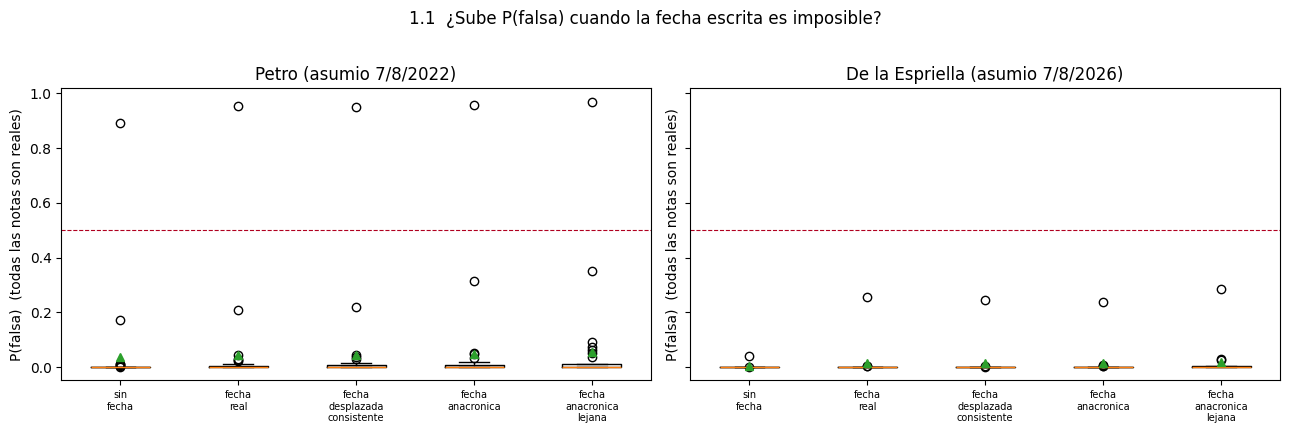

In [8]:
filas = []
for g, sem in [("A1_petro", 100), ("A1_espriella", 200)]:
    sub = a1[a1.grupo == g].pivot(index="item", columns="brazo", values="p_falsa")
    filas += [
        comparar_pareado(sub["fecha_real"], sub["fecha_anacronica"], f"{g}: fecha real -> anacronica", sem + 1),
        comparar_pareado(sub["fecha_desplazada_consistente"], sub["fecha_anacronica"], f"{g}: desplazada coherente -> anacronica", sem + 2),
        comparar_pareado(sub["fecha_real"], sub["fecha_anacronica_lejana"], f"{g}: fecha real -> anacronica lejana (2005)", sem + 3),
        comparar_pareado(sub["sin_fecha"], sub["fecha_real"], f"{g}: sin fecha -> fecha real (efecto de 'tener fecha')", sem + 4),
        comparar_pareado(sub["fecha_real"], sub["fecha_desplazada_consistente"], f"{g}: fecha real -> desplazada coherente (control)", sem + 5),
    ]
res_a1 = pd.DataFrame(filas)
print("Pruebas pareadas (mismo texto, solo cambia la fecha escrita):")
display(res_a1) if "display" in globals() else print(res_a1.to_string(index=False))

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, g, tit in zip(axs, ["A1_petro", "A1_espriella"], ["Petro (asumio 7/8/2022)", "De la Espriella (asumio 7/8/2026)"]):
    datos = [a1[(a1.grupo == g) & (a1.brazo == b)]["p_falsa"].values for b in BRAZOS_FECHA]
    ax.boxplot(datos, showmeans=True)
    ax.set_xticks(range(1, 6)); ax.set_xticklabels([b.replace("_", "\n") for b in BRAZOS_FECHA], fontsize=7)
    ax.axhline(CONFIG["umbral"], color="#b00020", lw=0.8, ls="--")
    ax.set_title(tit); ax.set_ylabel("P(falsa)  (todas las notas son reales)")
fig.suptitle("1.1  ¿Sube P(falsa) cuando la fecha escrita es imposible?", y=1.02)
fig.tight_layout(); fig.savefig(os.path.join(CONFIG["dir_salida"], "fig_1_1_fechas.png"), dpi=140, bbox_inches="tight"); plt.show()

In [9]:
# Lectura automatica (sin juicio manual): se compara la fecha anacronica contra la fecha real y contra la desplazada coherente.
def lectura_fechas(res):
    for g in ["A1_petro", "A1_espriella"]:
        r1 = res[res.comparacion.str.startswith(g + ": fecha real -> anacronica") & ~res.comparacion.str.contains("lejana")].iloc[0]
        r2 = res[res.comparacion.str.startswith(g + ": desplazada coherente")].iloc[0]
        lo, hi = [float(x) for x in r1["IC95 delta"].strip("[]").replace("+", "").split(",")]
        sube = lo > 0
        print(f"{g}: delta(anacronica - real) = {r1['delta medio']:+.4f} IC95 {r1['IC95 delta']} | "
              f"notas real->falsa: {r1['real->falsa']} (falsa->real: {r1['falsa->real']}) | "
              f"{'EL IC EXCLUYE 0: la fecha anacronica SI mueve la prediccion' if sube else 'el IC incluye 0: no hay evidencia de que el modelo use la fecha'}")
        print(f"           control coherente->anacronica: delta = {r2['delta medio']:+.4f} IC95 {r2['IC95 delta']}")
lectura_fechas(res_a1)
print("\nNota: aunque el IC excluya 0, hay que compararlo con el control 'fecha real -> desplazada coherente': "
      "si ese control se mueve igual, el modelo reacciona a que la fecha cambie, no a que sea imposible.")

A1_petro: delta(anacronica - real) = +0.0050 IC95 [+0.0004, +0.0130] | notas real->falsa: 0 (falsa->real: 0) | EL IC EXCLUYE 0: la fecha anacronica SI mueve la prediccion
           control coherente->anacronica: delta = +0.0045 IC95 [-0.0006, +0.0125]
A1_espriella: delta(anacronica - real) = -0.0004 IC95 [-0.0022, +0.0009] | notas real->falsa: 0 (falsa->real: 0) | el IC incluye 0: no hay evidencia de que el modelo use la fecha
           control coherente->anacronica: delta = +0.0000 IC95 [-0.0010, +0.0009]

Nota: aunque el IC excluya 0, hay que compararlo con el control 'fecha real -> desplazada coherente': si ese control se mueve igual, el modelo reacciona a que la fecha cambie, no a que sea imposible.


## §7 · 1.2 Poder posterior al corte: funcionarios que llegaron después del 19/09/2026

El corpus de entrenamiento llega hasta el 19/09/2026 y ya incluye a De la Espriella como presidente (ver el hallazgo 1 de la portada).
Lo que **sí** es nuevo para el modelo son las personas nombradas **después**: Alejandro Ordóñez (ministro del Interior; el cargo se anunció
el 22/10 y se posesionó el 4/11/2026, tras la salida de Rodrigo Lara), Viviane Morales (Comisionada de Paz), Ricardo Arias Macías, Thania Vega
y varios embajadores. Se miden cuatro grupos de notas **reales**:

* `A2_nuevos_funcionarios`: nombramientos y posesiones posteriores al corte (nombres nuevos en cargos nuevos);
* `CTRL_espectador_post`: política general del mismo periodo, sin esos nombres (controla "es una nota posterior al corte");
* `A1_espriella` (brazo `sin_fecha`): el presidente, ya visto en entrenamiento, con notas posteriores al corte;
* `A1_petro` (brazo `sin_fecha`): figura conocida, notas anteriores al corte.

Si el modelo desconfiara de lo nuevo, `A2` tendría más "falsas" que el control. Después se **intercambia el nombre** del ministro
en las mismas notas por (i) un ministro que el modelo sí vio (Rodrigo Lara) y (ii) un nombre inventado, para ver si importa el nombre.

In [10]:
a2 = grupo("A2_nuevos_funcionarios"); ctrl = grupo("CTRL_espectador_post")
p_a2 = p_falsa(a2["texto"]); p_ctrl = p_falsa(ctrl["texto"])
p_esp = a1[(a1.grupo == "A1_espriella") & (a1.brazo == "sin_fecha")]["p_falsa"].values
p_pet = a1[(a1.grupo == "A1_petro") & (a1.brazo == "sin_fecha")]["p_falsa"].values

tabla_a2 = pd.DataFrame([
    resumen_grupo("A2 nuevos funcionarios (post-corte)", p_a2),
    resumen_grupo("Control Espectador (post-corte)", p_ctrl),
    resumen_grupo("Presidente De la Espriella (post-corte, visto en entrenamiento)", p_esp),
    resumen_grupo("Presidente Petro (pre-corte, conocido)", p_pet),
])
display(tabla_a2) if "display" in globals() else print(tabla_a2.to_string(index=False))

def fisher_falsas(pa, pb, etiqueta):
    ka, kb = int((pa >= CONFIG["umbral"]).sum()), int((pb >= CONFIG["umbral"]).sum())
    odds, p = stats.fisher_exact([[ka, len(pa) - ka], [kb, len(pb) - kb]])
    return {"comparacion": etiqueta, "falsas A": f"{ka}/{len(pa)}", "falsas B": f"{kb}/{len(pb)}", "p Fisher exacto": round(p, 4)}
display(pd.DataFrame([fisher_falsas(p_a2, p_ctrl, "A2 nuevos funcionarios vs control (post-corte)"),
                      fisher_falsas(p_a2, p_pet, "A2 nuevos funcionarios vs Petro (pre-corte)")])) if "display" in globals() else None
u_stat, p_mw = stats.mannwhitneyu(p_a2, p_ctrl, alternative="greater")
print(f"Mann-Whitney (P(falsa) de A2 > control): U={u_stat:.0f}, p={p_mw:.4f}")

                                                          grupo  n  predichas falsas  % falsa IC95 Wilson (%)  P(falsa) media  P(falsa) mediana
                            A2 nuevos funcionarios (post-corte) 27                 0      0.0     [0.0, 12.5]          0.0236            0.0019
                                Control Espectador (post-corte) 30                 0      0.0     [0.0, 11.4]          0.0074            0.0019
Presidente De la Espriella (post-corte, visto en entrenamiento) 20                 0      0.0     [0.0, 16.1]          0.0038            0.0019
                         Presidente Petro (pre-corte, conocido) 30                 1      3.3     [0.6, 16.7]          0.0383            0.0019
Mann-Whitney (P(falsa) de A2 > control): U=395, p=0.5666


Notas de A2 que mencionan a Ordonez: 18
Ejemplo:
   original (Ordonez) | Así se mueven las fuerzas en el Congreso para debatir ley de ajuste fiscal. Las bancadas oficialistas tienen posiciones divididas respecto a
   nombre conocido (Rodrigo Lara) | Así se mueven las fuerzas en el Congreso para debatir ley de ajuste fiscal. Las bancadas oficialistas tienen posiciones divididas respecto a
   nombre inventado (Julian Barrios) | Así se mueven las fuerzas en el Congreso para debatir ley de ajuste fiscal. Las bancadas oficialistas tienen posiciones divididas respecto a
                           comparacion  n  P(falsa) antes  P(falsa) despues  delta medio         IC95 delta  real->falsa  falsa->real  p Wilcoxon  p McNemar
Ordonez -> Rodrigo Lara (nombre visto) 18          0.0112            0.0215       0.0103 [+0.0000, +0.0309]            0            0      0.0004        1.0
           Ordonez -> nombre inventado 18          0.0112            0.0230       0.0118 [-0.0000, +0.0354]        

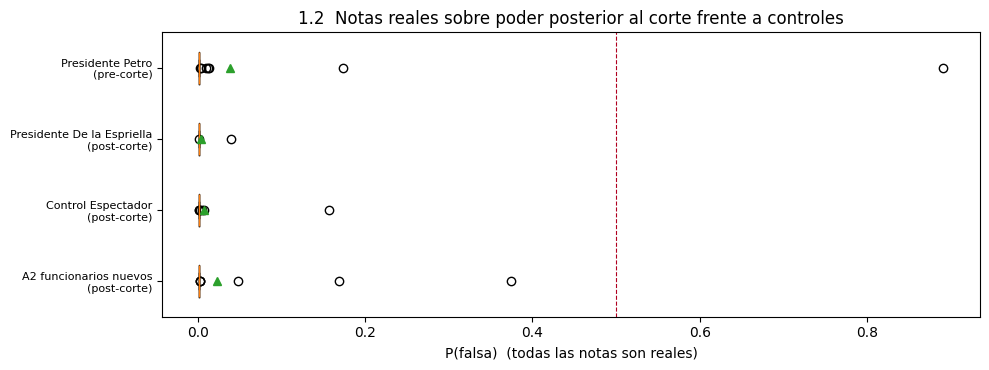

In [11]:
# Intercambio de nombre en las notas de A2 que mencionan a Ordonez: mismas frases, otro nombre.
RX_COMPLETO = r"Alejandro Ord[oó]ñez"; RX_APELLIDO = r"Ord[oó]ñez"
sel = a2[(a2["titulo"] + " " + a2["descripcion"]).str.contains(RX_APELLIDO)].reset_index(drop=True)
print(f"Notas de A2 que mencionan a Ordonez: {len(sel)}")
variantes = {
    "original (Ordonez)": lambda s: s,
    "nombre conocido (Rodrigo Lara)": lambda s: cambiar_nombre(s, RX_COMPLETO, RX_APELLIDO, "Rodrigo Lara", "Lara"),
    "nombre inventado (Julian Barrios)": lambda s: cambiar_nombre(s, RX_COMPLETO, RX_APELLIDO, "Julian Barrios", "Barrios"),
}
filas = []
for nombre_v, fn in variantes.items():
    for i, r in sel.iterrows():
        filas.append({"variante": nombre_v, "item": i, "texto": texto_modelo(fn(r["titulo"]), fn(r["descripcion"]))})
sw = pd.DataFrame(filas)
sw["p_falsa"] = p_falsa(sw["texto"])
piv = sw.pivot(index="item", columns="variante", values="p_falsa")
print("Ejemplo:"); [print("  ", r["variante"], "|", r["texto"][:140]) for _, r in sw[sw.item == 0].iterrows()]
res_sw = pd.DataFrame([
    comparar_pareado(piv["original (Ordonez)"], piv["nombre conocido (Rodrigo Lara)"], "Ordonez -> Rodrigo Lara (nombre visto)", 301),
    comparar_pareado(piv["original (Ordonez)"], piv["nombre inventado (Julian Barrios)"], "Ordonez -> nombre inventado", 302),
])
display(res_sw) if "display" in globals() else print(res_sw.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 3.8))
datos = [p_a2, p_ctrl, p_esp, p_pet]
ax.boxplot(datos, showmeans=True, vert=False)
ax.set_yticks(range(1, 5)); ax.set_yticklabels(["A2 funcionarios nuevos\n(post-corte)", "Control Espectador\n(post-corte)", "Presidente De la Espriella\n(post-corte)", "Presidente Petro\n(pre-corte)"], fontsize=8)
ax.axvline(CONFIG["umbral"], color="#b00020", lw=0.8, ls="--"); ax.set_xlabel("P(falsa)  (todas las notas son reales)")
ax.set_title("1.2  Notas reales sobre poder posterior al corte frente a controles")
fig.tight_layout(); fig.savefig(os.path.join(CONFIG["dir_salida"], "fig_1_2_poder_posterior.png"), dpi=140, bbox_inches="tight"); plt.show()

# SECCIÓN 2 · ¿Qué aprendió el modelo como "falso"?

El corpus de entrenamiento tiene una asimetría de fuentes que el README ya advierte: las **reales nuevas** vienen casi todas de
El Espectador, y las **falsas** vienen de sátira (El Chigüire Bipolar, Actualidad Panamericana) y de afirmaciones desmentidas
(Colombiacheck, Factual/AFP). Cuatro sospechas, cuatro pruebas:

1. ¿Aprendió **"El Espectador = real"**? → §8: noticias reales de otros medios reputables.
2. ¿Marca como falsa una **cifra absurda** (inflación > 15 %)? → §9.
3. ¿Marca como falso un **cargo incoherente** (vicepresidente llamado presidente)? → §10.
4. ¿Aprendió **"absurdo = falso"** de la sátira? → §11: sátira nueva frente a hechos reales extravagantes.
5. ¿Dónde mira? → §12: mapas de atención.

## §8 · 2.1 Prueba de fuente: medios reputables distintos de El Espectador

`B1_otras_fuentes` son noticias **reales** de política colombiana de otros medios. El control es `CTRL_espectador_post`
(El Espectador, mismo periodo) y, como segunda referencia, `A1_petro` sin fecha. Si la señal fuese "estilo/fuente de El Espectador",
las otras fuentes saldrían con una tasa de "falsa" claramente mayor. (Ojo: varios medios sí aparecían como reales en el
entrenamiento, aunque en mucha menor cantidad: El Tiempo, El Colombiano, Caracol, La Silla Vacía, Cambio.)

                                       grupo  n  predichas falsas  % falsa IC95 Wilson (%)  P(falsa) media  P(falsa) mediana
         Control: El Espectador (post-corte) 30                 0      0.0     [0.0, 11.4]          0.0074            0.0019
Referencia: El Espectador, Petro (pre-corte) 30                 1      3.3     [0.6, 16.7]          0.0383            0.0019
                                      cambio  8                 2     25.0     [7.1, 59.1]          0.2284            0.0084
                                  elpaiscali  8                 2     25.0     [7.1, 59.1]          0.2513            0.0020
                                     infobae  7                 3     42.9    [15.8, 75.0]          0.4657            0.2634
                                      semana  8                 2     25.0     [7.1, 59.1]          0.2864            0.1415
                     TODAS las otras fuentes 31                 9     29.0    [16.1, 46.6]          0.3028            0.0147


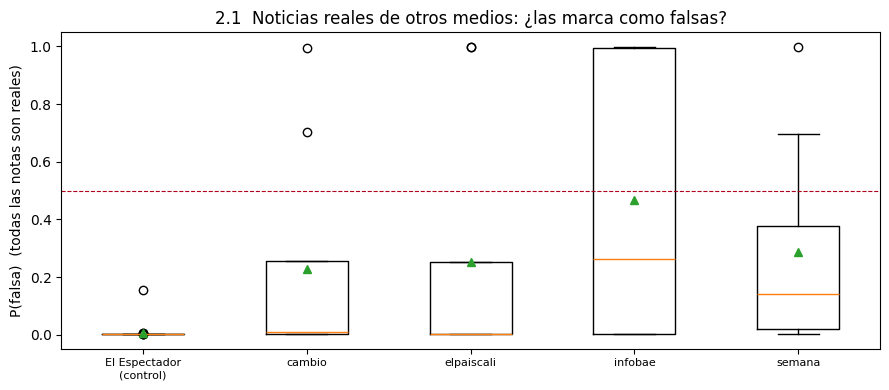

In [12]:
b1 = grupo("B1_otras_fuentes"); b1["p_falsa"] = p_falsa(b1["texto"])
filas = [resumen_grupo("Control: El Espectador (post-corte)", p_ctrl), resumen_grupo("Referencia: El Espectador, Petro (pre-corte)", p_pet)]
for fuente, sub in b1.groupby("fuente", sort=True):
    filas.append(resumen_grupo(f"{fuente}", sub["p_falsa"]))
filas.append(resumen_grupo("TODAS las otras fuentes", b1["p_falsa"]))
tabla_b1 = pd.DataFrame(filas)
display(tabla_b1) if "display" in globals() else print(tabla_b1.to_string(index=False))
print(pd.DataFrame([fisher_falsas(b1["p_falsa"].values, p_ctrl, "otras fuentes vs control Espectador"),
                    fisher_falsas(b1["p_falsa"].values, p_pet, "otras fuentes vs Espectador-Petro")]).to_string(index=False))
u_stat, p_mw = stats.mannwhitneyu(b1["p_falsa"].values, p_ctrl, alternative="greater")
print(f"Mann-Whitney (P(falsa) otras fuentes > control Espectador): p = {p_mw:.4f}")

print("\nNotas reales de otras fuentes con mayor P(falsa):")
for _, r in b1.sort_values(["p_falsa", "url"], ascending=[False, True]).head(6).iterrows():
    print(f"  {r['p_falsa']:.3f} | {r['fuente']:<11} | {r['titulo'][:110]}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot([p_ctrl] + [sub["p_falsa"].values for _, sub in b1.groupby("fuente", sort=True)], showmeans=True)
ax.set_xticks(range(1, 2 + b1["fuente"].nunique())); ax.set_xticklabels(["El Espectador\n(control)"] + sorted(b1["fuente"].unique()), fontsize=8)
ax.axhline(CONFIG["umbral"], color="#b00020", lw=0.8, ls="--"); ax.set_ylabel("P(falsa)  (todas las notas son reales)")
ax.set_title("2.1  Noticias reales de otros medios: ¿las marca como falsas?")
fig.tight_layout(); fig.savefig(os.path.join(CONFIG["dir_salida"], "fig_2_1_fuentes.png"), dpi=140, bbox_inches="tight"); plt.show()

## §9 · 2.2 Un solo componente: cifras absurdas (inflación > 15 %)

Se toman notas reales de El Espectador cuyo título o descripción trae una cifra de **inflación/IPC** entre 1 % y 12 % y se cambia **solo esa cifra**:

* `original`: la cifra real;
* `cifra_plausible`: la cifra movida entre −0,7 y +0,9 puntos (sigue siendo creíble). **Control**: ¿le molesta cualquier edición de número?;
* `cifra_absurda`: reemplazada por 18,4 / 23,7 / 31,2 / 47,9 / 62,5 / 85,3 (rotación fija) — inflación de otra galaxia para Colombia.

Si el modelo aprendió la plausibilidad numérica, `cifra_absurda` debe subir P(falsa) mucho más que `cifra_plausible`.

Notas con cifra editable: 27 de 27

Ejemplos (titulo antes -> plausible -> absurda):
  * Inflación en EE. UU. volvió a repuntar en diciembre: ¿hacia dónde van las tasas?
      plausible: Inflación en EE. UU. volvió a repuntar en diciembre: ¿hacia dónde van las tasas?
      absurda  : Inflación en EE. UU. volvió a repuntar en diciembre: ¿hacia dónde van las tasas?
  * Inflación en Colombia no llegaría a la meta en 2025, según análisis del Banrep
      plausible: Inflación en Colombia no llegaría a la meta en 2025, según análisis del Banrep
      absurda  : Inflación en Colombia no llegaría a la meta en 2025, según análisis del Banrep
  * Medellín y Armenia lideran la inflación anual: así subieron los precios por ciudades
      plausible: Medellín y Armenia lideran la inflación anual: así subieron los precios por ciudades
      absurda  : Medellín y Armenia lideran la inflación anual: así subieron los precios por ciudades
  * Inflación en Colombia: qué esperan los analistas para julio 20

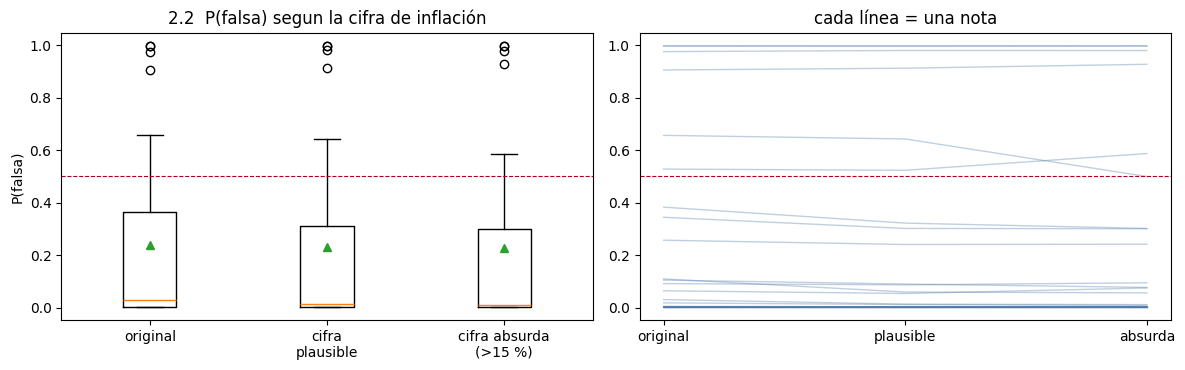

In [13]:
b2i = grupo("B2_base_inflacion")
ABSURDAS = [18.4, 23.7, 31.2, 47.9, 62.5, 85.3]
DELTAS = [0.6, -0.4, 0.9, -0.7, 0.3, -0.5, 0.8]
filas = []
for i, r in b2i.iterrows():
    cifra = cifra_inflacion(r["titulo"], r["descripcion"])
    plaus = round(min(max(cifra + DELTAS[i % len(DELTAS)], 1.0), 12.0), 1)
    if abs(plaus - cifra) < 0.05:
        plaus = round(cifra + 0.5, 1)
    absurda = ABSURDAS[i % len(ABSURDAS)]
    for brazo, v in [("original", None), ("cifra_plausible", plaus), ("cifra_absurda", absurda)]:
        if v is None:
            t, d, ok = r["titulo"], r["descripcion"], True
        else:
            t, d, ok = editar_inflacion(r["titulo"], r["descripcion"], v)
        filas.append({"item": i, "brazo": brazo, "cifra": cifra if v is None else v, "editada": ok, "titulo": t, "texto": texto_modelo(t, d)})
inf = pd.DataFrame(filas)
no_editadas = inf[(inf.brazo != "original") & (~inf.editada)]["item"].unique()
inf = inf[~inf["item"].isin(no_editadas)].copy()
print(f"Notas con cifra editable: {inf['item'].nunique()} de {len(b2i)}")
inf["p_falsa"] = p_falsa(inf["texto"])
print("\nEjemplos (titulo antes -> plausible -> absurda):")
for i in sorted(inf["item"].unique())[:4]:
    sub = inf[inf["item"] == i].set_index("brazo")
    print("  *", sub.loc["original", "titulo"][:105]); print("      plausible:", sub.loc["cifra_plausible", "titulo"][:105]); print("      absurda  :", sub.loc["cifra_absurda", "titulo"][:105])
tabla_inf = pd.DataFrame([resumen_grupo(b, inf[inf.brazo == b]["p_falsa"]) for b in ["original", "cifra_plausible", "cifra_absurda"]])
display(tabla_inf) if "display" in globals() else print(tabla_inf.to_string(index=False))
piv = inf.pivot(index="item", columns="brazo", values="p_falsa")
res_inf = pd.DataFrame([
    comparar_pareado(piv["original"], piv["cifra_plausible"], "original -> cifra plausible (control)", 401),
    comparar_pareado(piv["original"], piv["cifra_absurda"], "original -> cifra absurda (>15%)", 402),
    comparar_pareado(piv["cifra_plausible"], piv["cifra_absurda"], "plausible -> absurda", 403),
])
display(res_inf) if "display" in globals() else print(res_inf.to_string(index=False))

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
axs[0].boxplot([piv[b].values for b in ["original", "cifra_plausible", "cifra_absurda"]], showmeans=True)
axs[0].set_xticks([1, 2, 3]); axs[0].set_xticklabels(["original", "cifra\nplausible", "cifra absurda\n(>15 %)"]); axs[0].set_ylabel("P(falsa)")
axs[0].axhline(CONFIG["umbral"], color="#b00020", lw=0.8, ls="--"); axs[0].set_title("2.2  P(falsa) segun la cifra de inflación")
for _, fila in piv.iterrows():
    axs[1].plot([0, 1, 2], [fila["original"], fila["cifra_plausible"], fila["cifra_absurda"]], color="#4c78a8", alpha=0.35, lw=1)
axs[1].set_xticks([0, 1, 2]); axs[1].set_xticklabels(["original", "plausible", "absurda"]); axs[1].set_title("cada línea = una nota"); axs[1].axhline(CONFIG["umbral"], color="#b00020", lw=0.8, ls="--")
fig.tight_layout(); fig.savefig(os.path.join(CONFIG["dir_salida"], "fig_2_2_inflacion.png"), dpi=140, bbox_inches="tight"); plt.show()

## §10 · 2.3 Un solo componente: cargos incoherentes (vicepresidente → presidente)

Sobre notas reales con "vicepresidente/a" (Francia Márquez, José Manuel Restrepo) se cambia **solo el cargo**:

* `original`;
* `grafia_neutra`: "vicepresidenta" → "vice presidenta" (cambia la palabra pero no el sentido — **control** de "cualquier edición");
* `vice_llamado_presidente`: "vicepresidenta Francia Márquez" → "presidenta Francia Márquez" (incoherente: la nota habla de un gobierno con otro presidente).

Y en sentido inverso, sobre `A1_petro`: "presidente Gustavo Petro" → "vicepresidente Gustavo Petro".

Ejemplo:
   original | António Costa, Misión Creer y Pedro Sánchez: así va la agenda de Restrepo en España. El vicepresidente Restrepo lidera la Misión Crecer en España junt
   grafia_neutra | António Costa, Misión Creer y Pedro Sánchez: así va la agenda de Restrepo en España. El vice presidente Restrepo lidera la Misión Crecer en España jun
   vice_llamado_presidente | António Costa, Misión Creer y Pedro Sánchez: así va la agenda de Restrepo en España. El presidente Restrepo lidera la Misión Crecer en España junto al
                  grupo  n  predichas falsas  % falsa IC95 Wilson (%)  P(falsa) media  P(falsa) mediana
               original 30                 0      0.0     [0.0, 11.4]          0.0134            0.0019
          grafia_neutra 30                 0      0.0     [0.0, 11.4]          0.0211            0.0019
vice_llamado_presidente 30                 0      0.0     [0.0, 11.4]          0.0162            0.0019

Sentido inverso: 30 de 30 notas de A1_petro tienen 'preside

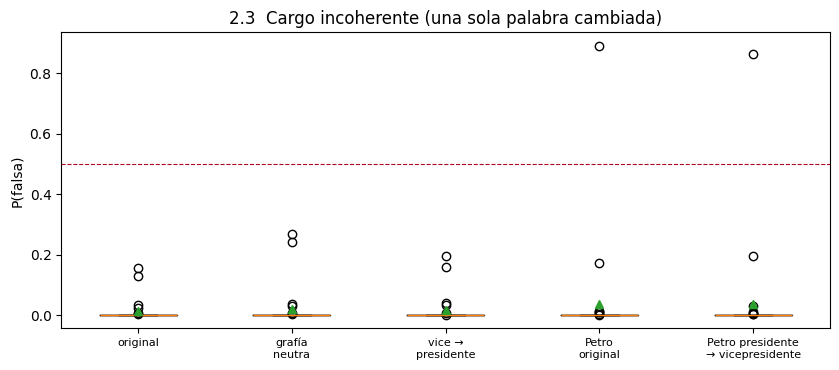

In [14]:
b2v = grupo("B2_base_vicepresidente")
filas = []
for i, r in b2v.iterrows():
    variantes = {
        "original": (r["titulo"], r["descripcion"]),
        "grafia_neutra": (_cambiar_vice(r["titulo"], neutro=True), _cambiar_vice(r["descripcion"], neutro=True)),
        "vice_llamado_presidente": (_cambiar_vice(r["titulo"]), _cambiar_vice(r["descripcion"])),
    }
    for brazo, (t, d) in variantes.items():
        filas.append({"item": i, "brazo": brazo, "titulo": t, "texto": texto_modelo(t, d)})
vp = pd.DataFrame(filas)
vp["p_falsa"] = p_falsa(vp["texto"])
print("Ejemplo:"); [print("  ", r["brazo"], "|", r["texto"][:150]) for _, r in vp[vp["item"] == 0].iterrows()]
tabla_vp = pd.DataFrame([resumen_grupo(b, vp[vp.brazo == b]["p_falsa"]) for b in ["original", "grafia_neutra", "vice_llamado_presidente"]])
display(tabla_vp) if "display" in globals() else print(tabla_vp.to_string(index=False))
piv = vp.pivot(index="item", columns="brazo", values="p_falsa")
filas_res = [
    comparar_pareado(piv["original"], piv["grafia_neutra"], "original -> grafia neutra (control)", 501),
    comparar_pareado(piv["original"], piv["vice_llamado_presidente"], "original -> vice llamado presidente", 502),
]

# sentido inverso: Petro (presidente) llamado vicepresidente
pet = grupo("A1_petro")
t0 = [texto_modelo(r["titulo"], r["descripcion"]) for _, r in pet.iterrows()]
t1 = [texto_modelo(presidente_a_vice(r["titulo"]), presidente_a_vice(r["descripcion"])) for _, r in pet.iterrows()]
cambiadas = [i for i, (a, b) in enumerate(zip(t0, t1)) if a != b]
print(f"\nSentido inverso: {len(cambiadas)} de {len(pet)} notas de A1_petro tienen 'presidente ... Petro' editable")
pa = p_falsa([t0[i] for i in cambiadas]); pb = p_falsa([t1[i] for i in cambiadas])
filas_res.append(comparar_pareado(pa, pb, "Petro: presidente -> vicepresidente", 503))
res_vp = pd.DataFrame(filas_res)
display(res_vp) if "display" in globals() else print(res_vp.to_string(index=False))

fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.boxplot([piv["original"], piv["grafia_neutra"], piv["vice_llamado_presidente"], pa, pb], showmeans=True)
ax.set_xticks(range(1, 6)); ax.set_xticklabels(["original", "grafía\nneutra", "vice →\npresidente", "Petro\noriginal", "Petro presidente\n→ vicepresidente"], fontsize=8)
ax.axhline(CONFIG["umbral"], color="#b00020", lw=0.8, ls="--"); ax.set_ylabel("P(falsa)"); ax.set_title("2.3  Cargo incoherente (una sola palabra cambiada)")
fig.tight_layout(); fig.savefig(os.path.join(CONFIG["dir_salida"], "fig_2_3_cargos.png"), dpi=140, bbox_inches="tight"); plt.show()

## §11 · 2.4 Sátira frente a hechos reales extravagantes

Tres grupos de textos "ridículos" más el control de noticias normales:

* `B3_satira_mismos_sitios` (**falsa**): sátira **nueva** de El Chigüire Bipolar y Actualidad Panamericana, las dos fuentes de sátira del entrenamiento;
* `B3_satira_sitios_nuevos` (**falsa**): sátira de El Mundo Today y El Deforma, sitios que el modelo **nunca** vio;
* `B3_real_extravagante` (**real**): hechos verdaderos pero absurdos o bochornosos, publicados por medios reputables (consulado fantasma en Tijuana, un caballo en el Congreso, una parranda vallenata en una cárcel, congresistas dormidos, récords de ministros que duran días...);
* `CTRL_espectador_post` (**real**): noticias normales.

Lectura: si aprendió **"absurdo = falso"**, `B3_real_extravagante` saldría marcada como falsa casi tanto como la sátira. Si aprendió **estilo satírico**, la sátira se detectaría y lo real extravagante no. Si solo aprendió **fuente**, la sátira de sitios nuevos pasaría como real.
Se reporta además el **AUC** de P(falsa) para separar sátira de lo real extravagante.

                                grupo  n  predichas falsas  % falsa IC95 Wilson (%)  P(falsa) media  P(falsa) mediana etiqueta real  acierto %
    Control: noticias reales normales 30                 0      0.0     [0.0, 11.4]          0.0074            0.0019          real      100.0
Real extravagante (medios reputables) 34                27     79.4    [63.2, 89.7]          0.7572            0.9867          real       20.6
       Satira - mismos sitios (nueva) 27                26     96.3    [81.7, 99.3]          0.9543            0.9987         falsa       96.3
               Satira - sitios nuevos 26                21     80.8    [62.1, 91.5]          0.7893            0.9987         falsa       80.8
AUC satira (todas) vs real extravagante : 0.662   (0.5 = no los distingue, 1.0 = los separa por completo)
AUC satira sitios nuevos vs real extrav.: 0.588
AUC satira (todas) vs control normal    : 0.989
AUC real extravagante vs control normal : 0.984   (>0.5 = lo extravagante parece ma

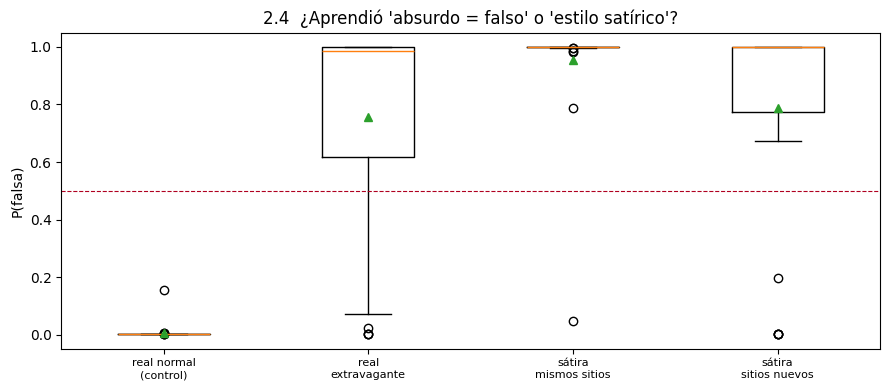

In [15]:
b3a = grupo("B3_satira_mismos_sitios"); b3b = grupo("B3_satira_sitios_nuevos"); b3c = grupo("B3_real_extravagante")
for d in (b3a, b3b, b3c):
    d["p_falsa"] = p_falsa(d["texto"])

tabla_b3 = pd.DataFrame([
    {**resumen_grupo("Control: noticias reales normales", p_ctrl), "etiqueta real": "real", "acierto %": round(100 - resumen_grupo("x", p_ctrl)["% falsa"], 1)},
    {**resumen_grupo("Real extravagante (medios reputables)", b3c["p_falsa"]), "etiqueta real": "real", "acierto %": round(100 - resumen_grupo("x", b3c["p_falsa"])["% falsa"], 1)},
    {**resumen_grupo("Satira - mismos sitios (nueva)", b3a["p_falsa"]), "etiqueta real": "falsa", "acierto %": resumen_grupo("x", b3a["p_falsa"])["% falsa"]},
    {**resumen_grupo("Satira - sitios nuevos", b3b["p_falsa"]), "etiqueta real": "falsa", "acierto %": resumen_grupo("x", b3b["p_falsa"])["% falsa"]},
])
display(tabla_b3) if "display" in globals() else print(tabla_b3.to_string(index=False))

def auc(pos, neg):
    # AUC = P(P(falsa) de un positivo > la de un negativo), via Mann-Whitney (empates cuentan 0.5)
    u = stats.mannwhitneyu(pos, neg, alternative="two-sided").statistic
    return u / (len(pos) * len(neg))
sat_todas = np.concatenate([b3a["p_falsa"].values, b3b["p_falsa"].values])
print(f"AUC satira (todas) vs real extravagante : {auc(sat_todas, b3c['p_falsa'].values):.3f}   (0.5 = no los distingue, 1.0 = los separa por completo)")
print(f"AUC satira sitios nuevos vs real extrav.: {auc(b3b['p_falsa'].values, b3c['p_falsa'].values):.3f}")
print(f"AUC satira (todas) vs control normal    : {auc(sat_todas, p_ctrl):.3f}")
print(f"AUC real extravagante vs control normal : {auc(b3c['p_falsa'].values, p_ctrl):.3f}   (>0.5 = lo extravagante parece mas falso que lo normal)")
print(pd.DataFrame([fisher_falsas(b3c["p_falsa"].values, p_ctrl, "real extravagante vs control normal")]).to_string(index=False))

print("\nReales extravagantes que el modelo marca como falsas (mayor P(falsa)):")
for _, r in b3c.sort_values(["p_falsa", "url"], ascending=[False, True]).head(6).iterrows():
    print(f"  {r['p_falsa']:.3f} | {r['fuente']:<10} | {r['titulo'][:105]}")
print("\nSatira que el modelo deja pasar como real (menor P(falsa)):")
for _, r in pd.concat([b3a, b3b]).sort_values(["p_falsa", "url"]).head(6).iterrows():
    print(f"  {r['p_falsa']:.3f} | {r['fuente']:<10} | {r['titulo'][:105]}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot([p_ctrl, b3c["p_falsa"].values, b3a["p_falsa"].values, b3b["p_falsa"].values], showmeans=True)
ax.set_xticks([1, 2, 3, 4]); ax.set_xticklabels(["real normal\n(control)", "real\nextravagante", "sátira\nmismos sitios", "sátira\nsitios nuevos"], fontsize=8)
ax.axhline(CONFIG["umbral"], color="#b00020", lw=0.8, ls="--"); ax.set_ylabel("P(falsa)"); ax.set_title("2.4  ¿Aprendió 'absurdo = falso' o 'estilo satírico'?")
fig.tight_layout(); fig.savefig(os.path.join(CONFIG["dir_salida"], "fig_2_4_satira.png"), dpi=140, bbox_inches="tight"); plt.show()

## §12 · 2.5 Mapas de atención

Se toman **titulares cortos** (los 2 más cortos, en tokens, de cada grupo: real normal, real extravagante, sátira de sitios nuevos y
sátira de los mismos sitios) y dos del experimento de inflación (el titular más corto con cifra, original y con cifra absurda).
Para cada uno se extraen las **144 matrices de atención** (12 capas × 12 cabezas, `T × T` cada una) y se **superponen promediándolas**
en un solo mapa de calor: la fila `i` es "desde qué token se mira" y la columna `j` "hacia qué token".

Cómo leerlo: la diagonal brillante = cada token se mira a sí mismo; una **columna brillante** = un token que concentra la atención
de todos los demás (típicamente `<s>` y `</s>`, que RoBERTa usa como "sumidero"); las manchas fuera de eso son relaciones entre palabras.

> **Advertencia (Jain & Wallace, 2019; Serrano & Smith, 2019):** la atención describe cómo se mezclan los vectores dentro del modelo, **no
> prueba qué palabras causaron la decisión**. Es una pista para formular hipótesis, que se contrastan con las ediciones de §9–§11.

Maxima diferencia P(falsa) sin relleno vs relleno a 128: 2.98e-07
Forma de las matrices: (12, 12, 15, 15)  -> 144 matrices 15x15 por titular



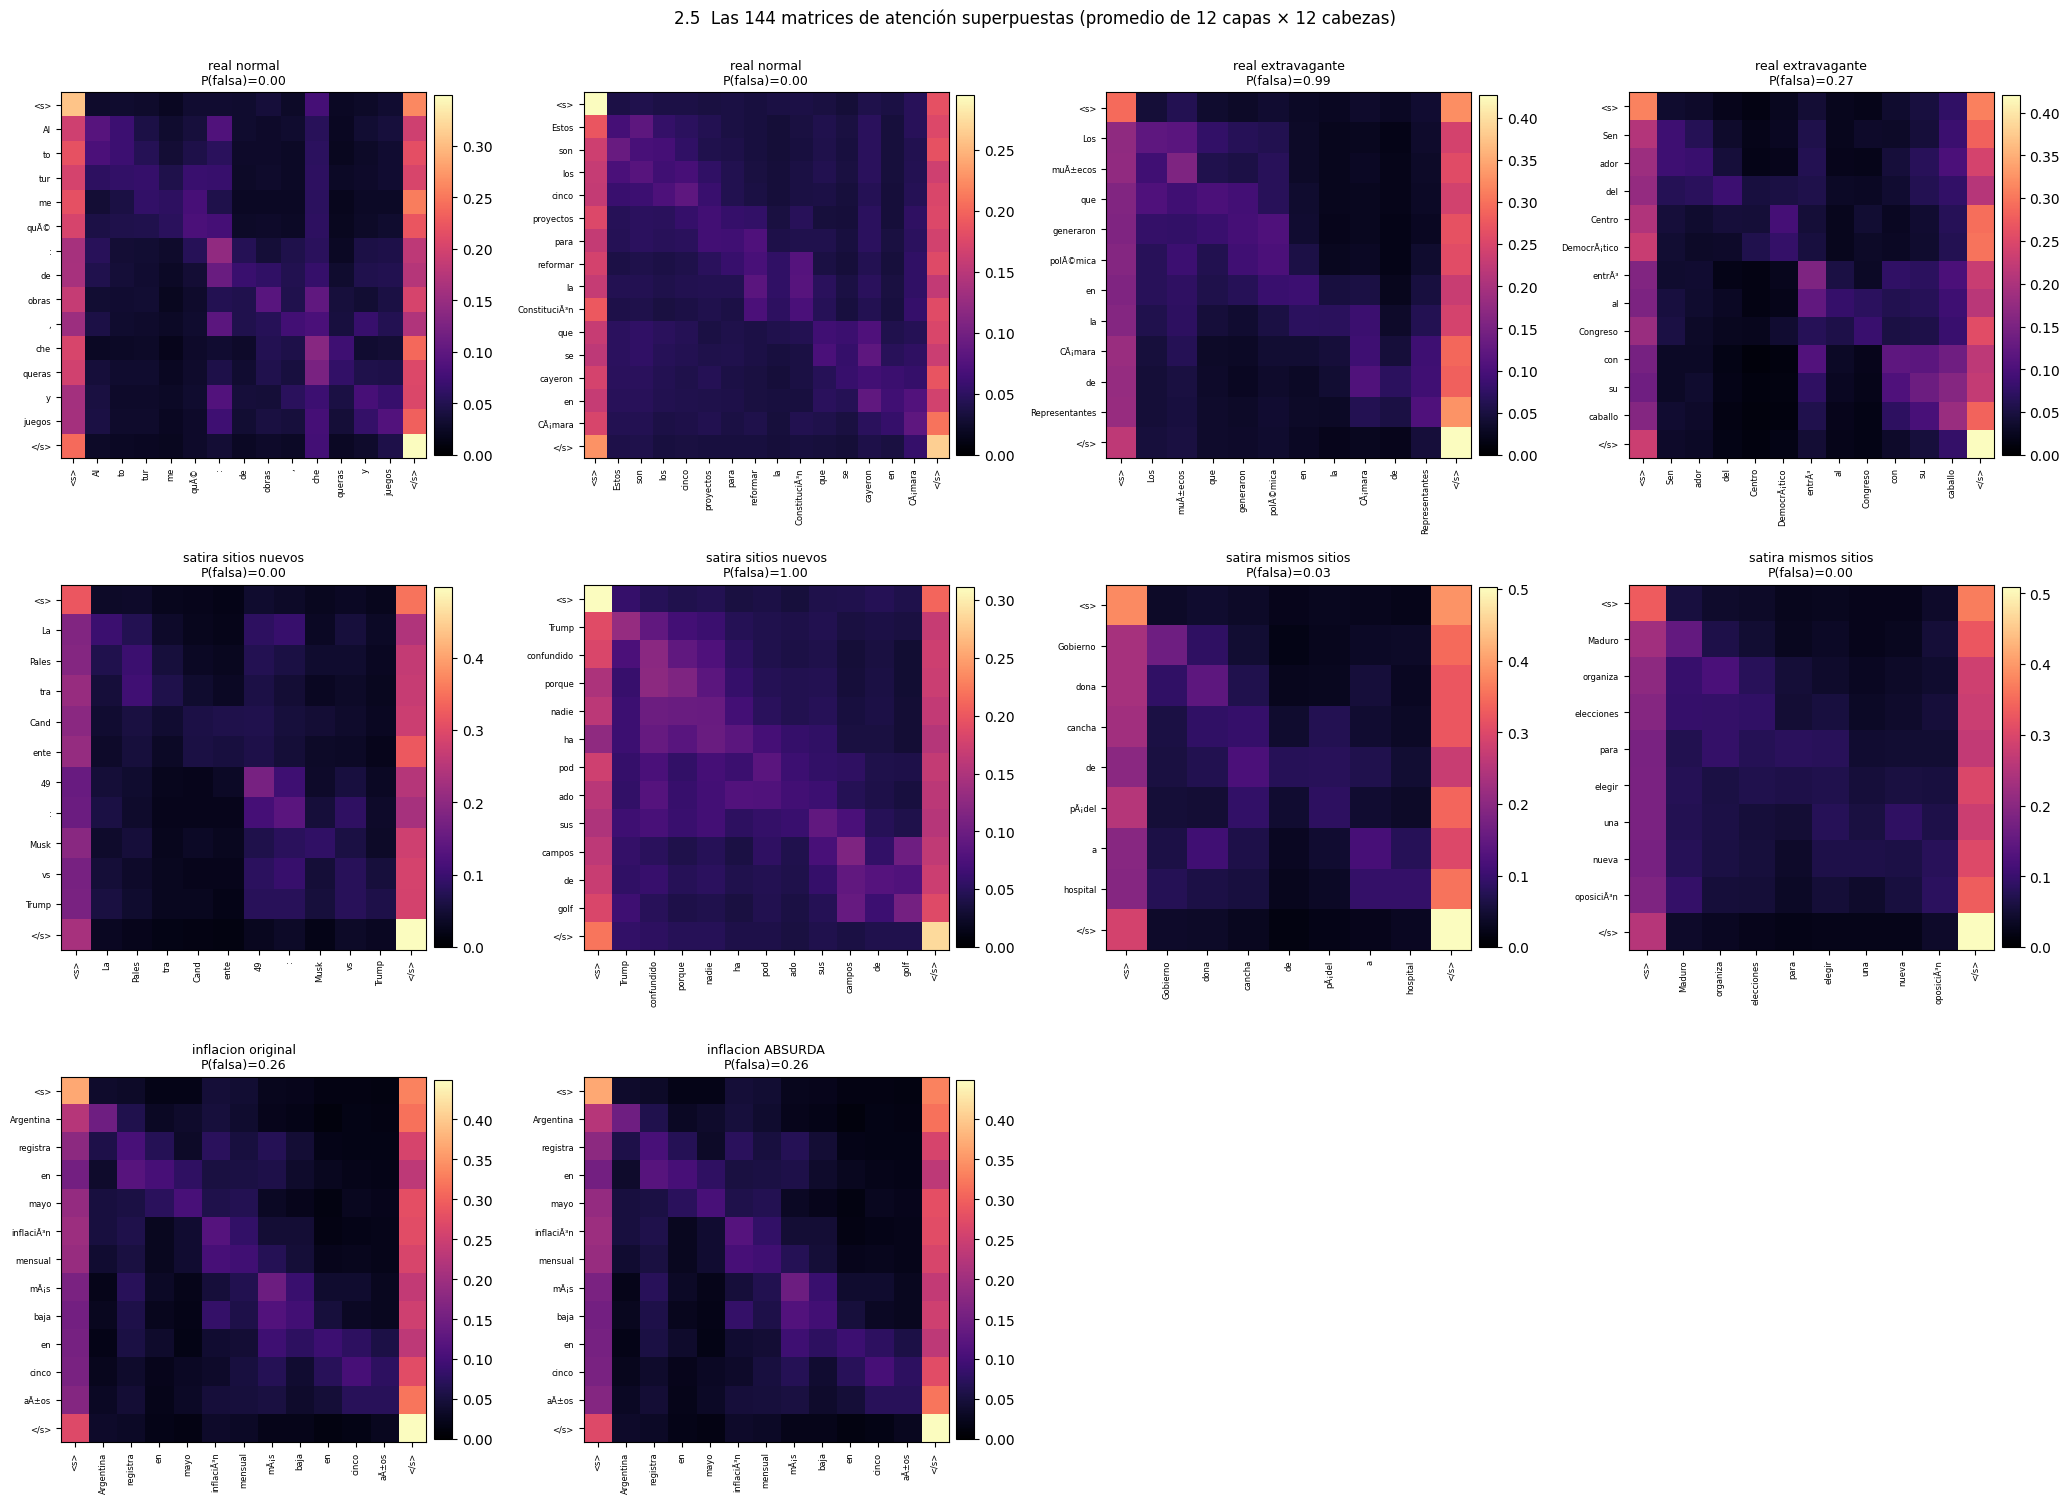

[real normal           ] P(falsa)=0.002 | Alto turmequé: de obras, chequeras y juegos
[real normal           ] P(falsa)=0.002 | Estos son los cinco proyectos para reformar la Constitución que se cayeron en Cámara
[real extravagante     ] P(falsa)=0.993 | Los muñecos que generaron polémica en la Cámara de Representantes
[real extravagante     ] P(falsa)=0.266 | Senador del Centro Democrático entró al Congreso con su caballo
[satira sitios nuevos  ] P(falsa)=0.004 | La Palestra Candente 49: Musk vs Trump
[satira sitios nuevos  ] P(falsa)=0.999 | Trump confundido porque nadie ha podado sus campos de golf
[satira mismos sitios  ] P(falsa)=0.027 | Gobierno dona cancha de pádel a hospital
[satira mismos sitios  ] P(falsa)=0.002 | Maduro organiza elecciones para elegir una nueva oposición
[inflacion original    ] P(falsa)=0.262 | Argentina registra en mayo inflación mensual más baja en cinco años
[inflacion ABSURDA     ] P(falsa)=0.262 | Argentina registra en mayo inflación mensual más baja e

In [16]:
def n_tokens(t):
    return len(tokenizer.tokenize(t))

def titulares_para_atencion():
    lista = []
    for etiqueta, df in [("real normal", ctrl), ("real extravagante", b3c), ("satira sitios nuevos", b3b), ("satira mismos sitios", b3a)]:
        d = df.assign(n_tok=[n_tokens(t) for t in df["titulo"]]).sort_values(["n_tok", "url"]).head(2)
        lista += [(etiqueta, r["titulo"]) for _, r in d.iterrows()]
    absurdas = inf[inf.brazo == "cifra_absurda"].assign(n_tok=lambda x: [n_tokens(t) for t in x["titulo"]]).sort_values(["n_tok", "item"])
    i0 = absurdas.iloc[0]["item"]
    lista.append(("inflacion original", inf[(inf["item"] == i0) & (inf.brazo == "original")].iloc[0]["titulo"]))
    lista.append(("inflacion ABSURDA", inf[(inf["item"] == i0) & (inf.brazo == "cifra_absurda")].iloc[0]["titulo"]))
    return lista

def atenciones(titular):
    enc = tokenizer(titular, truncation=True, max_length=MAX_LEN, return_tensors="tf")      # sin relleno: solo tokens reales
    out = modelo(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"], output_attentions=True, training=False)
    att = np.stack([a.numpy()[0] for a in out.attentions])                                # [capas, cabezas, T, T]
    toks = [t.replace("Ġ", "") or "_" for t in tokenizer.convert_ids_to_tokens(enc["input_ids"][0].numpy())]
    p = float(tf.nn.softmax(tf.cast(out.logits, tf.float32), axis=-1).numpy()[0, IDX_FALSA])
    return att, toks, p

TITULARES = titulares_para_atencion()
ATT = [atenciones(t) for _, t in TITULARES]
# control: sin relleno vs con relleno a 128 deben dar (casi) la misma prediccion
dif = max(abs(a[2] - p_falsa([t], usar_cache=False)[0]) for a, (_, t) in zip(ATT, TITULARES))
print(f"Maxima diferencia P(falsa) sin relleno vs relleno a {MAX_LEN}: {dif:.2e}")
print(f"Forma de las matrices: {ATT[0][0].shape}  -> {ATT[0][0].shape[0]*ATT[0][0].shape[1]} matrices {ATT[0][0].shape[2]}x{ATT[0][0].shape[3]} por titular\n")

n = len(TITULARES); cols = 4; filas_f = math.ceil(n / cols)
fig, axs = plt.subplots(filas_f, cols, figsize=(5.2 * cols, 5.0 * filas_f))
axs = np.atleast_1d(axs).ravel()
for ax, (etq, titular), (att, toks, p) in zip(axs, TITULARES, ATT):
    sobrepuesto = att.mean(axis=(0, 1))                       # las 144 matrices superpuestas
    im = ax.imshow(sobrepuesto, cmap="magma", vmin=0)
    ax.set_xticks(range(len(toks))); ax.set_xticklabels(toks, rotation=90, fontsize=6)
    ax.set_yticks(range(len(toks))); ax.set_yticklabels(toks, fontsize=6)
    ax.set_title(f"{etq}\nP(falsa)={p:.2f}", fontsize=9)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
for ax in axs[n:]:
    ax.axis("off")
fig.suptitle("2.5  Las 144 matrices de atención superpuestas (promedio de 12 capas × 12 cabezas)", y=1.0, fontsize=12)
fig.tight_layout(); fig.savefig(os.path.join(CONFIG["dir_salida"], "fig_2_5_atencion_superpuesta.png"), dpi=130, bbox_inches="tight"); plt.show()
for (etq, t), (att, toks, p) in zip(TITULARES, ATT):
    print(f"[{etq:<22}] P(falsa)={p:.3f} | {t}")

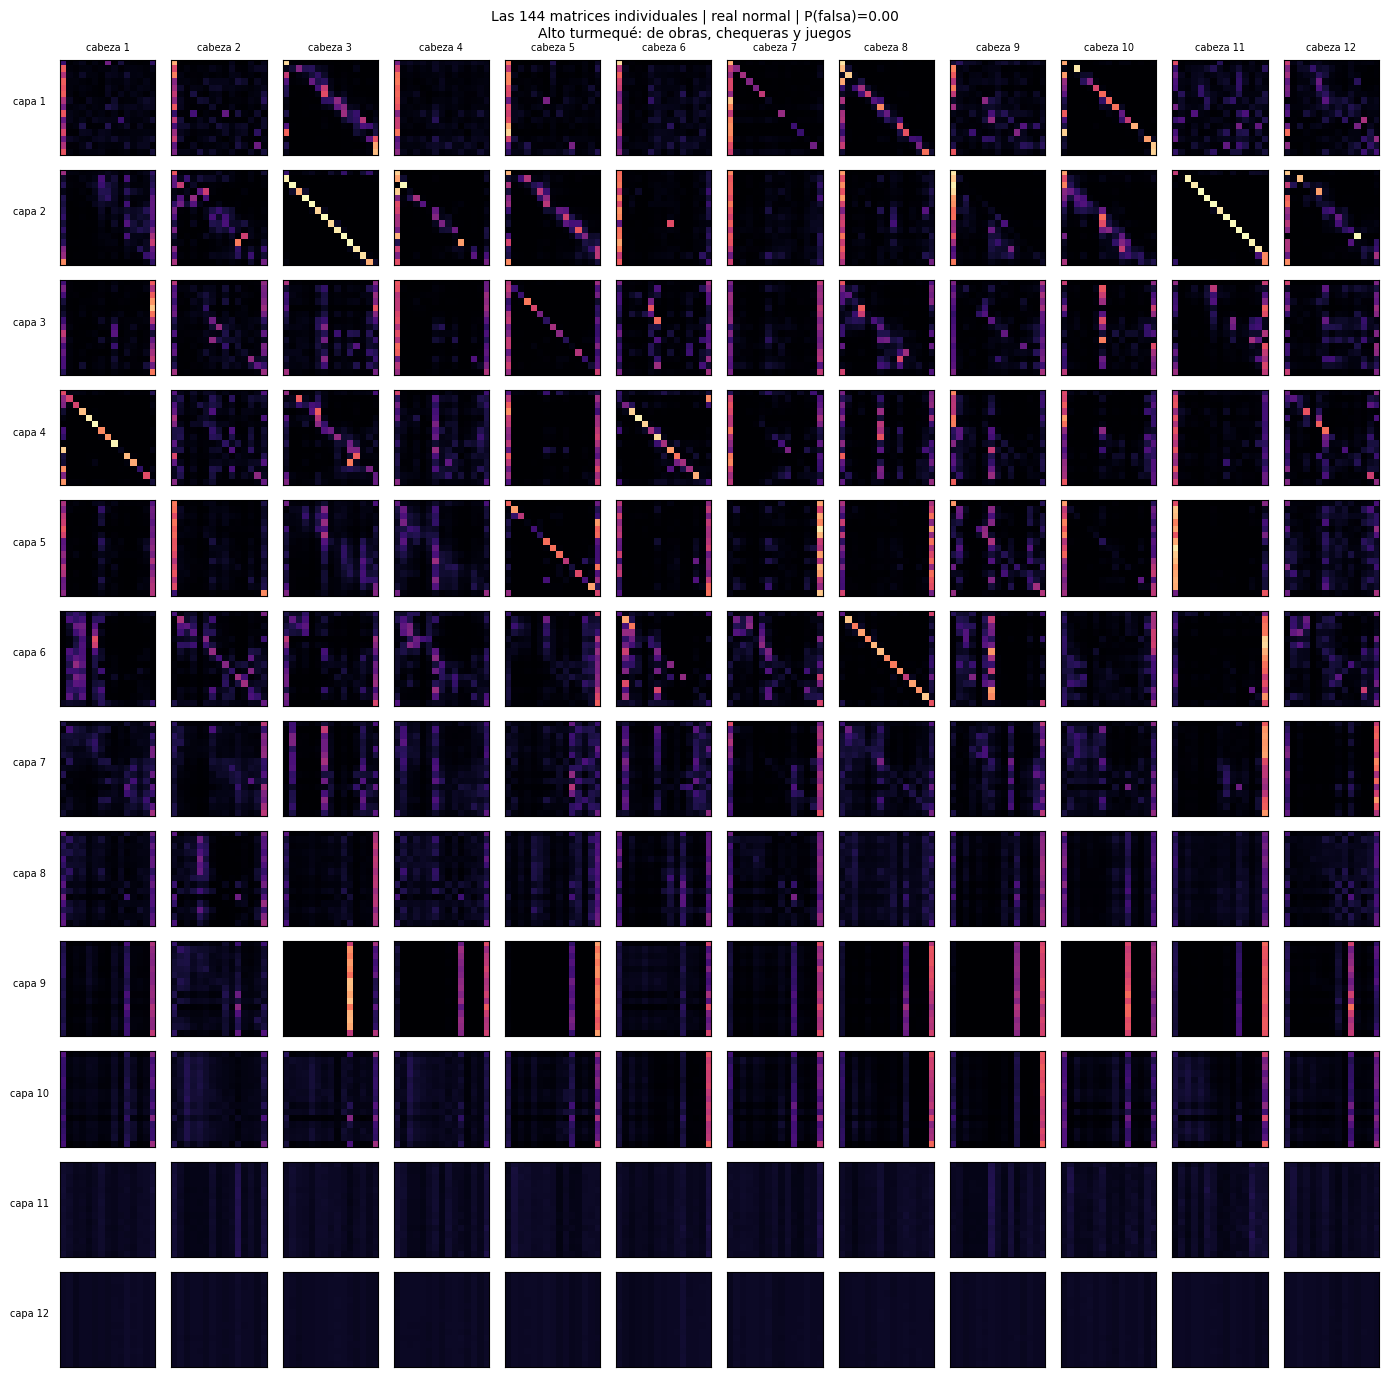

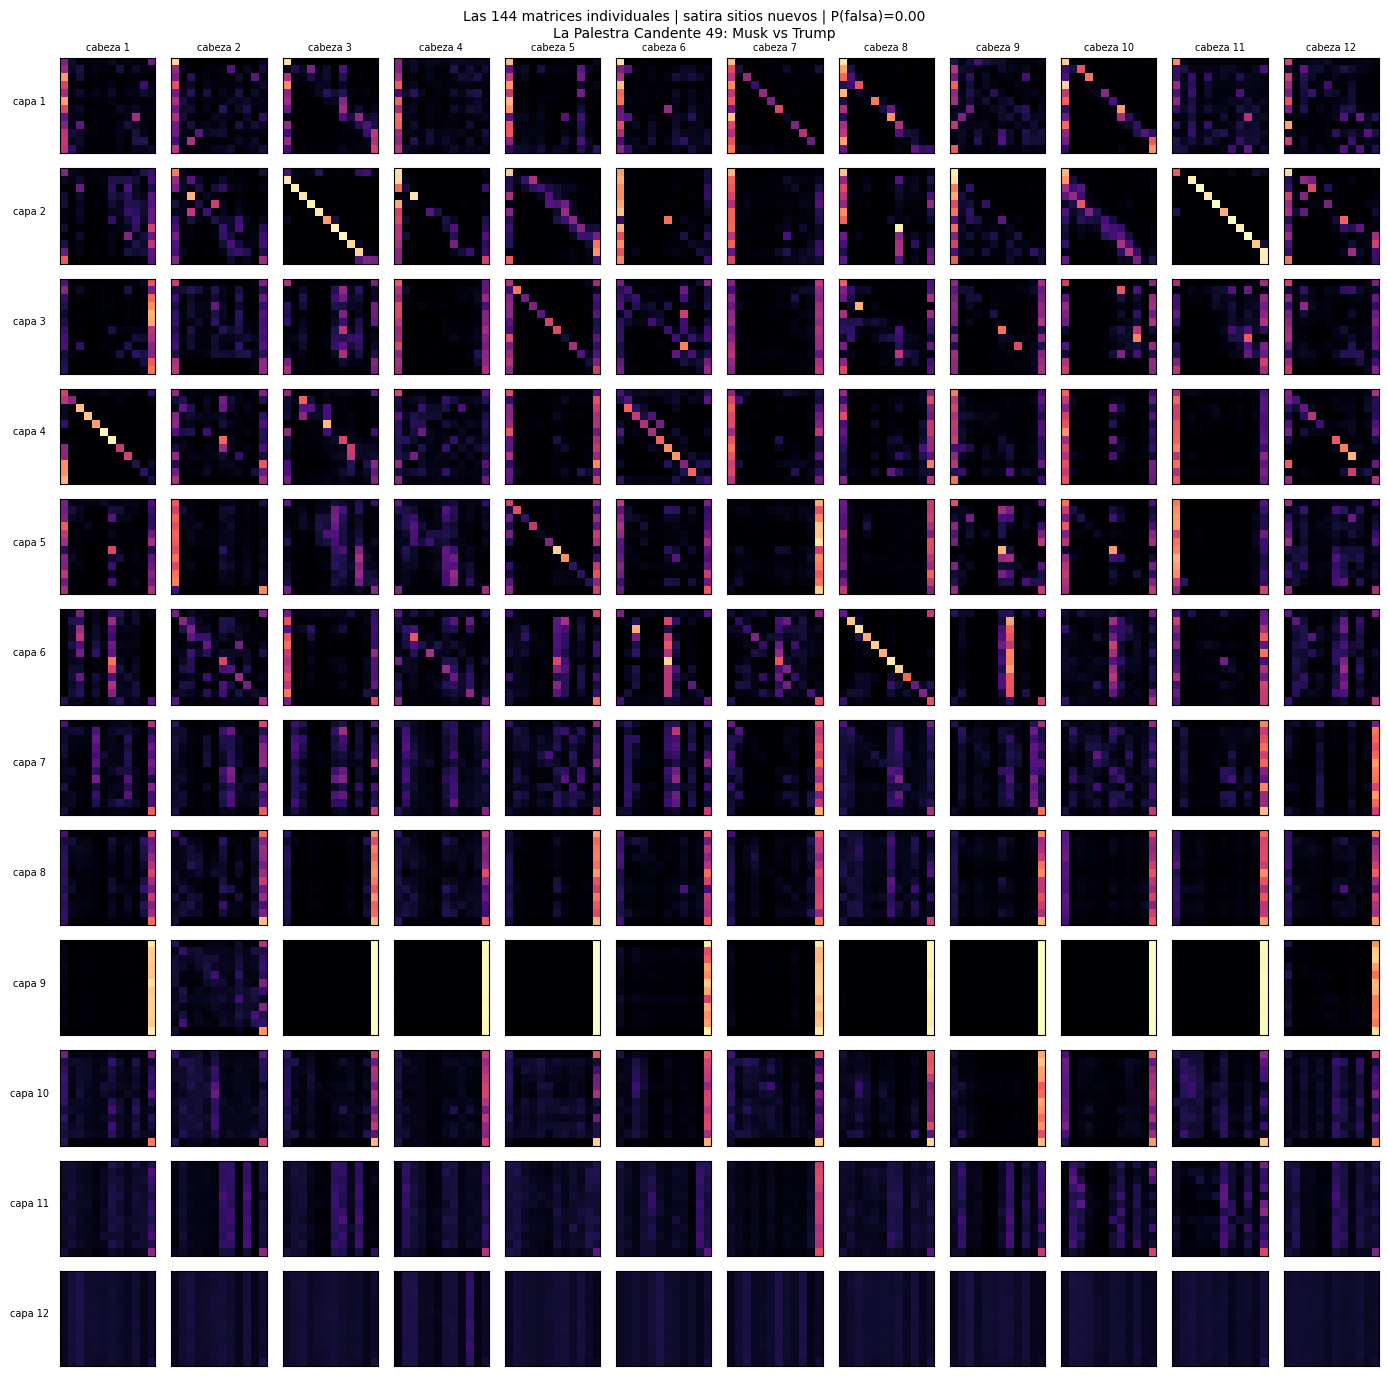

In [17]:
# Las 144 matrices por separado (capas en filas, cabezas en columnas) para los dos primeros titulares distintos de grupo.
def grilla_144(indice):
    etq, titular = TITULARES[indice]; att, toks, p = ATT[indice]
    L, H = att.shape[:2]
    fig, axs = plt.subplots(L, H, figsize=(14, 14))
    for l in range(L):
        for h in range(H):
            axs[l, h].imshow(att[l, h], cmap="magma", vmin=0, vmax=1); axs[l, h].set_xticks([]); axs[l, h].set_yticks([])
            if h == 0: axs[l, h].set_ylabel(f"capa {l+1}", fontsize=7, rotation=0, labelpad=22)
            if l == 0: axs[l, h].set_title(f"cabeza {h+1}", fontsize=7)
    fig.suptitle(f"Las 144 matrices individuales | {etq} | P(falsa)={p:.2f}\n{titular}", fontsize=10)
    fig.tight_layout(); fig.savefig(os.path.join(CONFIG["dir_salida"], f"fig_2_5_grilla_144_{indice}.png"), dpi=110, bbox_inches="tight"); plt.show()
grilla_144(0)                       # real normal
grilla_144(4)                       # satira de sitios nuevos

             titular  tokens  P(falsa)  % atencion a <s>  % atencion a </s>  % a palabras  entropia normalizada token mas atendido (palabra)
         real normal      15     0.002         19.799999          22.100000     58.099998                 0.683                          che
         real normal      16     0.002         17.799999          18.100000     64.000000                 0.762                      cayeron
   real extravagante      12     0.993         18.500000          28.500000     53.099998                 0.665                     muÃ±ecos
   real extravagante      13     0.266         19.100000          26.799999     54.200001                 0.619                      caballo
satira sitios nuevos      12     0.004         20.000000          29.600000     50.400002                 0.638                           49
satira sitios nuevos      13     0.999         18.000000          17.900000     64.099998                 0.766                   confundido
satira mismos

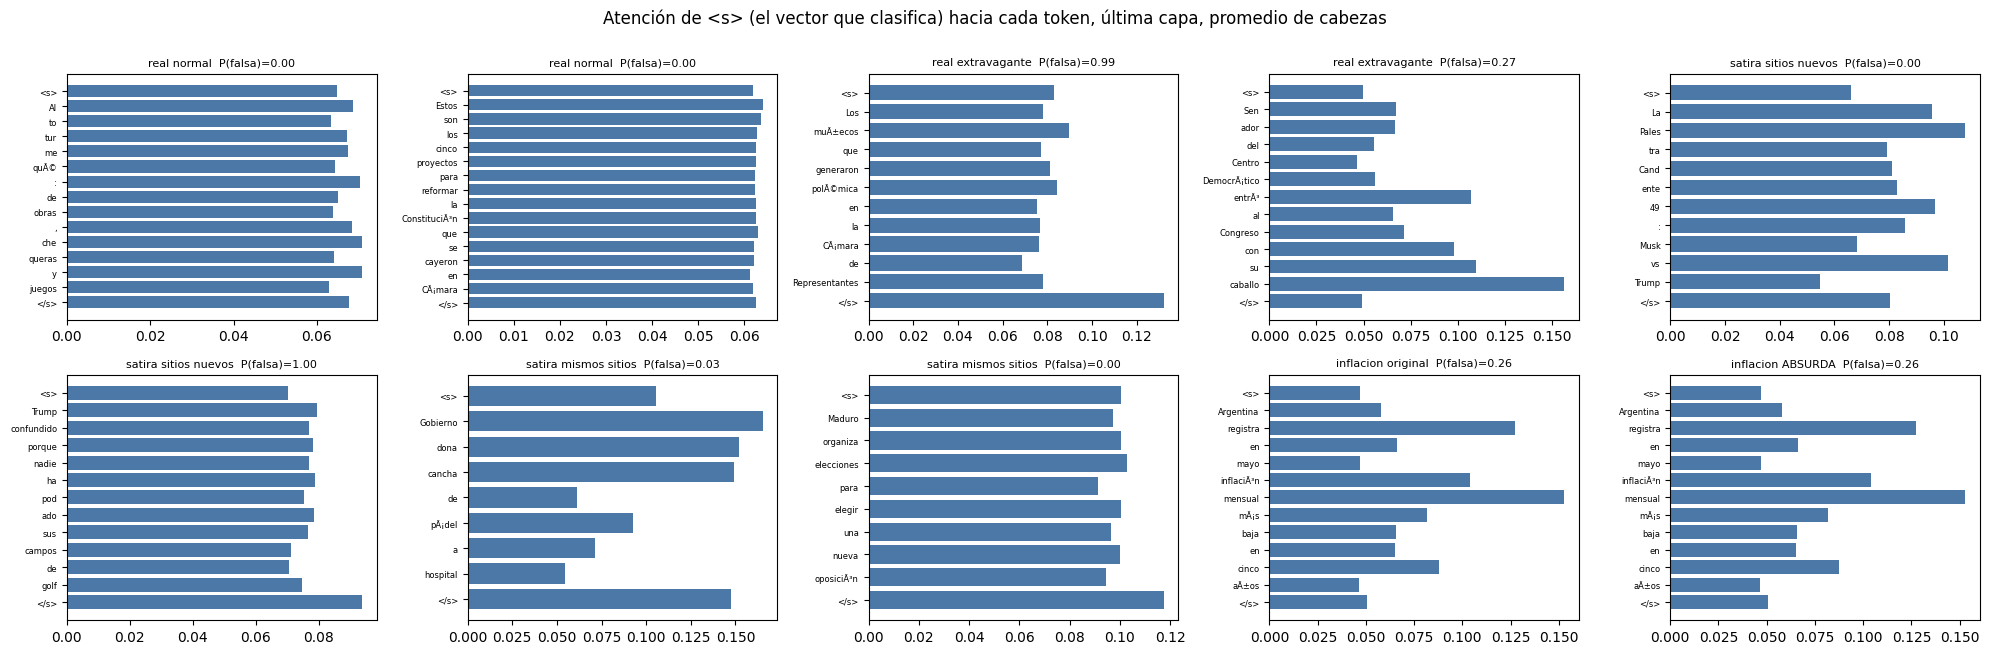

In [18]:
# Cuantificacion de lo que se superpone: reparto de la atencion (promedio de las 144 matrices) entre <s>, </s> y palabras.
filas = []
for (etq, titular), (att, toks, p) in zip(TITULARES, ATT):
    por_columna = att.mean(axis=(0, 1)).mean(axis=0)          # atencion recibida por cada token (promedio sobre filas)
    T = len(toks)
    ent = -(att * np.log(att + 1e-12)).sum(axis=-1).mean() / math.log(T)     # entropia normalizada media por fila
    cls_ultima = att[-1].mean(axis=0)[0]                       # ultima capa, promedio de cabezas, fila <s>
    filas.append({"titular": etq, "tokens": T, "P(falsa)": round(p, 3),
                  "% atencion a <s>": round(100 * por_columna[0], 1), "% atencion a </s>": round(100 * por_columna[-1], 1),
                  "% a palabras": round(100 * por_columna[1:-1].sum(), 1), "entropia normalizada": round(float(ent), 3),
                  "token mas atendido (palabra)": toks[1 + int(np.argmax(por_columna[1:-1]))]})
res_att = pd.DataFrame(filas)
display(res_att) if "display" in globals() else print(res_att.to_string(index=False))

fig, axs = plt.subplots(2, 5, figsize=(20, 6.5))
for ax, (etq, titular), (att, toks, p) in zip(axs.ravel(), TITULARES, ATT):
    v = att[-1].mean(axis=0)[0]                                 # ultima capa, promedio de cabezas, <s> -> tokens
    ax.barh(range(len(toks)), v, color="#4c78a8"); ax.set_yticks(range(len(toks))); ax.set_yticklabels(toks, fontsize=6); ax.invert_yaxis()
    ax.set_title(f"{etq}  P(falsa)={p:.2f}", fontsize=8)
fig.suptitle("Atención de <s> (el vector que clasifica) hacia cada token, última capa, promedio de cabezas", y=1.0)
fig.tight_layout(); fig.savefig(os.path.join(CONFIG["dir_salida"], "fig_2_5_cls_ultima_capa.png"), dpi=120, bbox_inches="tight"); plt.show()

# SECCIÓN 3 · Comparación 1:1 con el método de validación del artículo

## §13 · El protocolo del artículo (Blanco-Fernández et al., 2024) y lo que se puede reproducir

El artículo valida su RoBERTa-BNE de **tres** maneras (copia del PDF: `referencias/Blanco-Fernandez_2024_articulo.pdf`):

| # | Validación del artículo | Dónde | Resultado reportado | ¿Se puede replicar aquí? |
|---|---|---|---|---|
| 1 | Partición de prueba del 20 % de su propio corpus (57.231 noticias, fakes sintéticas) | §5.2, Cuadro 6 | exactitud **0,986**, F1 0,988, MCC 0,971 | Aquí el equivalente es la prueba del propio proyecto (corpus colombiano, otro corpus): se cita, no se recalcula (los datos de prueba no son esta entrada) |
| 2 | 63 titulares **no sintéticos** (debates electorales de España, julio 2023) | §5.2.1 | exactitud **0,71** | **No**: los 63 titulares no están publicados. Lo más cercano son los chequeos de Colombiacheck posteriores al corte (solo salieron falsos/cuestionables → recall) |
| 3 | Comparación con la literatura | §5.2.2, **Cuadro 7** | ver abajo | **Parcialmente**: solo las filas con datos públicos en español |

El propio artículo aclara (§5.2.2) que sus modelos y los de la literatura **no se evaluaron sobre los mismos datos**: las líneas base
se entrenaron y probaron dentro de cada corpus. Aquí se hace lo más cercano a "1:1": evaluar **este** modelo, sin reentrenarlo, sobre **esos mismos corpus**
y poner la misma métrica (exactitud) junto a los números del Cuadro 7.

### Cuadro 7 del artículo, fila por fila

| Fila (referencia) | Datos | Idioma | Técnica y exactitud | ¿Reproducible aquí? |
|---|---|---|---|---|
| [12] | Fakes1000 (Tretiakov), 2.000 | español | RF 74,25 · XGBoost 64,25 · Reg. logística 77 | **Sí** (Kaggle; requiere token) |
| [14] | Spanish Fake News Corpus (Posadas-Durán), 971 | español (México) | SVM 81 · Naive Bayes 59 · KNN 81 · Árbol 62 | **Sí** (GitHub público) |
| [42] | corpus extraído de [34,43], 2.500 | español | BETO 80 | **Parcial**: la mezcla exacta no está publicada; se evalúan sus dos fuentes (Fakes1000 y FakesStorage) |
| [13] | conjunto no publicado, 634 | español | RF 89,8 · BERT 95,8 | No (no publicado) |
| [33] | FakeNewsNet, 23.000 | **inglés** | dos BERT paralelos 85,4 | No (otro idioma; un modelo en español no es evaluable) |
| [15] | EXIST (sexismo), 13.000 | inglés/español | BERT 76,83 | No (otra tarea: sexismo, no desinformación) |
| [16] | IMDB, tweets de desastres, noticias en portugués, reseñas en chino | otros | BERT 93,87 / 83,64 / 91,20 / 93,81 | No (otras tareas e idiomas) |
| Artículo, validación 1 | su corpus sintético, 57.231 | español | RoBERTa-BNE **98,6** | Ver fila "prueba propia" abajo |
| Artículo, validación 2 | 63 titulares de debates 2023 | español | RoBERTa-BNE **71** | No (no publicado) |

Además, el artículo reporta (Cuadro 5) que los modelos **sin** ajustar rinden como el azar (exactitud 0,44-0,59, MCC≈0).

In [19]:
# Cuadro 7 del articulo (p. 21 del PDF): exactitudes reportadas. Solo las filas reproducibles con datos publicos.
BASELINES_ARTICULO = {
    "Fakes1000 (Tretiakov) [12]": {"n_articulo": 2000, "modelos": {"Random Forest": 0.7425, "XGBoost": 0.6425, "Regresion logistica": 0.77}},
    "Spanish Fake News Corpus (Posadas-Duran) [14]": {"n_articulo": 971, "modelos": {"SVM": 0.81, "Naive Bayes": 0.59, "KNN (k=3)": 0.81, "Arbol de decision": 0.62}},
    "Corpus de [34,43] (Martinez-Gallego) [42]": {"n_articulo": 2500, "modelos": {"BETO": 0.80}},
}
ARTICULO_PROPIO = {"validacion_1_exactitud": 0.986, "validacion_2_exactitud_63_titulares": 0.71}
# Prueba propia del proyecto (split de prueba del corpus colombiano), de salida_bayesiana/mejores_hiperparametros.json
PRUEBA_PROPIA = {"accuracy": 0.951, "f1_macro": 0.951, "mcc": 0.9026, "fuente": "constante tomada de salida_bayesiana/mejores_hiperparametros.json"}
for cand in [os.path.join(os.path.dirname(os.path.abspath(RUTA_MODELO)), "mejores_hiperparametros.json"),
             os.path.join(os.path.abspath(RUTA_MODELO), "mejores_hiperparametros.json"), "salida_bayesiana/mejores_hiperparametros.json"]:
    if os.path.exists(cand):
        with open(cand, encoding="utf-8") as f:
            m = json.load(f)["metricas_test"]
        PRUEBA_PROPIA = {"accuracy": m["accuracy"], "f1_macro": m["f1_macro"], "mcc": m["mcc"], "fuente": cand}
        break
print("Prueba propia del proyecto (split de prueba, corpus colombiano):", PRUEBA_PROPIA)

Prueba propia del proyecto (split de prueba, corpus colombiano): {'accuracy': 0.951, 'f1_macro': 0.951, 'mcc': 0.9026, 'fuente': '/content/entrada_modelo/mejores_hiperparametros.json'}


## §14 · Datos externos y evaluación sin reentrenar

Se descargan, dentro del notebook, los corpus públicos del Cuadro 7:

* **Spanish Fake News Corpus** (Posadas-Durán et al., 2019): `train.xlsx` + `development.xlsx` (971 noticias) y, como extra, **FakeDeS/IberLEF 2021** (`test.xlsx`, 572) — [github.com/jpposadas/FakeNewsCorpusSpanish](https://github.com/jpposadas/FakeNewsCorpusSpanish);
* **Fakes1000** (Tretiakov, 2.000 noticias, 1.000 + 1.000) — [Kaggle: arseniitretiakov/noticias-falsas-en-espaol](https://www.kaggle.com/datasets/arseniitretiakov/noticias-falsas-en-espaol). **Requiere un token de Kaggle** (variable `KAGGLE_API_TOKEN`, secreto de Colab, o se pide por teclado). Sin token se omite y se avisa;
* **FakesStorage** (Bugoi et al.): titulares de **solo falsas** desmentidas por Maldita.es y Newtral.es — [github.com/alcorpas10/FakesStorage](https://github.com/alcorpas10/FakesStorage). Al ser solo falsas, solo se mide *recall* de la clase falsa. (Se omite FactCheck.org: está en inglés.)
* **Colombiacheck posterior al corte** (§4): afirmaciones falsas/cuestionables posteriores al 19/09/2026; solo *recall*.

Texto que ve el modelo: `titular + ". " + cuerpo` truncado a 128 tokens (igual que en el entrenamiento). Etiqueta: 1 = real, 0 = falsa.

In [20]:
from sklearn.metrics import accuracy_score, f1_score, matthews_corrcoef, confusion_matrix

def descargar_bytes(url, cabeceras=None, timeout=180):
    req = Request(url, headers={"User-Agent": UA, **(cabeceras or {})})
    with urlopen(req, timeout=timeout) as r:
        return r.read()

def token_kaggle():
    t = os.environ.get("KAGGLE_API_TOKEN")
    if not t:
        try:
            from google.colab import userdata
            t = userdata.get("KAGGLE_API_TOKEN")
        except Exception:
            t = None
    if not t:
        try:
            import getpass
            t = getpass.getpass("Token de Kaggle para bajar Fakes1000 (Enter para omitir): ").strip() or None
        except Exception:
            t = None
    return t

def _texto_ext(df, col_t, col_x):
    t = df[col_t].fillna("").astype(str).str.strip() if col_t else pd.Series([""] * len(df), index=df.index)
    x = df[col_x].fillna("").astype(str).str.strip()
    return [texto_modelo(a, b) if a else b for a, b in zip(t, x)]

BASE_GH = "https://raw.githubusercontent.com/jpposadas/FakeNewsCorpusSpanish/master/"
EXTERNOS = {}          # nombre -> dict(textos, y (1 real/0 falsa) o None si solo falsas)

try:
    tr = pd.read_excel(io.BytesIO(descargar_bytes(BASE_GH + "train.xlsx")))
    dv = pd.read_excel(io.BytesIO(descargar_bytes(BASE_GH + "development.xlsx")))
    sfnc = pd.concat([tr, dv], ignore_index=True)
    y = sfnc["Category"].map({"Fake": 0, "True": 1})
    ok = y.notna()
    EXTERNOS["Spanish Fake News Corpus (Posadas-Duran) [14]"] = dict(textos=_texto_ext(sfnc[ok], "Headline", "Text"), y=y[ok].astype(int).values)
    fk = pd.read_excel(io.BytesIO(descargar_bytes(BASE_GH + "test.xlsx")))
    yf = fk["CATEGORY"].map({False: 0, True: 1, "False": 0, "True": 1, "Fake": 0})
    okf = yf.notna()
    EXTERNOS["FakeDeS / IberLEF 2021 (extra, no esta en el Cuadro 7)"] = dict(textos=_texto_ext(fk[okf], "HEADLINE", "TEXT"), y=yf[okf].astype(int).values)
except Exception as e:
    print("No se pudo bajar el corpus de Posadas-Duran / FakeDeS:", type(e).__name__, str(e)[:100])

tk = token_kaggle()
if tk:
    try:
        z = zipfile.ZipFile(io.BytesIO(descargar_bytes(
            "https://www.kaggle.com/api/v1/datasets/download/arseniitretiakov/noticias-falsas-en-espaol",
            {"Authorization": "Bearer " + tk})))
        f1k = pd.read_csv(z.open("fakes1000.csv"))
        EXTERNOS["Fakes1000 (Tretiakov) [12]"] = dict(textos=_texto_ext(f1k, None, "Text"), y=f1k["class"].map({True: 1, False: 0}).astype(int).values)
    except Exception as e:
        print("No se pudo bajar Fakes1000 de Kaggle (revisa el token):", type(e).__name__, str(e)[:100])
else:
    print("Sin token de Kaggle: se omite Fakes1000.")

try:
    titulos = []
    for nombre in ["fakenewsMaldita.json", "fakenewsNewtral.json"]:
        d = json.loads(descargar_bytes("https://raw.githubusercontent.com/alcorpas10/FakesStorage/HEAD/datatsets/" + nombre).decode("utf-8"))
        titulos += [v["titulo"].strip() for k, v in d.items() if v.get("titulo", "").strip()]
    titulos = list(dict.fromkeys(titulos))           # sin duplicados, conservando el orden
    EXTERNOS["FakesStorage ES (Maldita + Newtral) -- solo falsas"] = dict(textos=titulos, y=None)
except Exception as e:
    print("No se pudo bajar FakesStorage:", type(e).__name__, str(e)[:100])

cc = grupo("C_colombiacheck_post_corte")
EXTERNOS["Colombiacheck post-corte (falsas/cuestionables) -- solo falsas"] = dict(textos=[t for t in cc["titulo"]], y=None)

for k, v in EXTERNOS.items():
    print(f"{k:<66} n={len(v['textos']):>5}" + (f"  (reales={int(v['y'].sum())}, falsas={int((1 - v['y']).sum())})" if v["y"] is not None else "  (solo falsas)"))

Spanish Fake News Corpus (Posadas-Duran) [14]                      n=  971  (reales=491, falsas=480)
FakeDeS / IberLEF 2021 (extra, no esta en el Cuadro 7)             n=  572  (reales=286, falsas=286)
Fakes1000 (Tretiakov) [12]                                         n= 2000  (reales=1000, falsas=1000)
FakesStorage ES (Maldita + Newtral) -- solo falsas                 n= 6925  (solo falsas)
Colombiacheck post-corte (falsas/cuestionables) -- solo falsas     n=    0  (solo falsas)


In [21]:
def metricas_externas(nombre, textos, y):
    p = p_falsa(textos)
    y_pred = np.where(p >= CONFIG["umbral"], 0, 1)
    if y is None:                                   # solo falsas: recall de la clase falsa
        k = int((y_pred == 0).sum()); lo, hi = wilson(k, len(y_pred))
        return {"conjunto": nombre, "n": len(y_pred), "exactitud / recall falsa": round(k / len(y_pred), 4),
                "IC95 Wilson": f"[{lo:.4f}, {hi:.4f}]", "F1 macro": None, "MCC": None, "recall falsa": round(k / len(y_pred), 4), "recall real": None,
                "exactitud trivial (clase mayoritaria)": None, "_k": k}
    k = int((y_pred == y).sum()); lo, hi = wilson(k, len(y))
    cm = confusion_matrix(y, y_pred, labels=[0, 1])
    return {"conjunto": nombre, "n": len(y), "exactitud / recall falsa": round(k / len(y), 4), "IC95 Wilson": f"[{lo:.4f}, {hi:.4f}]",
            "F1 macro": round(f1_score(y, y_pred, average="macro", zero_division=0), 4), "MCC": round(matthews_corrcoef(y, y_pred), 4),
            "recall falsa": round(cm[0, 0] / max(1, cm[0].sum()), 4), "recall real": round(cm[1, 1] / max(1, cm[1].sum()), 4),
            "exactitud trivial (clase mayoritaria)": round(max(y.mean(), 1 - y.mean()), 4), "_k": k}

# Salvavidas: un conjunto vacio o que falle no tumba la celda ni pierde el resto (las predicciones ya calculadas
# quedan en _CACHE_PRED, asi que volver a ejecutar la celda es casi instantaneo). El conjunto omitido se avisa
# y la §15 lo marca como "NO EVALUADO".
res_ext, omitidos_ext = [], {}
for k, v in EXTERNOS.items():
    n_txt = len(v["textos"])
    if n_txt == 0:
        omitidos_ext[k] = "0 textos (descarga vacia, columna de etiquetas con otro formato o raspado sin resultados)"; continue
    if v["y"] is not None and len(v["y"]) != n_txt:
        omitidos_ext[k] = f"textos ({n_txt}) y etiquetas ({len(v['y'])}) no coinciden"; continue
    if v["y"] is not None and len(set(v["y"].tolist())) < 2:
        print(f"AVISO: {k} tiene una sola clase en las etiquetas; F1/MCC no son informativos.")
    try:
        res_ext.append(metricas_externas(k, v["textos"], v["y"]))
    except Exception as e:
        omitidos_ext[k] = f"{type(e).__name__}: {str(e)[:120]}"
for k, motivo in omitidos_ext.items():
    print(f"OMITIDO: {k} -> {motivo}")
tabla_ext = pd.DataFrame(res_ext, columns=list(res_ext[0].keys()) if res_ext else ["conjunto", "n", "exactitud / recall falsa", "_k"])
display(tabla_ext.drop(columns="_k")) if "display" in globals() else print(tabla_ext.drop(columns="_k").to_string(index=False))

OMITIDO: Colombiacheck post-corte (falsas/cuestionables) -- solo falsas -> 0 textos (descarga vacia, columna de etiquetas con otro formato o raspado sin resultados)
                                              conjunto    n  exactitud / recall falsa      IC95 Wilson  F1 macro    MCC  recall falsa  recall real  exactitud trivial (clase mayoritaria)
         Spanish Fake News Corpus (Posadas-Duran) [14]  971                    0.5026 [0.4712, 0.5340]    0.3504 0.0805        0.9979       0.0183                                 0.5057
FakeDeS / IberLEF 2021 (extra, no esta en el Cuadro 7)  572                    0.5035 [0.4626, 0.5443]    0.3470 0.0343        0.9930       0.0140                                 0.5000
                            Fakes1000 (Tretiakov) [12] 2000                    0.5960 [0.5743, 0.6173]    0.5583 0.2365        0.8880       0.3040                                 0.5000
    FakesStorage ES (Maldita + Newtral) -- solo falsas 6925                    0.8368 [0.82

## §15 · Veredicto 1:1 frente al Cuadro 7

Para cada conjunto con líneas base en el artículo: exactitud de **este** modelo (con IC 95 % de Wilson) contra cada línea base. Regla fija:

* **supera** a una línea base si el **límite inferior** del IC del modelo es mayor que la exactitud reportada de esa línea;
* **no concluyente** si la exactitud del modelo es mayor pero el IC incluye a la línea base;
* **no supera** si la exactitud del modelo es menor o igual.

Es una regla conservadora: las exactitudes de la literatura son valores puntuales (sin IC) sobre cortes de prueba que no conocemos.
**Leer con cuidado:** las líneas base se *entrenaron dentro* de cada corpus; este modelo nunca vio ninguno (transferencia desde política colombiana),
así que perder aquí no invalida el ajuste, y ganar no demuestra superioridad general (el propio artículo hace la misma salvedad en §5.2.2).

                        conjunto del articulo  n evaluado          linea base  exactitud articulo  exactitud este modelo      IC95 Wilson veredicto  p binomial (H1: acc > base)                                                                                    nota
                   Fakes1000 (Tretiakov) [12]        2000       Random Forest              0.7425                 0.5960 [0.5743, 0.6173] no supera                          1.0                                                                                        
                   Fakes1000 (Tretiakov) [12]        2000             XGBoost              0.6425                 0.5960 [0.5743, 0.6173] no supera                          1.0                                                                                        
                   Fakes1000 (Tretiakov) [12]        2000 Regresion logistica              0.7700                 0.5960 [0.5743, 0.6173] no supera                          1.0                             

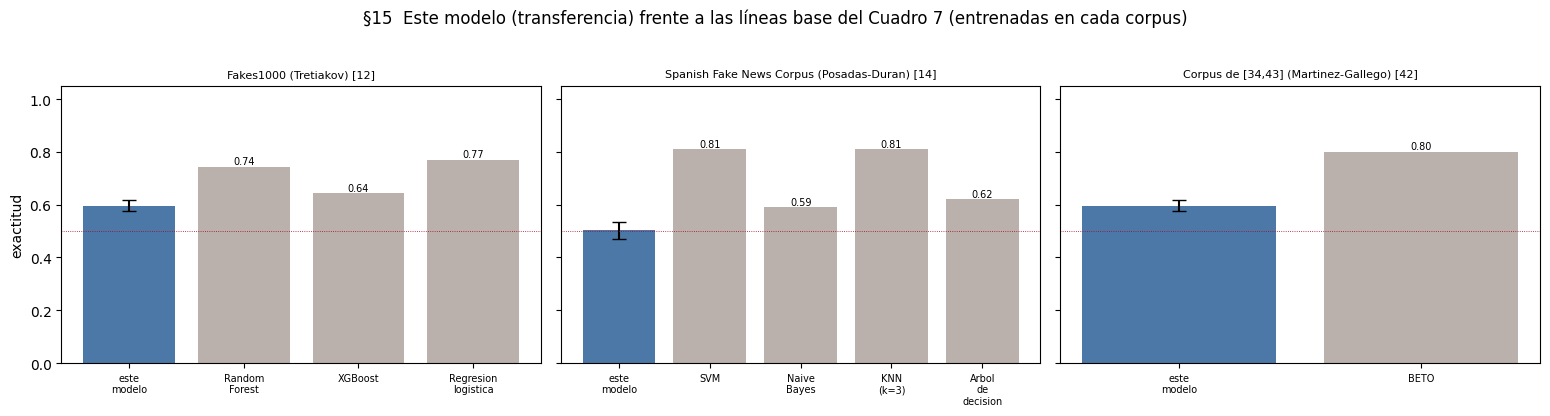

In [22]:
filas, veredictos = [], []
for conjunto, info in BASELINES_ARTICULO.items():
    if conjunto.startswith("Corpus de [34,43]"):
        fuentes = [r for r in res_ext if r["conjunto"].startswith("Fakes1000")]
        nota = "mezcla exacta no publicada: se usa Fakes1000 (una de sus dos fuentes) como aproximacion"
    else:
        fuentes = [r for r in res_ext if r["conjunto"] == conjunto]
        nota = ""
    if not fuentes:
        filas.append({"conjunto del articulo": conjunto, "estado": "NO EVALUADO (datos no disponibles en esta corrida)"}); continue
    r = fuentes[0]
    k, n = r["_k"], r["n"]; acc = k / n; lo, hi = wilson(k, n)
    for modelo_b, ex in info["modelos"].items():
        if lo > ex:
            v = "SUPERA"
        elif acc > ex:
            v = "no concluyente (IC incluye a la linea base)"
        else:
            v = "no supera"
        p_bin = stats.binomtest(k, n, ex, alternative="greater").pvalue
        filas.append({"conjunto del articulo": conjunto, "n evaluado": n, "linea base": modelo_b, "exactitud articulo": ex,
                      "exactitud este modelo": round(acc, 4), "IC95 Wilson": f"[{lo:.4f}, {hi:.4f}]", "veredicto": v,
                      "p binomial (H1: acc > base)": round(p_bin, 4), "nota": nota})
tabla_veredicto = pd.DataFrame(filas)
display(tabla_veredicto) if "display" in globals() else print(tabla_veredicto.to_string(index=False))

# Filas propias (no son lineas base del Cuadro 7 pero son el resto del protocolo del articulo)
print("\nProtocolo completo del articulo frente a este proyecto:")
print(f"  Validacion 1 (corte de prueba de SU corpus sintetico):       articulo exactitud {ARTICULO_PROPIO['validacion_1_exactitud']:.3f}")
print(f"  Prueba propia de este proyecto (corte de prueba, corpus colombiano): exactitud {PRUEBA_PROPIA['accuracy']:.3f}, F1 macro {PRUEBA_PROPIA['f1_macro']:.3f}, MCC {PRUEBA_PROPIA['mcc']:.3f}   [{PRUEBA_PROPIA['fuente']}]")
print(f"  Validacion 2 (63 titulares reales, otro dominio):             articulo exactitud {ARTICULO_PROPIO['validacion_2_exactitud_63_titulares']:.2f}")
for r in res_ext:
    if r["conjunto"].startswith(("Spanish", "Fakes1000", "FakeDeS")):
        print(f"  Este modelo sobre {r['conjunto'][:55]:<55} exactitud {r['exactitud / recall falsa']:.3f}  (n={r['n']})")

# Figura: exactitud de este modelo (con IC) frente a las lineas base del Cuadro 7
conjuntos = [c for c in BASELINES_ARTICULO if any(r["conjunto"] == c or (c.startswith("Corpus de") and r["conjunto"].startswith("Fakes1000")) for r in res_ext)]
if conjuntos:
    fig, axs = plt.subplots(1, len(conjuntos), figsize=(5.2 * len(conjuntos), 4), sharey=True)
    axs = np.atleast_1d(axs)
    for ax, c in zip(axs, conjuntos):
        r = [x for x in res_ext if x["conjunto"] == c or (c.startswith("Corpus de") and x["conjunto"].startswith("Fakes1000"))][0]
        acc = r["_k"] / r["n"]; lo, hi = wilson(r["_k"], r["n"])
        ax.bar(0, acc, yerr=[[acc - lo], [hi - acc]], color="#4c78a8", capsize=5, label="este modelo (sin reentrenar)")
        for j, (mb, ex) in enumerate(BASELINES_ARTICULO[c]["modelos"].items(), start=1):
            ax.bar(j, ex, color="#bab0ac"); ax.text(j, ex + 0.01, f"{ex:.2f}", ha="center", fontsize=7)
        ax.set_xticks(range(len(BASELINES_ARTICULO[c]["modelos"]) + 1)); ax.set_xticklabels(["este\nmodelo"] + [m.replace(" ", "\n") for m in BASELINES_ARTICULO[c]["modelos"]], fontsize=7)
        ax.set_title(c, fontsize=8); ax.set_ylim(0, 1.05); ax.axhline(0.5, color="#b00020", lw=0.6, ls=":")
    axs[0].set_ylabel("exactitud")
    fig.suptitle("§15  Este modelo (transferencia) frente a las líneas base del Cuadro 7 (entrenadas en cada corpus)", y=1.03)
    fig.tight_layout(); fig.savefig(os.path.join(CONFIG["dir_salida"], "fig_3_comparacion_cuadro7.png"), dpi=140, bbox_inches="tight"); plt.show()

## §16 · Resumen, resultados guardados y verificación de determinismo

Se guardan las tablas y las predicciones, y se imprime una **firma** (pesos + corpus + predicciones). Con los mismos pesos, dos corridas
deben imprimir **la misma firma**. Además, esta celda vuelve a calcular todas las predicciones de la auditoría *sin* la caché y comprueba
que salen idénticas bit a bit.

In [23]:
# ---- predicciones de toda la auditoria, en un solo CSV ----
partes = []
def _agregar(seccion, df, col_brazo=None, col_texto="texto"):
    t = df.copy()
    t["seccion"] = seccion
    if col_brazo is None: t["brazo"] = ""
    t["texto_sha1"] = [hashlib.sha1(x.encode()).hexdigest()[:10] for x in t[col_texto]]
    for c in ["grupo", "item", "brazo", "fuente"]:
        if c not in t: t[c] = ""
    partes.append(t[["seccion", "grupo", "fuente", "item", "brazo", "texto_sha1", "p_falsa"]])

a2c = a2.copy(); a2c["p_falsa"] = p_a2; a2c["brazo"] = "A2"
ctrlc = ctrl.copy(); ctrlc["p_falsa"] = p_ctrl; ctrlc["brazo"] = "control"
_agregar("1.1", a1.assign(fuente="elespectador"), col_brazo="brazo")
_agregar("1.2", a2c, col_brazo="brazo"); _agregar("1.2", ctrlc, col_brazo="brazo")
_agregar("1.2-nombre", sw.assign(grupo="A2_intercambio", brazo=sw["variante"]), col_brazo="brazo")
_agregar("2.1", b1, col_brazo=None)
_agregar("2.2", inf.assign(grupo="B2_inflacion"), col_brazo="brazo")
_agregar("2.3", vp.assign(grupo="B2_vicepresidente"), col_brazo="brazo")
for d in (b3a, b3b, b3c):
    _agregar("2.4", d, col_brazo=None)
pred_all = pd.concat(partes, ignore_index=True)
RUTA_PRED = os.path.join(CONFIG["dir_salida"], "predicciones_auditoria.csv")
pred_all.to_csv(RUTA_PRED, index=False, float_format="%.10f")
with open(RUTA_PRED, "rb") as f:
    HASH_PRED = hashlib.sha256(f.read()).hexdigest()

# ---- tablas ----
for nombre, tabla in [("tabla_1_1_fechas", tabla_a1), ("tabla_1_1_pruebas_pareadas", res_a1), ("tabla_1_2_poder_posterior", tabla_a2),
                      ("tabla_1_2_intercambio_nombre", res_sw), ("tabla_2_1_fuentes", tabla_b1), ("tabla_2_2_inflacion", res_inf),
                      ("tabla_2_3_cargos", res_vp), ("tabla_2_4_satira", tabla_b3), ("tabla_2_5_atencion", res_att),
                      ("tabla_3_externos", tabla_ext.drop(columns="_k")), ("tabla_3_veredicto", tabla_veredicto)]:
    tabla.to_csv(os.path.join(CONFIG["dir_salida"], nombre + ".csv"), index=False)

# ---- verificacion de determinismo: recomputar SIN cache y comparar bit a bit ----
textos_all = list(dict.fromkeys(list(a1["texto"]) + list(a2["texto"]) + list(ctrl["texto"]) + list(sw["texto"]) + list(b1["texto"]) +
                                list(inf["texto"]) + list(vp["texto"]) + list(b3a["texto"]) + list(b3b["texto"]) + list(b3c["texto"])))
previo = np.array([_CACHE_PRED[t] for t in textos_all])
nuevo = p_falsa(textos_all, usar_cache=False)
assert np.array_equal(previo, nuevo), "Segunda pasada distinta: hay no determinismo"
print(f"Determinismo verificado: {len(textos_all)} textos recomputados sin cache, identicos bit a bit.\n")

FIRMA = {"pesos_sha256": HASH_PESOS, "manifiesto": MANIFEST_HASH, "corpus_sha256": HASH_CORPUS, "predicciones_sha256": HASH_PRED}
with open(os.path.join(CONFIG["dir_salida"], "firma_auditoria.json"), "w") as f:
    json.dump(FIRMA, f, indent=2)
print("FIRMA DE LA AUDITORIA (debe repetirse en cada corrida con los mismos pesos):")
for k, v in FIRMA.items():
    print(f"  {k:<20} {v}")

# ---- resumen de una pantalla ----
def _r(df, col, fila_contiene):
    return df[df[col].str.contains(fila_contiene, regex=False)].iloc[0]
print("\n================ RESUMEN ================")
print("1.1 Fechas falsas (notas reales; '% falsa' = error):")
for g in ["A1_petro", "A1_espriella"]:
    for b in ["sin_fecha", "fecha_real", "fecha_desplazada_consistente", "fecha_anacronica", "fecha_anacronica_lejana"]:
        r = _r(tabla_a1, "grupo", f"{g} | {b}")
        print(f"   {g:<13} {b:<30} {r['% falsa']:>5}% falsa  (P media {r['P(falsa) media']:.3f})")
print("1.2 Poder posterior al corte:  A2 nuevos funcionarios", tabla_a2.iloc[0]["% falsa"], "% falsa | control", tabla_a2.iloc[1]["% falsa"], "% falsa")
print("2.1 Otras fuentes reputables:  ", _r(tabla_b1, "grupo", "TODAS")["% falsa"], "% falsa  | control Espectador", tabla_b1.iloc[0]["% falsa"], "% falsa")
print("2.2 Inflacion:                  original", tabla_inf.iloc[0]["% falsa"], "% | plausible", tabla_inf.iloc[1]["% falsa"], "% | absurda", tabla_inf.iloc[2]["% falsa"], "% falsa")
print("2.3 Cargo incoherente:          original", tabla_vp.iloc[0]["% falsa"], "% | neutra", tabla_vp.iloc[1]["% falsa"], "% | vice->presidente", tabla_vp.iloc[2]["% falsa"], "% falsa")
print("2.4 Satira vs extravagante:     real extravagante", tabla_b3.iloc[1]["% falsa"], "% falsa | satira mismos sitios", tabla_b3.iloc[2]["% falsa"], "% | satira sitios nuevos", tabla_b3.iloc[3]["% falsa"], "% falsa")
for _, r in tabla_ext.iterrows():
    print(f"3.  {r['conjunto'][:62]:<62} {r['exactitud / recall falsa']:.3f}  n={r['n']}")
print(f"\nArchivos en ./{CONFIG['dir_salida']}/ : tablas CSV, figuras PNG, predicciones_auditoria.csv, firma_auditoria.json, instantanea del corpus.")

Determinismo verificado: 629 textos recomputados sin cache, identicos bit a bit.

FIRMA DE LA AUDITORIA (debe repetirse en cada corrida con los mismos pesos):
  pesos_sha256         c377fa37eee641c3c84600a6b02b5fdc9e89c5508c5c91c99823d537faa6a589
  manifiesto           38ce42e7ac9a
  corpus_sha256        c5756326eec1d681a5be96895667308e64bece63f44f5cce44c7bbbe2c547f0d
  predicciones_sha256  fd451427c8273f3325254cd78e5922a391adaf84ff448e7072d4d3054ace42fe

================ RESUMEN ================
1.1 Fechas falsas (notas reales; '% falsa' = error):
   A1_petro      sin_fecha                        3.3% falsa  (P media 0.038)
   A1_petro      fecha_real                       3.3% falsa  (P media 0.045)
   A1_petro      fecha_desplazada_consistente     3.3% falsa  (P media 0.045)
   A1_petro      fecha_anacronica                 3.3% falsa  (P media 0.050)
   A1_petro      fecha_anacronica_lejana          3.3% falsa  (P media 0.057)
   A1_espriella  sin_fecha                        0.0% 

## Limitaciones (para leer los números con honestidad)

* **Tamaños modestos (25-50 por prueba).** Los intervalos son anchos; "no se detecta diferencia" no es "no hay diferencia". Cada tabla trae su IC o su valor p.
* **Las ediciones contrafactuales son de una variable, pero no son noticias reales.** Una nota con inflación de 47 % es un estímulo de laboratorio.
* **El corpus de entrenamiento incluye a De la Espriella** (hasta el 19/09/2026), así que "presidente nuevo" se probó con funcionarios posteriores al corte; esos nombres no tienen historia en el modelo, pero aparecen ligados a un presidente que sí.
* **Las "otras fuentes reputables" son una muestra de conveniencia** (las que permiten acceso automático y publican sitemap); excluye a El Tiempo, Portafolio y La Silla Vacía por sus `robots.txt`.
* **Comparación con el artículo:** no es una comparación manzana con manzana (ver §13); el artículo no publica sus 63 titulares ni la mezcla exacta de su fila [42]; la fila FakeDeS es un extra.
* **La atención no es explicación.** Es una pista; las pruebas de §9-§11 son las que sostienen conclusiones causales.
* **Qué NO hace este notebook:** reentrenar. Todo diagnóstico se calcula sobre los pesos exactos que se cargaron (su hash está en la firma).